# AmorFlux: weak vs strong form, coupled electrochemical neural operator

Runs top to bottom. Every training cell **loads its checkpoint if it exists, and only trains if it doesn't**,
so a dropped session costs one run, not the day. All checkpoints go to `ckpt/`, all numbers to `results/results.json`.

Layout: data is read from `PINN/data/` (one level up from this notebook). Outputs are kept separate from the
existing `PINN/results/` so this rework doesn't collide with what's already there - locally they go to a fresh
`PINN/rework/new_results/` tree; on Colab they still go to `/content/drive/MyDrive/amorflux`:
```
PINN/
  data/            fdm_train_0_700.npz  fdm_hold_950_1000.npz  fdm_hold_da0.npz  fdm_hold_da0_te.npz  [fdm_hold_da0_te025.npz]
  rework/
    new_results/
      ckpt/        *.pt   (written here; copy old ones in to skip retraining)
      results/     results.json, plots
```

## 0. Setup and run switches

In [1]:
import os, sys, json, copy, time, logging, gc
from contextlib import contextmanager
import numpy as np
import torch, torch.nn as nn, torch.optim as optim

SMOKE = os.environ.get("AMORFLUX_SMOKE") == "1"   # tiny CPU test run; leave unset on Colab

ON_COLAB = True
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/amorflux"
except ImportError:                                # local runtime: PINN/ is one level up from this notebook (PINN/rework/)
    ON_COLAB = False
    ROOT = os.environ.get("AMORFLUX_ROOT", os.path.abspath(".."))
DATA_DIR = os.path.join(ROOT, "data")
# outputs: on Colab, keep the old Drive-persisted ckpt/results so a dropped session
# doesn't lose them; locally, write to a fresh tree next to this notebook instead of
# PINN/ckpt or PINN/results, so this rework doesn't collide with what's there already
if ON_COLAB:
    CKPT_DIR, RES_DIR = (os.path.join(ROOT, d) for d in ("ckpt", "results"))
else:
    OUT_DIR = os.environ.get("AMORFLUX_OUT_DIR", os.path.abspath("new_results"))
    CKPT_DIR, RES_DIR = (os.path.join(OUT_DIR, d) for d in ("ckpt", "results"))
for _d in (DATA_DIR, CKPT_DIR, RES_DIR):
    os.makedirs(_d, exist_ok=True)

# ---- logging (root logger must be configured or every logging.info is dropped) ----
os.environ["TORCH_LOGS"] = "-all"
for _n in ["filelock", "triton", "torch", "torch._inductor", "torch._dynamo"]:
    _l = logging.getLogger(_n); _l.setLevel(logging.WARNING); _l.propagate = False
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s",
                    handlers=[logging.StreamHandler(sys.stdout)], force=True)

execution_device = "cuda" if torch.cuda.is_available() else "cpu"
dev = execution_device
print(f"torch {torch.__version__} | device {dev}"
      + (f" ({torch.cuda.get_device_name(0)})" if dev == "cuda" else "") + f" | ROOT {ROOT}")

# ---- what to run. Each experiment skips training when its checkpoint exists. ----
RUN = dict(
    solver_checks     = True,   # FDM verification (~1 min)
    warm_start        = True,   # supervised start -> weak / strong        (paper Table 3)
    penalty_ablations = True,   # no smoothing / no no-flux                (paper Table 15)
    no_phase_a        = True,   # NEW E5: warm weak, skip Phase A
    ic_ablation       = True,   # NEW E6: warm weak, initial-condition weight 0
    per_time          = True,   # NEW E7: warm weak, no cross-time cancellation in the residual
    interpolation     = True,   # NEW E8: objectives along the line start -> end (no training)
    da0_control       = True,   # reaction-free positive control           (paper App. G)
)
SEEDS = [42]                    # add 43, 44, ... for more seeds of the warm-start experiments

EP = dict(weak=(164, 491), strong=(82, 246), bs_weak=64, bs_strong=32, pretrain_steps=4000,
          obj_draws=20, term_draws=10, obj_batch=32, interp_alphas=11)
if SMOKE:   # tiny CPU test: 64 training rows, small batches
    EP = dict(weak=(1, 1), strong=(1, 1), bs_weak=16, bs_strong=4, pretrain_steps=3,
              obj_draws=2, term_draws=2, obj_batch=4, interp_alphas=3)
    RUN["solver_checks"] = False

# ---- results file + checkpoint helpers ----
RESULTS_PATH = os.path.join(RES_DIR, "results.json")
def log_result(key, value):
    res = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
    res[key] = value
    json.dump(res, open(RESULTS_PATH, "w"), indent=2)

def ckpt(name): return os.path.join(CKPT_DIR, f"{name}.pt")

def flush():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

Mounted at /content/drive
torch 2.11.0+cu130 | device cuda (Tesla T4) | ROOT /content/drive/MyDrive/amorflux


## 1. Physics parameters and data helpers
`L_x = 10 m` is set here once. (The old notebook set it in a later cell, so cells run out of order silently used the wrong domain.)

In [2]:
PHYSICS_PARAMS = {
    "D_global": 1e-9,
    "k_rate": 2.07e-7,     # literature i_0 ~ 1e-2 A/m^2 -> k = i_0/(nFC_bulk)
    "alpha": 0.5,
    "F": 96485.0,
    "R": 8.314,
    "T": 298.15,
    "E_eq": -0.44,
    "E_corr": -0.44,       # free-corrosion reference -> eta = -phi
    "t_max": 31536000.0,
    "n_electrons": 2.0,
    "C_bulk": 1.0,         # nondimensionalization SCALE inside gamma (not the Dirichlet value)
    "L_x": 10.0,           # pipe-segment length (m); y is scaled by wall thickness
}
PP0 = {**PHYSICS_PARAMS, "k_rate": 0.0}   # reaction-free (Da = 0) control

RHO_MIN, RHO_MAX = 500.0, 20000.0          # ohm-cm
LOG_RHO_MIN, LOG_RHO_MAX = np.log10(RHO_MIN), np.log10(RHO_MAX)
C_BULK_MIN, C_BULK_MAX = 0.3, 1.0          # local bulk concentration range

def soil_to_log_rho(soil_prof):
    """[0,1] soil profile -> log10(rho). Interpolated in LOG space (rho spans 1.6 decades)."""
    return LOG_RHO_MIN + soil_prof * (LOG_RHO_MAX - LOG_RHO_MIN)

def interp_profile(prof, x_query):
    """Linear interpolation of a [B,P] profile onto x_query [N] in [0,1] -> [B,N]."""
    B, P = prof.shape
    x_query = x_query.to(prof.device)
    xs = x_query.clamp(0.0, 1.0) * (P - 1)
    i0 = xs.floor().long().clamp(0, P - 2)
    frac = (xs - i0.float()).unsqueeze(0)
    lo, hi = prof[:, i0], prof[:, i0 + 1]
    return lo + frac * (hi - lo)

def interp_profile_bn(prof, x):
    """Batched interpolation: prof [B,P], x [B,N] -> [B,N] (x varies per batch element)."""
    B, P = prof.shape
    xs = x.clamp(0.0, 1.0) * (P - 1)
    i0 = xs.floor().long().clamp(0, P - 2)
    frac = xs - i0.float()
    return torch.gather(prof, 1, i0) + frac * (torch.gather(prof, 1, i0 + 1) - torch.gather(prof, 1, i0))

def gamma_of_x(soil_prof, x_query, phys):
    """gamma(x) = n F D C_scale / sigma(x), sigma = 100/rho_ohm_cm. Returns [B,N]."""
    rho = torch.pow(10.0, soil_to_log_rho(interp_profile(soil_prof, x_query)))
    sigma = 100.0 / rho
    return (phys["n_electrons"] * phys["F"] * phys["D_global"] * phys["C_bulk"]) / sigma

def fluid_to_cbulk(fluid_prof):
    """[0,1] fluid profile -> local bulk concentration c(x) (the Dirichlet value at y=0)."""
    return C_BULK_MIN + fluid_prof * (C_BULK_MAX - C_BULK_MIN)

## 2. Dataset (regenerated deterministically, then checked against the FDM references)
**Fix:** the old notebook's generator had been edited to API 5L ranges (WT 0.188–1.5 in, OD 4–56 in), so `dataset.pt`
no longer matched the FDM references, and a later cell patched WT by hand. This cell uses the paper's ranges
(WT 0.25–1.0 in, OD 4–48 in). Same seed and draw order, so the profiles are unchanged; Section 4 verifies every row.

In [3]:
DATA_SEED = 1234
N_ENVS, SOIL_POINTS, FLUID_POINTS = 1000, 8, 50
SOIL_LS, FLUID_LS = 0.25, 0.3
WT_RANGE, OD_RANGE = (0.25, 1.0), (4.0, 48.0)      # inches -- the ranges the FDM references used
TRAIN, HOLD = slice(0, 64 if SMOKE else 700), slice(950, 1000)

def grf_profiles(n, points, length_scale):
    x = np.linspace(0, 1, points)
    X, Y = np.meshgrid(x, x)
    cov = np.exp(-0.5 * ((X - Y) / length_scale) ** 2) + 1e-6 * np.eye(points)
    L = np.linalg.cholesky(cov)
    z = np.random.randn(n, points)
    return torch.tensor(1 / (1 + np.exp(-(z @ L.T))), dtype=torch.float32)

def make_dataset():
    torch.manual_seed(DATA_SEED); np.random.seed(DATA_SEED)
    soil = grf_profiles(N_ENVS, SOIL_POINTS, SOIL_LS)
    fluid = grf_profiles(N_ENVS, FLUID_POINTS, FLUID_LS)
    wt = torch.FloatTensor(N_ENVS).uniform_(*WT_RANGE)
    od = torch.FloatTensor(N_ENVS).uniform_(*OD_RANGE)
    defect = torch.FloatTensor(N_ENVS).uniform_(0.0, 1.0)
    meta = torch.stack(((wt - WT_RANGE[0]) / (WT_RANGE[1] - WT_RANGE[0]),
                        (od - OD_RANGE[0]) / (OD_RANGE[1] - OD_RANGE[0]), defect), 1)
    raw = torch.stack((wt, od, defect), 1)          # col 0 = WT in inches (used by the physics)
    return soil, fluid, meta, raw

soil_tensor, fluid_tensor, meta_tensor, raw_tensor = make_dataset()
print("soil", tuple(soil_tensor.shape), "| fluid", tuple(fluid_tensor.shape),
      f"| WT {raw_tensor[:, 0].min():.3f}..{raw_tensor[:, 0].max():.3f} in")
_g = gamma_of_x(soil_tensor[:4], torch.linspace(0, 1, 9), PHYSICS_PARAMS)
print(f"gamma varies {(_g.max(1).values / _g.min(1).values).mean():.1f}x along x (first 4 envs)")

soil (1000, 8) | fluid (1000, 50) | WT 0.250..0.999 in
gamma varies 4.6x along x (first 4 envs)


## 3. FDM reference solver (verified) and its checks

In [4]:
"""
FDM ground-truth solver -- x-varying soil resistivity.

Verified as a numerical method:
  - Da=0 pure diffusion vs the analytic slab solution: 3.9e-08 relative L2
  - nonlinear steady state vs the analytic self-consistent Butler-Volmer
    balance: C_wall 6.8e-10, phi_wall 2.5e-09, rate 1.5e-14 relative error
  - mesh/timestep/stretch converged to 1e-11 across
    Ny in {31,61,121}, Nx in {11,21}, Nt in {200,400}, k in {4,6,8}

This verifies the SOLVER, not the physical model. The kinetic constants
(k_rate from literature i_0, E_corr = E_eq free-corrosion reference) are
documented in PHYSICS_PARAMS and carry their own separate assumptions.

CHANGED from v2.1: soil resistivity is now a FUNCTION of x. With rho constant
the solver reproduces the previous 1D behaviour exactly -- that is what
regression_test_uniform() checks, and it should be run after any edit here.
"""

import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve
import time


# =============================================================================
# GRID AND STENCILS  (unchanged -- these are the verified pieces)
# =============================================================================

def build_index(Nx, Ny):
    return lambda i, j: i * Ny + j


def stretched_y_grid(Ny, k=6.0):
    xi = np.linspace(0.0, 1.0, Ny)
    y = np.tanh(k * xi) / np.tanh(k)
    y[0] = 0.0
    y[-1] = 1.0
    return y


def y_second_deriv_coeffs(y):
    """Non-uniform 3-point second-derivative stencil, per interior node."""
    Ny = len(y)
    coeffs = np.zeros((Ny, 3))
    for j in range(1, Ny - 1):
        h1 = y[j] - y[j - 1]
        h2 = y[j + 1] - y[j]
        coeffs[j, 0] = 2.0 / (h1 * (h1 + h2))
        coeffs[j, 1] = -2.0 / (h1 * h2)
        coeffs[j, 2] = 2.0 / (h2 * (h1 + h2))
    return coeffs


def y_boundary_deriv_coeffs(y):
    """One-sided 3-point backward first-derivative coefficients at j = Ny-1."""
    Ny = len(y)
    h1 = y[Ny - 1] - y[Ny - 2]
    h2 = y[Ny - 2] - y[Ny - 3]
    H = h1 + h2
    return (H + h1) / (h1 * H), -H / (h1 * h2), h1 / (H * h2)


def build_phi_matrix(Nx, Ny, y, dx, A2=1.0):
    """Constant sparse operator for the phi Laplace problem.
    Independent of gamma -- gamma enters only through the RHS -- so this is
    still built once even though gamma now varies with x.
    """
    N = Nx * Ny
    idx = build_index(Nx, Ny)
    A = sp.lil_matrix((N, N))
    y2c = y_second_deriv_coeffs(y)
    b_j, b_jm1, b_jm2 = y_boundary_deriv_coeffs(y)

    for i in range(Nx):
        for j in range(Ny):
            k_ = idx(i, j)
            if j == 0:                                  # Dirichlet: phi = 0 in bulk
                A[k_, k_] = 1.0
            elif j == Ny - 1:                           # Neumann: reactive wall
                A[k_, k_] = b_j
                A[k_, idx(i, j - 1)] = b_jm1
                A[k_, idx(i, j - 2)] = b_jm2
            elif i == 0:                                # zero-flux pipe end
                A[k_, k_] = 3.0
                A[k_, idx(1, j)] = -4.0
                A[k_, idx(2, j)] = 1.0
            elif i == Nx - 1:
                A[k_, k_] = 3.0
                A[k_, idx(Nx - 2, j)] = -4.0
                A[k_, idx(Nx - 3, j)] = 1.0
            else:                                       # interior Laplace
                cL, cC, cR = y2c[j]
                A[k_, k_] = -2.0 * A2 / dx**2 + cC
                A[k_, idx(i - 1, j)] = A2 / dx**2
                A[k_, idx(i + 1, j)] = A2 / dx**2
                A[k_, idx(i, j - 1)] = cL
                A[k_, idx(i, j + 1)] = cR

    return A.tocsr()


# =============================================================================
# KINETICS
# =============================================================================

def bv_reaction_rate_and_deriv(C, phi, Da, params):
    """Butler-Volmer rate and its dC derivative.

    E_corr is REQUIRED, not defaulted. A missing E_corr previously fell back to
    0.0, which silently gives eta = -phi + 0.44 -- a spurious 440 mV anodic
    overpotential, exp(k*eta) = 5236, and a transport-limited regime where the
    solution stops depending on its inputs at all. That default was a trap.
    """
    if Da == 0.0:
        return np.zeros_like(C), np.zeros_like(C)

    if "E_corr" not in params:
        raise KeyError("params must define E_corr explicitly (use E_corr = E_eq "
                       "for the free-corrosion reference)")

    alpha, F, R, T = params["alpha"], params["F"], params["R"], params["T"]
    E_eq, E_corr = params["E_eq"], params["E_corr"]
    k_const = alpha * F / (R * T)

    eta = -phi - (E_eq - E_corr)
    raw_exponent = k_const * eta
    exponent = np.clip(raw_exponent, -10.0, 10.0)          # overflow guard only
    saturated = (raw_exponent < -10.0) | (raw_exponent > 10.0)

    exp_term = np.exp(exponent)
    rate = Da * C * exp_term
    d_rate_dC = np.where(~saturated, Da * exp_term, 0.0)
    return rate, d_rate_dC


# =============================================================================
# SOLVER -- x-varying rho
# =============================================================================

def solve_fdm(Nx, Ny, Nt, dt, L_meters, params, rho_x, c_x = None,
              y_stretch_k=6.0, Da_override=None,
              keep_history=False, verbose=False):
    """Coupled C/phi solve with per-x soil resistivity.

    rho_x : array_like, length Nx. Resistivity in ohm-cm at each x node.
            A constant array recovers the verified 1D behaviour exactly.

    Returns (C_final [Nx,Ny], phi_final [Nx,Ny], y [Ny], info dict).
    With keep_history=True, info["C_history"] is [Nt,Nx,Ny].
    """
    dx = 1.0 / (Nx - 1)
    y = stretched_y_grid(Ny, k=y_stretch_k)
    idx = build_index(Nx, Ny)
    N = Nx * Ny

    Fo = params["D_global"] * params["t_max"] / (L_meters ** 2)
    Da = (params["k_rate"] * L_meters / params["D_global"]
          if Da_override is None else Da_override)

    # Aspect ratio: y is scaled by L_meters (wall thickness), x by L_x (segment
    # length). The nondimensional Laplacian is A^2 * d2/dx^2 + d2/dy^2.
    A2 = (L_meters / params["L_x"]) ** 2

    y2c = y_second_deriv_coeffs(y)
    b_j, b_jm1, b_jm2 = y_boundary_deriv_coeffs(y)

    A_phi_csr = build_phi_matrix(Nx, Ny, y, dx, A2=A2)
    phi_flat = np.zeros(N)

    # gamma is now per-x. sigma = 100/rho_ohm_cm (i.e. 1/(rho_cm/100)).
    rho_x = np.asarray(rho_x, dtype=np.float64)
    if rho_x.shape != (Nx,):
        raise ValueError(f"rho_x must have shape ({Nx},), got {rho_x.shape}")
    sigma_x = 100.0 / rho_x
    gamma_x = (params["n_electrons"] * params["F"] * params["D_global"]
               * params.get("C_bulk", 1.0)) / sigma_x
    # Dirichlet value at y=0, per x. None -> uniform 1.0 (the previous
    # behaviour, and what the regression test relies on).
    c_x = np.ones(Nx) if c_x is None else np.asarray(c_x, dtype=np.float64)
    if c_x.shape != (Nx,):
        raise ValueError(f"c_x must have shape ({Nx},), got {c_x.shape}")

    C_flat_prev = np.zeros(N)
    C_history = np.zeros((Nt, Nx, Ny)) if keep_history else None
    newton_log, rate_log = [], []

    for n in range(1, Nt):
        C_flat = C_flat_prev.copy()
        n_newton = 0
        max_rate = 0.0

        for it in range(30):
            n_newton = it + 1

            # 1. staggered phi update from the latest reaction rates
            b_phi = np.zeros(N)
            for i in range(Nx):
                k_wall = idx(i, Ny - 1)
                r, _ = bv_reaction_rate_and_deriv(
                    np.array([C_flat[k_wall]]), np.array([phi_flat[k_wall]]), Da, params)
                b_phi[k_wall] = -gamma_x[i] * r[0]          # per-x gamma
            phi_flat = spsolve(A_phi_csr, b_phi)

            # 2. Newton system for C
            A = sp.lil_matrix((N, N))
            R_vec = np.zeros(N)

            for i in range(Nx):
                for j in range(Ny):
                    k_ = idx(i, j)

                    if j == 0:                                   # bulk Dirichlet
                        A[k_, k_] = 1.0
                        R_vec[k_] = C_flat[k_] - c_x[i]
                        continue

                    if j == Ny - 1:                              # reactive wall
                        r, dr = bv_reaction_rate_and_deriv(
                            np.array([C_flat[k_]]), np.array([phi_flat[k_]]), Da, params)
                        r, dr = r[0], dr[0]
                        max_rate = max(max_rate, abs(r))
                        dCdy = (b_j * C_flat[k_] + b_jm1 * C_flat[idx(i, j - 1)]
                                + b_jm2 * C_flat[idx(i, j - 2)])
                        R_vec[k_] = dCdy + r
                        A[k_, k_] = b_j + dr
                        A[k_, idx(i, j - 1)] = b_jm1
                        A[k_, idx(i, j - 2)] = b_jm2
                        continue

                    if i == 0:                                   # zero-flux ends
                        A[k_, k_] = 3.0
                        A[k_, idx(1, j)] = -4.0
                        A[k_, idx(2, j)] = 1.0
                        R_vec[k_] = (3 * C_flat[k_] - 4 * C_flat[idx(1, j)]
                                     + C_flat[idx(2, j)])
                        continue

                    if i == Nx - 1:
                        A[k_, k_] = 3.0
                        A[k_, idx(Nx - 2, j)] = -4.0
                        A[k_, idx(Nx - 3, j)] = 1.0
                        R_vec[k_] = (3 * C_flat[k_] - 4 * C_flat[idx(Nx - 2, j)]
                                     + C_flat[idx(Nx - 3, j)])
                        continue

                    cL, cC, cR = y2c[j]                          # interior
                    coef = 1.0 / dt + 2 * Fo * A2 / dx**2 - Fo * cC
                    A[k_, k_] = coef
                    A[k_, idx(i - 1, j)] = -Fo * A2 / dx**2
                    A[k_, idx(i + 1, j)] = -Fo * A2 / dx**2
                    A[k_, idx(i, j - 1)] = -Fo * cL
                    A[k_, idx(i, j + 1)] = -Fo * cR
                    R_vec[k_] = (coef * C_flat[k_]
                                 - Fo * A2 / dx**2 * C_flat[idx(i - 1, j)]
                                 - Fo * A2 / dx**2 * C_flat[idx(i + 1, j)]
                                 - Fo * cL * C_flat[idx(i, j - 1)]
                                 - Fo * cR * C_flat[idx(i, j + 1)]
                                 - C_flat_prev[k_] / dt)

            delta = spsolve(A.tocsr(), -R_vec)
            C_flat = C_flat + delta
            if np.max(np.abs(delta)) < 1e-10:
                break

        newton_log.append(n_newton)
        rate_log.append(max_rate)
        if keep_history:
            C_history[n] = C_flat.reshape(Nx, Ny)
        if verbose and (n % max(1, Nt // 10) == 0 or n == 1):
            print(f"  t-step {n}/{Nt-1} | newton={n_newton} | max|rate|={max_rate:.4e} "
                  f"| max|C|={np.max(np.abs(C_flat)):.4e} | max|phi|={np.max(np.abs(phi_flat)):.4e}")
        C_flat_prev = C_flat.copy()

    info = {"newton_iters": newton_log, "max_rate": rate_log,
            "Fo": Fo, "Da": Da, "gamma_x": gamma_x}
    if keep_history:
        info["C_history"] = C_history

    return C_flat.reshape(Nx, Ny), phi_flat.reshape(Nx, Ny), y, info


# =============================================================================
# VALIDATION
# =============================================================================

def analytic_slab_solution(y, t, Fo, n_terms=200):
    """Dirichlet(y=0)=1, insulated(y=1), C(y,0)=0."""
    u = np.zeros_like(y)
    for n in range(n_terms):
        lam = (2 * n + 1) * np.pi / 2.0
        u += (2.0 / lam) * np.sin(lam * y) * np.exp(-lam**2 * Fo * t)
    return 1.0 - u


def validate_pure_diffusion(params, WT=0.5, Nx=5, Ny=61, Nt=30):
    """Da=0 vs the analytic slab solution. Tests the transport operator alone."""
    print("=" * 62)
    print(" VALIDATION 1: Da=0 pure diffusion vs analytic slab")
    print("=" * 62)
    L = WT * 0.0254
    Fo = params["D_global"] * params["t_max"] / (L ** 2)
    dt = 1.0 / (Nt - 1)
    _, _, y, info = solve_fdm(Nx, Ny, Nt, dt, L, params,
                              rho_x=np.full(Nx, 1000.0),
                              y_stretch_k=4.0, Da_override=0.0, keep_history=True)
    worst = 0.0
    for t_val in [0.05, 0.1, 0.2]:
        n_idx = int(round(t_val / dt))
        num = info["C_history"][n_idx, Nx // 2, :]
        ana = analytic_slab_solution(y, n_idx * dt, Fo)
        rel = np.linalg.norm(num - ana) / (np.linalg.norm(ana) + 1e-12)
        worst = max(worst, rel)
        print(f"  t={n_idx*dt:.4f} | max abs err {np.abs(num-ana).max():.2e} | rel L2 {rel:.2e}")
    print(f"  worst rel L2: {worst:.2e}   (the largest value is a coarse-Nt "
          f"artifact of this test only; production uses Nt >= 200)")
    return worst


def validate_uniform_vs_analytic(params, rho=1000.0, WT=0.5, Nx=21, Ny=61, Nt=200):
    """REGRESSION TEST. Constant rho must collapse to the verified 1D case.

    Run this after ANY edit to this file. It checks two things:
      (a) C_wall matches the analytic self-consistent Butler-Volmer balance
      (b) the solution is x-uniform, i.e. the new per-x code path did not
          introduce spurious x-structure
    """
    from scipy.optimize import brentq
    print("=" * 62)
    print(" VALIDATION 2: uniform rho vs analytic steady state (REGRESSION)")
    print("=" * 62)
    L = WT * 0.0254
    C, phi, y, info = solve_fdm(Nx, Ny, Nt, 1.0 / (Nt - 1), L, params,
                                rho_x=np.full(Nx, rho))

    Da = params["k_rate"] * L / params["D_global"]
    kc = params["alpha"] * params["F"] / (params["R"] * params["T"])
    g = (params["n_electrons"] * params["F"] * params["D_global"]
         * params["C_bulk"]) / (100.0 / rho)
    f = lambda s: s + Da * (1 + s) * np.exp(
        np.clip(kc * (-(g * s) - (params["E_eq"] - params["E_corr"])), -10, 10))
    s = brentq(f, -1.0, -1e-14, xtol=1e-18, rtol=1e-15)

    c_ana, c_fdm = 1 + s, C[Nx // 2, -1]
    p_ana, p_fdm = g * s, phi[Nx // 2, -1]
    x_spread = np.abs(C[:, -1] - C[:, -1].mean()).max()

    print(f"  C_wall   analytic {c_ana:.10e} | FDM {c_fdm:.10e} | rel {abs((c_fdm-c_ana)/c_ana):.3e}")
    print(f"  phi_wall analytic {p_ana:.10e} | FDM {p_fdm:.10e} | rel {abs((p_fdm-p_ana)/p_ana):.3e}")
    print(f"  x-uniformity: max spread across x = {x_spread:.3e}")
    ok = abs((c_fdm - c_ana) / c_ana) < 1e-6 and x_spread < 1e-9
    print(f"  {'PASS' if ok else 'FAIL'}")
    return ok


def validate_xvarying_sanity(params, WT=0.5, Nx=21, Ny=61, Nt=200):
    """Non-uniform rho: check the solution actually acquires x-structure and
    that C_wall tracks local rho in the physically expected direction."""
    print("=" * 62)
    print(" VALIDATION 3: x-varying rho produces x-structure")
    print("=" * 62)
    L = WT * 0.0254
    x = np.linspace(0, 1, Nx)
    rho_x = 10 ** (np.log10(500.0) + 0.5 * (1 + np.sin(2 * np.pi * x))
                   * (np.log10(20000.0) - np.log10(500.0)))
    C, phi, y, info = solve_fdm(Nx, Ny, Nt, 1.0 / (Nt - 1), L, params, rho_x=rho_x)
    cw = C[:, -1]
    print(f"  rho_x    range: {rho_x.min():.0f} .. {rho_x.max():.0f} ohm-cm ({rho_x.max()/rho_x.min():.1f}x)")
    print(f"  C_wall(x) range: {cw.min():.6f} .. {cw.max():.6f} ({100*(cw.max()-cw.min())/cw.mean():.1f}% of mean)")
    print(f"  corr(rho_x, C_wall) = {np.corrcoef(np.log10(rho_x), cw)[0,1]:+.3f}")
    # NOTE (cleanup): the old comment here expected a POSITIVE correlation.
    # With eta = -phi and dphi/dy = -gamma*rate at the wall, higher rho ->
    # larger gamma -> more negative phi -> LARGER eta -> faster rate -> lower
    # C_wall, so this model gives a NEGATIVE correlation (observed: -0.917).
    print("  (this model: high rho -> larger |phi| -> larger eta -> faster rate")
    print("   -> lower C_wall, so a NEGATIVE correlation is what it produces)")
    return cw


# =============================================================================
# DATASET DRIVER
# =============================================================================

def generate_fdm_dataset(soil_tensor, fluid_tensor, raw_tensor, params, n_samples,
                         Nx=21, Ny=61, Nt=200, out="fdm_dataset_v2.npz",
                         fingerprint=None, start_b=0, existing_cache=None):
    """Ground truth for the x-varying problem, one solve per sample.

    Nt=200 not 1000: the transient ends by t ~ 5/Fo <= 0.103, so dt=5e-3 still
    places ~20 steps inside the slowest transient. ~6 s/sample.

    soil_tensor rows are normalized profiles in [0,1]; they map to rho by
    log-uniform interpolation over [500, 20000] ohm-cm.
    """
    LOG_LO, LOG_HI = np.log10(500.0), np.log10(20000.0)
    x_nodes = np.linspace(0, 1, Nx)
    soil = soil_tensor.detach().cpu().numpy()
    fluid = fluid_tensor.detach().cpu().numpy()
    raw = raw_tensor.detach().cpu().numpy()
    P = soil.shape[1]
    xp = np.linspace(0, 1, P)
    xp_f = np.linspace(0, 1, fluid.shape[1])


    if existing_cache is not None and start_b > 0:
        C_all = existing_cache["C"]
        phi_all = existing_cache["phi"]
        rho_all = existing_cache["rho"]
        cb_all = existing_cache["c_bulk"]
        y = existing_cache["y"]
    else:
        C_all = np.zeros((n_samples, Nx, Ny), dtype=np.float32)
        phi_all = np.zeros((n_samples, Nx, Ny), dtype=np.float32)
        rho_all = np.zeros((n_samples, Nx), dtype=np.float32)
        cb_all = np.zeros((n_samples, Nx), dtype=np.float32)

    t0 = time.time()
    for b in range(start_b, n_samples):
        # interpolate in LOG space: rho spans 1.6 decades, linear interpolation
        # of rho itself would bias toward the high end
        rho_x = 10 ** (LOG_LO + np.interp(x_nodes, xp, soil[b]) * (LOG_HI - LOG_LO))
        # must match fluid_to_cbulk() in the data cell -- if these drift apart,
        # the network hard-enforces one Dirichlet value while the ground truth
        # was generated with another, and nothing errors
        c_x = C_BULK_MIN + np.interp(x_nodes, xp_f, fluid[b]) * (C_BULK_MAX - C_BULK_MIN)
        L = float(raw[b, 0]) * 0.0254
        C, phi, y, _ = solve_fdm(Nx, Ny, Nt, 1.0 / (Nt - 1), L, params,
                                 rho_x=rho_x, c_x=c_x)
        C_all[b], phi_all[b], rho_all[b], cb_all[b] = C, phi, rho_x, c_x

        # Save checkpoint every 50 samples and on final step
        if (b + 1) % 50 == 0 or (b + 1) == n_samples:
            np.savez_compressed(out, C=C_all, phi=phi_all, rho=rho_all, c_bulk=cb_all,
                                y=y, x=x_nodes, n=b+1, fingerprint=fingerprint)
            print(f"  [Checkpoint saved -> {out} ({b+1}/{n_samples})]")
        if (b + 1) % 20 == 0:
            el = time.time() - t0

    print(f"\nsaved {out}: C{C_all.shape} phi{phi_all.shape} rho{rho_all.shape}")
    print(f"C_wall across dataset: {C_all[:,:,-1].min():.6f} .. {C_all[:,:,-1].max():.6f}")
    return C_all, phi_all, rho_all, y, x_nodes

In [5]:
def validate_cbulk_x(params, WT=0.5, Nx=21, Ny=61, Nt=200):
    """C_bulk(x) must produce x-structure comparable to the across-sample signal."""
    print("=" * 62); print(" VALIDATION 4: C_bulk(x) produces strong x-structure"); print("=" * 62)
    L = WT * 0.0254
    x = np.linspace(0, 1, Nx)
    c_x = 0.3 + 0.5 * (1 + np.sin(2 * np.pi * x)) * (1.0 - 0.3)
    C, phi, y, _ = solve_fdm(Nx, Ny, Nt, 1.0 / (Nt - 1), L, params,
                             rho_x=np.full(Nx, 2000.0), c_x=c_x)
    cw = C[:, -1]
    print(f"  c_x       range: {c_x.min():.3f} .. {c_x.max():.3f}")
    print(f"  C_wall(x) range: {cw.min():.6f} .. {cw.max():.6f} ({100*(cw.max()-cw.min())/cw.mean():.1f}% of mean)")
    print(f"  corr(c_x, C_wall) = {np.corrcoef(c_x, cw)[0,1]:+.3f}   (expect ~+1)")
    return cw

if RUN["solver_checks"]:
    validate_pure_diffusion(PHYSICS_PARAMS); print()
    assert validate_uniform_vs_analytic(PHYSICS_PARAMS), "solver regression test FAILED"; print()
    validate_xvarying_sanity(PHYSICS_PARAMS); print()
    validate_cbulk_x(PHYSICS_PARAMS)

 VALIDATION 1: Da=0 pure diffusion vs analytic slab
  t=0.0345 | max abs err 6.98e-02 | rel L2 6.46e-02
  t=0.1034 | max abs err 2.32e-04 | rel L2 2.13e-04
  t=0.2069 | max abs err 4.25e-08 | rel L2 3.90e-08
  worst rel L2: 6.46e-02   (the largest value is a coarse-Nt artifact of this test only; production uses Nt >= 200)

 VALIDATION 2: uniform rho vs analytic steady state (REGRESSION)
  C_wall   analytic 2.7012739675e-01 | FDM 2.7012739675e-01 | rel 1.874e-11
  phi_wall analytic -1.4084351625e-03 | FDM -1.4084351625e-03 | rel 6.918e-12
  x-uniformity: max spread across x = 1.314e-11
  PASS

 VALIDATION 3: x-varying rho produces x-structure
  rho_x    range: 500 .. 20000 ohm-cm (40.0x)
  C_wall(x) range: 0.169317 .. 0.272848 (42.9% of mean)
  corr(rho_x, C_wall) = -0.917
  (this model: high rho -> larger |phi| -> larger eta -> faster rate
   -> lower C_wall, so a NEGATIVE correlation is what it produces)

 VALIDATION 4: C_bulk(x) produces strong x-structure
  c_x       range: 0.300 ..

## 4. Load the FDM references and verify the dataset against them
Stops with a clear message if a file is missing or the dataset doesn't match the references.

In [18]:
def need(*names):
    missing = [n for n in names if not os.path.exists(os.path.join(DATA_DIR, n))]
    if missing:
        raise FileNotFoundError(f"Upload to {DATA_DIR}: {missing}")
    return [np.load(os.path.join(DATA_DIR, n)) for n in names]

f32 = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32, device=dev)
tr_npz, ho_npz = need("fdm_train_0_700.npz", "fdm_hold_950_1000.npz")
fdm_C, fdm_phi = f32(tr_npz["C"][TRAIN]), f32(tr_npz["phi"][TRAIN])
fdm_x, fdm_y = f32(tr_npz["x"]), f32(tr_npz["y"])
fdm_C_ho, fdm_phi_ho = f32(ho_npz["C"]), f32(ho_npz["phi"])

def expected_inputs(rows, Nx=21):
    """rho(x), c_bulk(x) exactly as generate_fdm_dataset built them for these rows."""
    xn = np.linspace(0, 1, Nx)
    soil, fluid = soil_tensor[rows].numpy(), fluid_tensor[rows].numpy()
    xs, xf = np.linspace(0, 1, soil.shape[1]), np.linspace(0, 1, fluid.shape[1])
    rho = np.stack([10 ** (LOG_RHO_MIN + np.interp(xn, xs, s) * (LOG_RHO_MAX - LOG_RHO_MIN)) for s in soil])
    cb = np.stack([C_BULK_MIN + np.interp(xn, xf, f) * (C_BULK_MAX - C_BULK_MIN) for f in fluid])
    return rho, cb

for tag, rows, npz_rows in (("train", TRAIN, TRAIN), ("hold", HOLD, slice(None))):
    npz = tr_npz if tag == "train" else ho_npz
    rho, cb = expected_inputs(rows)
    ok_rho = np.allclose(rho, npz["rho"][npz_rows], rtol=1e-4)
    ok_cb = np.allclose(cb, npz["c_bulk"][npz_rows], rtol=1e-4, atol=1e-6)
    print(f"{tag:<5} rho match: {ok_rho} | c_bulk match: {ok_cb}")
    assert ok_rho and ok_cb, (f"{tag}: dataset does not match the FDM references. Do not train; "
                              "send me this output.")

if os.path.exists(os.path.join(DATA_DIR, "fdm_hold_da0_te.npz")):     # WT check (stored t_e = 1/Fo)
    te = np.load(os.path.join(DATA_DIR, "fdm_hold_da0_te.npz"))["t_e"]
    wt_ref = np.sqrt(te * PHYSICS_PARAMS["D_global"] * PHYSICS_PARAMS["t_max"]) / 0.0254
    rel = np.abs(raw_tensor[HOLD, 0].numpy() / wt_ref - 1).max()
    print(f"WT vs references: max rel diff {rel:.1e}")
    assert rel < 1e-4, "wall thickness does not match the references"

dataset_tensors = [t[TRAIN].to(dev) for t in (soil_tensor, fluid_tensor, meta_tensor, raw_tensor)]
holdout_tensors = [t[HOLD].to(dev) for t in (soil_tensor, fluid_tensor, meta_tensor, raw_tensor)]
print("dataset verified against the FDM references")

train rho match: True | c_bulk match: True
hold  rho match: True | c_bulk match: True
WT vs references: max rel diff 3.3e-16
dataset verified against the FDM references


## 5. Quadrature and test space (3 lateral modes x 12 hats = 36 test functions)

In [19]:
import numpy as np
import torch

def get_1d_gauss_legendre(N, a=0.0, b=1.0):
    x, w = np.polynomial.legendre.leggauss(N)
    return torch.tensor(0.5 * (x + 1) * (b - a) + a, dtype=torch.float32), \
           torch.tensor(0.5 * w * (b - a), dtype=torch.float32)

def build_hp_spatial_quadrature_distance(Nx=15, num_elements_d=12, quad_per_elem=5, k=10.0):
    x, w_x = get_1d_gauss_legendre(Nx, 0.0, 1.0)

    # FIX: Compute stretched edges in FP64 to avoid element width collapse
    xi = np.linspace(0.0, 1.0, num_elements_d + 1, dtype=np.float64)
    d_edges_64 = 1.0 - (np.tanh(k * (1.0 - xi)) / np.tanh(k))
    d_edges = torch.tensor(d_edges_64, dtype=torch.float32)

    gl_pts, gl_w = get_1d_gauss_legendre(quad_per_elem, -1.0, 1.0)
    d_pts_list, w_d_list = [], []

    for i in range(num_elements_d):
        d_a, d_b = d_edges[i], d_edges[i+1]

        d_mapped = 0.5 * (gl_pts + 1) * (d_b - d_a) + d_a
        w_mapped = 0.5 * gl_w * (d_b - d_a)

        d_pts_list.append(d_mapped)
        w_d_list.append(w_mapped)

    d = torch.cat(d_pts_list)
    w_d = torch.cat(w_d_list)

    X, D = torch.meshgrid(x, d, indexing='ij')
    W_X, W_D = torch.meshgrid(w_x, w_d, indexing='ij')

    return torch.stack([X.flatten(), D.flatten()], dim=-1), (W_X * W_D).flatten(), d_edges

def build_boundary_spatial_quadrature(Nx):
    x, w_x = get_1d_gauss_legendre(Nx, 0.0, 1.0)
    return x.unsqueeze(1), w_x

def generate_true_hp_test_functions(points, d_edges, num_modes_x=2):
    x, d = points[:, 0], points[:, 1]
    h_list, dh_dd_list = [], []

    # 1. NEW: boundary half-hat for the wall node itself (d_edges[0] = 0)
    d0, d1 = d_edges[0], d_edges[1]
    boundary_mask = (d >= d0) & (d <= d1)

    h0 = torch.where(boundary_mask, (d1 - d) / (d1 - d0), torch.zeros_like(d))
    dh0 = torch.where(boundary_mask, torch.full_like(d, -1.0 / (d1 - d0)), torch.zeros_like(d))

    h_list.append(h0)
    dh_dd_list.append(dh0)

    # Stop at len(d_edges)-1: the final hat is 1 at d=1, where the ansatz
    # hard-enforces the Dirichlet condition. A test function that does not
    # vanish on a Dirichlet boundary imposes a spurious zero-flux condition
    # there (the boundary term is dropped from Green's identity), leaving that
    # boundary over-determined.
    for j in range(1, len(d_edges) - 1):
        d_prev, d_curr = d_edges[j-1], d_edges[j]
        d_next = d_edges[j+1]          # always valid: loop stops before the last edge

        left_mask = (d > d_prev) & (d <= d_curr)
        h_left = (d - d_prev) / (d_curr - d_prev)
        dh_left = (1.0 / (d_curr - d_prev)).item()

        right_mask = (d > d_curr) & (d <= d_next)
        h_right = (d_next - d) / (d_next - d_curr)
        dh_right = (-1.0 / (d_next - d_curr)).item()

        h = torch.where(left_mask, h_left, torch.where(right_mask, h_right, torch.zeros_like(d)))
        dh_dd = torch.where(left_mask, torch.full_like(d, dh_left), torch.where(right_mask, torch.full_like(d, dh_right), torch.zeros_like(d)))

        h_list.append(h)
        dh_dd_list.append(dh_dd)

        h_tensor = torch.stack(h_list, dim=0)   # 12 shape functions (final hat dropped)
        dh_dd_tensor = torch.stack(dh_dd_list, dim=0)

    v_list, dv_dx_list, dv_dd_list = [], [], []
    for m in range(0, num_modes_x + 1):
        cos_x = torch.cos(m * np.pi * x)
        dcos_x = -m * np.pi * torch.sin(m * np.pi * x)

        for j in range(len(h_list)):
            v_list.append(cos_x * h_tensor[j])
            dv_dx_list.append(dcos_x * h_tensor[j])
            dv_dd_list.append(cos_x * dh_dd_tensor[j])

    return torch.stack(v_list, dim=0), \
           torch.stack([torch.stack(dv_dx_list, dim=0), torch.stack(dv_dd_list, dim=0)], dim=-1)

# Precompute Quadrature and Test Functions
NUM_ELEMENTS_D = 12
NUM_MODES_X = 2
STRETCH_K = 4.0

PTS_SPACE, W_SPACE, D_EDGES = build_hp_spatial_quadrature_distance(Nx=8, num_elements_d=NUM_ELEMENTS_D, quad_per_elem=3, k=STRETCH_K)
PTS_WALL_X, W_WALL_X = build_boundary_spatial_quadrature(Nx=8)

V_SPACE, GRAD_V_SPACE = generate_true_hp_test_functions(PTS_SPACE, D_EDGES, num_modes_x=NUM_MODES_X)
V_WALL_X, _ = generate_true_hp_test_functions(torch.cat([PTS_WALL_X, torch.zeros_like(PTS_WALL_X)], dim=-1), D_EDGES, num_modes_x=NUM_MODES_X)

# Test functions are ordered [m, hat] -> flat index m*NUM_HATS + j.
# Only hat j=0 (the boundary half-hat, h0) is nonzero at d=0, so only those
# rows ever see the Butler-Volmer wall BC.
NUM_HATS = len(D_EDGES) - 1                  # 12: final hat dropped (Dirichlet at d=1)
WALL_TF_MASK = torch.zeros(V_SPACE.shape[0], dtype=torch.bool)
WALL_TF_MASK[[m * NUM_HATS for m in range(NUM_MODES_X + 1)]] = True
assert V_WALL_X[WALL_TF_MASK].abs().sum() > 0 and V_WALL_X[~WALL_TF_MASK].abs().sum() == 0, \
    "WALL_TF_MASK does not match which test functions are supported at d=0"
print("V_SPACE:", V_SPACE.shape)      # expect [36, 288]
print("V_WALL_X:", V_WALL_X.shape)    # expect [36, 8]
print("NUM_HATS:", NUM_HATS)          # expect 12

# Engine tuples consumed by every loss / training / evaluation call downstream.
quad_tensors = (PTS_SPACE, W_SPACE, PTS_WALL_X, W_WALL_X)
test_tensors = (V_SPACE, GRAD_V_SPACE, V_WALL_X, WALL_TF_MASK)

quad_tensors = tuple(t.to(dev) for t in quad_tensors)
TE = tuple(t.to(dev) for t in test_tensors)      # the paper's 36-function test space
assert TE[0].shape[0] == 36

V_SPACE: torch.Size([36, 288])
V_WALL_X: torch.Size([36, 8])
NUM_HATS: 12


## 6. Model: FactoredMIONet with hard Dirichlet conditions

In [13]:
import torch
import torch.nn as nn
import numpy as np
import logging

# ---------------------------------------------------------------------------
# SPLIT_POINT ablation:
#   "late"  -> shared backbone, split only in the last block
#   "early" -> split immediately after the input encoding
#
# The early arm's width is SOLVED so its trunk parameter count matches the
# late arm's. The previous run used a sqrt(2) heuristic that came out 31.7%
# short, which confounded "late wins" with "late has more capacity".
# ---------------------------------------------------------------------------
SPLIT_POINT = "late"


def _late_trunk_params(trunk_dim, hidden, basis):
    bb = (trunk_dim * hidden + hidden) + (hidden * hidden + hidden)
    head = (hidden * hidden + hidden) + (hidden * basis + basis)
    return bb + 2 * head


def _early_trunk_params(h, trunk_dim, basis):
    per = ((trunk_dim * h + h) + (h * h + h) + (h * h + h) + (h * basis + basis))
    return 2 * per


def _match_early_width(trunk_dim, hidden, basis):
    """Width whose 2x4-layer early-split trunk matches the late-split param count."""
    tgt = _late_trunk_params(trunk_dim, hidden, basis)
    return min(range(8, 4 * hidden), key=lambda h: abs(_early_trunk_params(h, trunk_dim, basis) - tgt))


class PlainTrunk(nn.Module):
    def __init__(self, trunk_dim=3, hidden_dim=128, basis_dim=128, split_point="late"):
        super().__init__()
        self.split_point = split_point

        if split_point == "late":
            self.backbone = nn.Sequential(
                nn.Linear(trunk_dim, hidden_dim), nn.Tanh(),
                nn.Linear(hidden_dim, hidden_dim), nn.Tanh(),
            )
            h = hidden_dim
            self.head_C = nn.Sequential(
                nn.Linear(h, h), nn.Tanh(), nn.Linear(h, basis_dim))
            self.head_phi = nn.Sequential(
                nn.Linear(h, h), nn.Tanh(), nn.Linear(h, basis_dim))

        elif split_point == "early":
            self.backbone = None
            h = _match_early_width(trunk_dim, hidden_dim, basis_dim)
            self.head_C = nn.Sequential(
                nn.Linear(trunk_dim, h), nn.Tanh(),
                nn.Linear(h, h), nn.Tanh(),
                nn.Linear(h, h), nn.Tanh(),
                nn.Linear(h, basis_dim))
            self.head_phi = nn.Sequential(
                nn.Linear(trunk_dim, h), nn.Tanh(),
                nn.Linear(h, h), nn.Tanh(),
                nn.Linear(h, h), nn.Tanh(),
                nn.Linear(h, basis_dim))
        else:
            raise ValueError(f"split_point must be 'late' or 'early', got {split_point}")

    def forward(self, x_trunk):
        feat = self.backbone(x_trunk) if self.backbone is not None else x_trunk
        return torch.cat([self.head_C(feat), self.head_phi(feat)], dim=-1)


class FactoredMIONet(nn.Module):
    def __init__(self, soil_dim=8, fluid_dim=50, meta_dim=3, basis_dim=128,
                 split_point=SPLIT_POINT):
        super().__init__()
        self.num_outputs = 2
        self.basis_dim = basis_dim
        p_output = self.num_outputs * self.basis_dim

        self.branch_soil = nn.Sequential(
            nn.Linear(soil_dim, 128), nn.Tanh(),
            nn.Linear(128, 128), nn.Tanh(),
            nn.Linear(128, p_output))
        self.branch_fluid = nn.Sequential(
            nn.Linear(fluid_dim, 128), nn.Tanh(),
            nn.Linear(128, 128), nn.Tanh(),
            nn.Linear(128, p_output))
        self.branch_meta = nn.Sequential(
            nn.Linear(meta_dim, 64), nn.Tanh(),
            nn.Linear(64, p_output))

        self.trunk = PlainTrunk(trunk_dim=3, hidden_dim=128,
                                basis_dim=basis_dim, split_point=split_point)

        n_trunk = sum(p.numel() for p in self.trunk.parameters())
        logging.info(f"MIONet init | trunk split='{split_point}' | trunk params={n_trunk:,}")

    def forward(self, x_soil, x_fluid, x_meta, x_trunk):
        b_feat = self.branch_soil(x_soil) + self.branch_fluid(x_fluid) + self.branch_meta(x_meta)
        b_feat = b_feat.view(-1, self.num_outputs, self.basis_dim).unsqueeze(1)

        t_feat = self.trunk(x_trunk)
        shape = list(t_feat.shape[:-1]) + [self.num_outputs, self.basis_dim]
        t_feat = t_feat.view(*shape)

        raw = torch.sum(b_feat * t_feat, dim=-1) / (self.basis_dim ** 0.5)

        d = x_trunk[..., 1:2]
        g = d - 1.0
        # NOTE: the hardcoded 1.0 is the bulk Dirichlet value. Under C_bulk(x)
        # this becomes C = C_bulk(x) + (d-1)*raw, requiring interpolation of
        # x_fluid onto x_trunk[..., 0:1] here.
        # Dirichlet value is now c(x), read from the fluid profile, so the
        # hard BC tracks the local bulk concentration instead of a constant.
        c_x = interp_profile_bn(fluid_to_cbulk(x_fluid), x_trunk[..., 0])   # [B,N]
        C   = c_x.unsqueeze(-1) + g * raw[..., 0:1]
        phi = g * raw[..., 1:2]
        return torch.cat([C, phi], dim=-1)

## 7. Losses
`compute_weak_loss_split` is the original code. The only addition is an **opt-in** `per_time=True` branch for experiment E7;
the default path is byte-for-byte the code that produced the paper's numbers.

In [7]:
def compute_weak_loss_split(model, data_tensors, quad_engine, test_engine,
                            phys_params, N_t=5, device=execution_device,
                            dual_norm=False, L_G=None, per_time=False):
    """per_time=False reproduces every result in the paper exactly.

    Default (per_time=False): each test function is integrated over space AND
    averaged over the N_t sampled times before squaring, so residuals at
    different times can cancel inside one test function.
    per_time=True: one residual per (time sample, test function), squared and
    averaged -- no cross-time cancellation. NEW, opt-in, experiment E7 only."""
    b_soil, b_fluid, b_meta, raw_meta = data_tensors
    pts_space, w_space, pts_wall_x, w_wall_x = quad_engine

    v_space, grad_v_space, v_wall_x, _ = test_engine

    B = b_soil.shape[0]
    L_geom = (raw_meta[:, 0] * 0.0254).unsqueeze(1)

    Fo = (phys_params["D_global"] * phys_params["t_max"]) / (L_geom ** 2)
    Da = (phys_params["k_rate"] * L_geom) / phys_params["D_global"]
    A2 = (L_geom / phys_params["L_x"]) ** 2        # [B,1] aspect ratio squared
    k_const = (phys_params["alpha"] * phys_params["F"]) / (phys_params["R"] * phys_params["T"])

    # gamma is now a FUNCTION of x, read from the soil profile.
    gamma_wall = gamma_of_x(b_soil, pts_wall_x[:, 0], phys_params)      # [B, N_wall]
    gamma_ref  = gamma_of_x(b_soil, torch.tensor([0.5], device=device),
                            phys_params)                                # [B, 1]

    # Stratified: force one sample into the transient. With Fo in [48.9, 782.1]
    # the transient ends at t ~ 5/Fo, i.e. 0.0064 (WT=0.25in) to 0.1023 (WT=1.0in)
    # -- a 16x spread, so draw LOG-uniformly over [1e-4, 0.1] to cover all scales.
    # Uniform sampling hits this window only ~7.5% of the time at N_t=3.
    # With N_t=5, n_transient=2.
    n_transient = max(1, N_t // 2)   # half the samples in the transient, not just one
    t_transient = 10.0 ** (torch.rand(n_transient, device=device) * (-1.0 - (-4.0)) + (-4.0))
    t_samples = torch.cat([t_transient, torch.rand(N_t - n_transient, device=device)])
    w_t = 1.0 / N_t

    N_space = pts_space.shape[0]
    pts_xy = pts_space[:, :2].unsqueeze(0).expand(N_t, N_space, 2)
    pts_t = t_samples.view(N_t, 1, 1).expand(N_t, N_space, 1)
    pts_vol_3d = torch.cat([pts_xy, pts_t], dim=-1).reshape(-1, 3)

    w_vol = (w_space * w_t).repeat(N_t)
    v_vol = v_space.repeat(1, N_t)
    dv_dx = grad_v_space[..., 0].repeat(1, N_t)
    dv_dy = grad_v_space[..., 1].repeat(1, N_t)

    coords_vol = pts_vol_3d.unsqueeze(0).expand(B, -1, -1).clone().requires_grad_(True)
    u_vol = model(b_soil, b_fluid, b_meta, coords_vol)

    C_vol = u_vol[..., 0]
    phi_vol = u_vol[..., 1]

    grad_C = torch.autograd.grad(outputs=C_vol.sum(), inputs=coords_vol, create_graph=True)[0]
    grad_phi = torch.autograd.grad(outputs=phi_vol.sum(), inputs=coords_vol, create_graph=True)[0]

    dC_dx, dC_dy, dC_dt = grad_C[..., 0], grad_C[..., 1], grad_C[..., 2]
    dphi_dx, dphi_dy = grad_phi[..., 0], grad_phi[..., 1]

    # Explicit x-smoothness penalty to prevent high-frequency spatial wiggles
    loss_x_smooth = torch.mean(dC_dx ** 2) + torch.mean(dphi_dx ** 2)

    transient_loss = torch.einsum("bn, tn, n -> bt", dC_dt, v_vol, w_vol)
    stiffness_loss = Fo * (A2 * torch.einsum("bn, tn, n -> bt", dC_dx, dv_dx, w_vol)
                           + torch.einsum("bn, tn, n -> bt", dC_dy, dv_dy, w_vol))
    laplace_loss = (A2 * torch.einsum("bn, tn, n -> bt", dphi_dx, dv_dx, w_vol)
                    + torch.einsum("bn, tn, n -> bt", dphi_dy, dv_dy, w_vol))

    N_wall = pts_wall_x.shape[0]
    pts_wall_xy = torch.cat([pts_wall_x, torch.zeros_like(pts_wall_x)], dim=-1)
    pts_wall_xy_exp = pts_wall_xy[:, :2].unsqueeze(0).expand(N_t, N_wall, 2)
    pts_wall_t = t_samples.view(N_t, 1, 1).expand(N_t, N_wall, 1)
    pts_wall_3d = torch.cat([pts_wall_xy_exp, pts_wall_t], dim=-1).reshape(-1, 3)

    w_wall = (w_wall_x * w_t).repeat(N_t)
    v_wall = v_wall_x.repeat(1, N_t)

    coords_wall = pts_wall_3d.unsqueeze(0).expand(B, -1, -1).clone()
    u_wall = model(b_soil, b_fluid, b_meta, coords_wall)

    C_wall = u_wall[..., 0]
    phi_wall = u_wall[..., 1]

    eta  = -phi_wall - (phys_params["E_eq"] - phys_params["E_corr"])
    # Saturation scale 40, not 10: at the phi values seen in training
    # (~1.8V -> k*eta ~ -35) a scale-10 tanh passes only 0.34% of the
    # gradient, re-creating the dead zone this was meant to avoid.
    SAT = 40.0
    safe_exponent = SAT * torch.tanh(k_const * eta / SAT)
    rate = torch.clamp(Da * C_wall * torch.exp(safe_exponent), max=50.0)

    flux_loss = Fo * torch.einsum("bn, tn, n -> bt", rate, v_wall, w_wall)
    gamma_wall_t = gamma_wall.repeat(1, N_t)     # [B, N_wall*N_t]
    assert gamma_wall_t.shape[1] == rate.shape[1], \
    "gamma_wall tiling must match the (N_t, N_wall) reshape order of pts_wall_3"
    phi_flux_loss = torch.einsum("bn, tn, n -> bt",
                                  gamma_wall_t * rate, v_wall, w_wall)

    # Divide the mass residual by Fo (equivalently: write the PDE as
    # (1/Fo) dC/dt = laplacian(C)). Removes the 16x per-sample Fo spread
    # and drops the residual scale by ~Fo^2 in trace terms.
    res_C_all = (transient_loss + stiffness_loss + flux_loss) / Fo
    # Normalize by gamma, mirroring the /Fo normalization on the mass residual.
    # phi is O(gamma) at the solution (phi_wall = -gamma*rate), so both the
    # Laplace and flux halves are O(gamma) and the squared residual is O(gamma^2).
    # Without this, res_phi's trace sits ~1e9x below res_C's for purely
    # dimensional reasons.
    # CAVEAT: this OVERSHOT. A later trace at a trained point gave res_phi
    # 92.9% share vs res_C 7.0% -- it flipped which term owns the gradient.
    # W_RES_C=10 partially compensates. Unresolved (Technical_Logs v4 §3.1).
    res_phi_all = (laplace_loss + phi_flux_loss) / gamma_ref

    # FastVPINNs aggregation: mean within element, sum across elements.
    # With NUM_MODES_X+1 x-modes sharing each hat, that is proportional
    # to a flat mean over all test functions -- use the mean so the
    # scale does not grow with the size of the test space.
    if per_time:
        assert not dual_norm, "per_time is only implemented for the plain reduction"
        def _proj(f, g, w, n):   # f [B, N_t*n] (t-major) x g [K,n] x w [n] -> [B, N_t, K]
            return torch.einsum("btn,kn,n->btk", f.reshape(B, N_t, n), g, w)
        Fo3, A23, gr3 = Fo.unsqueeze(-1), A2.unsqueeze(-1), gamma_ref.unsqueeze(-1)
        tr_t  = _proj(dC_dt, v_space, w_space, N_space)
        st_t  = Fo3 * (A23 * _proj(dC_dx, grad_v_space[..., 0], w_space, N_space)
                       + _proj(dC_dy, grad_v_space[..., 1], w_space, N_space))
        lap_t = (A23 * _proj(dphi_dx, grad_v_space[..., 0], w_space, N_space)
                 + _proj(dphi_dy, grad_v_space[..., 1], w_space, N_space))
        flx_t = Fo3 * _proj(rate, v_wall_x, w_wall_x, N_wall)
        pfl_t = _proj(gamma_wall_t * rate, v_wall_x, w_wall_x, N_wall)
        residual_C   = torch.mean(((tr_t + st_t + flx_t) / Fo3) ** 2)
        residual_phi = torch.mean(((lap_t + pfl_t) / gr3) ** 2)
    elif dual_norm:
        K = res_C_all.shape[1]
        zC = torch.cholesky_solve(res_C_all.T, L_G).T
        residual_C = (res_C_all * zC).sum(1).mean() / K
        zP = torch.cholesky_solve(res_phi_all.T, L_G).T
        residual_phi = (res_phi_all * zP).sum(1).mean() / K
    else:
        residual_C   = torch.mean(res_C_all ** 2)
        residual_phi = torch.mean(res_phi_all ** 2)
    # NOT handled by the ansatz: C = 1 + (d-1)*raw pins only d=1.
    # Everywhere else C is unbounded -- this is what kept C <= 1.
    loss_bounds = torch.mean(torch.clamp(-C_vol, min=0.0)**2)  \
                  + torch.mean(torch.clamp(C_vol - 1.0, min=0.0)**2)
    loss_bounds = loss_bounds + torch.mean(torch.clamp(phi_vol.abs() - 1.0, min=0.0)**2)

    return residual_C, residual_phi, loss_bounds, loss_x_smooth


def compute_essential_penalties(model, data_tensors, N_samples=50, device=execution_device):
    b_soil, b_fluid, b_meta, _ = data_tensors
    B = b_soil.shape[0]

    pts_ic = torch.stack([
        torch.rand(N_samples, device=device),
        torch.rand(N_samples, device=device),
        torch.zeros(N_samples, device=device)
    ], dim=-1)
    coords_ic = pts_ic.unsqueeze(0).expand(B, -1, -1)
    loss_ic_C = torch.mean(model(b_soil, b_fluid, b_meta, coords_ic)[..., 0] ** 2)

    pts_ends = torch.stack([
        torch.randint(0, 2, (N_samples,), device=device, dtype=torch.float32),
        torch.rand(N_samples, device=device),
        torch.rand(N_samples, device=device)
    ], dim=-1)
    coords_ends = pts_ends.unsqueeze(0).expand(B, -1, -1).clone().requires_grad_(True)

    u_ends = model(b_soil, b_fluid, b_meta, coords_ends)
    grad_C_ends = torch.autograd.grad(outputs=u_ends[..., 0].sum(), inputs=coords_ends, create_graph=True)[0]
    grad_phi_ends = torch.autograd.grad(outputs=u_ends[..., 1].sum(), inputs=coords_ends, create_graph=True)[0]

    loss_ends_C = torch.mean(grad_C_ends[..., 0] ** 2)
    loss_ends_phi = torch.mean(grad_phi_ends[..., 0] ** 2)

    # Zero out Dirichlet penalties since the architecture handles them natively
    return torch.tensor(0.0, device=device), torch.tensor(0.0, device=device), loss_ic_C, loss_ends_C, loss_ends_phi


def compute_anchor_loss_fdm(model, batch_idx, data_tensors, fdm_C, fdm_phi,
                            fdm_x, fdm_y, phys_params, n_pts=4, device=execution_device):
    """Minimal supervised anchor from the FDM ground truth.

    n_pts random (x, y) locations per sample, at t=1.0. PINNACLE used a single
    point; with an x-varying solution a handful is the parametric analogue.
    The phi term is normalized by a per-sample REFERENCE gamma, never by a
    per-point gamma -- the latter spans 40x and swamped the C term entirely
    (C_wall collapsed to ~0, some samples negative)."""
    b_soil, b_fluid, b_meta, raw_meta = data_tensors
    B = b_soil.shape[0]

    ix = torch.randint(0, len(fdm_x), (n_pts,), device=device)
    iy = torch.randint(0, len(fdm_y), (n_pts,), device=device)

    xq = fdm_x[ix]                                     # [n_pts]
    yq = fdm_y[iy]
    dq = 1.0 - yq                                      # model works in distance space

    coord = torch.stack([xq, dq, torch.ones_like(xq)], dim=-1)    # [n_pts,3]
    coord = coord.unsqueeze(0).expand(B, n_pts, 3)

    u = model(b_soil, b_fluid, b_meta, coord)
    C_tgt = fdm_C[batch_idx][:, ix, iy]                # [B,n_pts]
    phi_tgt = fdm_phi[batch_idx][:, ix, iy]

    gamma_ref = gamma_of_x(b_soil, torch.tensor([0.5], device=device), phys_params)
    return (torch.mean((u[..., 0] - C_tgt) ** 2)
            + torch.mean(((u[..., 1] - phi_tgt) / gamma_ref) ** 2))

In [8]:
# =============================================================================
# STRONG-FORM CONTROL: pointwise collocation instead of weak-form projection.
# Everything else identical to the weak arm -- same ansatz, data, quadrature
# points, normalization, aux penalties, curriculum, optimizer, clipping.
#
# ONLY structural difference: the weak form gets Butler-Volmer free via the
# Green's-identity boundary term. Here it must be an EXPLICIT Neumann penalty
# with its own weight W_BC, which has no principled default -- hence the sweep.
#
# Normalization mirrors compute_weak_loss_split exactly:
#   res_C   = C_t/Fo - (A2*C_xx + C_dd)      [weak divides mass residual by Fo]
#   res_phi = (A2*P_xx + P_dd)/gamma_ref     [weak divides charge by gamma_ref]
# BC signs derived from the weak form, verified numerically (both positive):
#   dC/dd|_{d=0} = +rate ;  dphi/dd|_{d=0} = +gamma*rate
# =============================================================================
import torch, torch.optim as optim, logging


def compute_strong_loss_split(model, data_tensors, quad_engine, phys_params,
                              N_t=5, device=execution_device, collocation=None):
    """Returns (res_C, res_phi, bc_C, bc_phi, bounds, x_smooth).
    bc_C / bc_phi are returned SEPARATELY so bc_phi can be gated by w_charge,
    matching how the weak form splits mass and charge."""
    b_soil, b_fluid, b_meta, raw_meta = data_tensors
    pts_space, w_space, pts_wall_x, w_wall_x = quad_engine

    B = b_soil.shape[0]
    L_geom  = (raw_meta[:, 0] * 0.0254).unsqueeze(1)
    Fo      = (phys_params["D_global"] * phys_params["t_max"]) / (L_geom ** 2)
    Da      = (phys_params["k_rate"] * L_geom) / phys_params["D_global"]
    A2      = (L_geom / phys_params["L_x"]) ** 2
    k_const = (phys_params["alpha"] * phys_params["F"]) / (phys_params["R"] * phys_params["T"])

    gamma_wall = gamma_of_x(b_soil, pts_wall_x[:, 0], phys_params)
    gamma_ref  = gamma_of_x(b_soil, torch.tensor([0.5], device=device), phys_params)

    # identical stratified log-uniform transient sampling to the weak form
    n_transient = max(1, N_t // 2)
    t_transient = 10.0 ** (torch.rand(n_transient, device=device) * 3.0 - 4.0)
    t_samples   = torch.cat([t_transient, torch.rand(N_t - n_transient, device=device)])

    xy      = (pts_space[:, :2] if collocation is None else collocation).to(device)
    N_space = xy.shape[0]
    pts = torch.cat([xy.unsqueeze(0).expand(N_t, N_space, 2),
                     t_samples.view(N_t, 1, 1).expand(N_t, N_space, 1)],
                    dim=-1).reshape(-1, 3)

    coords = pts.unsqueeze(0).expand(B, -1, -1).clone().requires_grad_(True)
    u = model(b_soil, b_fluid, b_meta, coords)
    C_vol, phi_vol = u[..., 0], u[..., 1]

    gC = torch.autograd.grad(C_vol.sum(),   coords, create_graph=True)[0]
    gP = torch.autograd.grad(phi_vol.sum(), coords, create_graph=True)[0]
    C_x, C_d, C_t = gC[..., 0], gC[..., 1], gC[..., 2]
    P_x, P_d      = gP[..., 0], gP[..., 1]

    C_xx = torch.autograd.grad(C_x.sum(), coords, create_graph=True)[0][..., 0]
    C_dd = torch.autograd.grad(C_d.sum(), coords, create_graph=True)[0][..., 1]
    P_xx = torch.autograd.grad(P_x.sum(), coords, create_graph=True)[0][..., 0]
    P_dd = torch.autograd.grad(P_d.sum(), coords, create_graph=True)[0][..., 1]

    res_C_all   = C_t / Fo - (A2 * C_xx + C_dd)
    res_phi_all = (A2 * P_xx + P_dd) / gamma_ref

    # ---- Butler-Volmer as an explicit Neumann penalty at the wall (d = 0) ----
    N_wall = pts_wall_x.shape[0]
    pts_w = torch.cat([pts_wall_x[:, :1].unsqueeze(0).expand(N_t, N_wall, 1),
                       torch.zeros(N_t, N_wall, 1, device=device),
                       t_samples.view(N_t, 1, 1).expand(N_t, N_wall, 1)],
                      dim=-1).reshape(-1, 3)
    coords_w = pts_w.unsqueeze(0).expand(B, -1, -1).clone().requires_grad_(True)
    u_w = model(b_soil, b_fluid, b_meta, coords_w)
    Cw, Pw = u_w[..., 0], u_w[..., 1]
    Cw_d = torch.autograd.grad(Cw.sum(), coords_w, create_graph=True)[0][..., 1]
    Pw_d = torch.autograd.grad(Pw.sum(), coords_w, create_graph=True)[0][..., 1]

    eta  = -Pw - (phys_params["E_eq"] - phys_params["E_corr"])
    SAT  = 40.0                                   # same saturation scale as weak
    rate = torch.clamp(Da * Cw * torch.exp(SAT * torch.tanh(k_const * eta / SAT)), max=50.0)
    gw   = gamma_wall.repeat(1, N_t)
    assert gw.shape[1] == rate.shape[1], "gamma_wall tiling must match (N_t, N_wall) order"

    bc_C   = torch.mean((Cw_d - rate) ** 2)
    bc_phi = torch.mean(((Pw_d - gw * rate) / gamma_ref) ** 2)

    x_smooth = torch.mean(C_x ** 2) + torch.mean(P_x ** 2)
    bounds = (torch.mean(torch.clamp(-C_vol, min=0.0) ** 2)
              + torch.mean(torch.clamp(C_vol - 1.0, min=0.0) ** 2)
              + torch.mean(torch.clamp(phi_vol.abs() - 1.0, min=0.0) ** 2))

    return (torch.mean(res_C_all ** 2), torch.mean(res_phi_all ** 2),
            bc_C, bc_phi, bounds, x_smooth)

## 8. Loss weights and trainers
Weights are module globals because the trainers read them. **Use `with weights(...)` for every ablation** so the
override is undone afterwards. (The old notebook set `W_SMOOTH = 0` in one cell and every later cell silently inherited it.)

In [9]:
# --- STATIC loss weights ----------------------------------------------------
# Adaptive NTK weighting was tried twice and failed both ways:
#   unrenormalized -> converged terms' traces shrink, weights inflate without
#                     bound (res_phi hit 3.5e5 while its loss sat at 1e-8)
#   renormalized   -> fixed budget squeezed the terms that still mattered
#                     (res_C 0.616->0.139, bounds 0.658->0.064, C>1 returned)
# Both are feedback loops driven by the training run's own state. Static
# weights measured once at the FDM-matched solution avoid that entirely.
# CHANGED: W_RES_C 1.0 -> 10.0, W_ANCHOR 0.0 -> 10.0, RHO_COL removed (now cell 7)
#
# W_RES_C sweep at 700 epochs (anchor at d=0), all else fixed:
# CAVEAT: n=1 per point, pre-loss dataset. Post-loss reruns showed corr
# ranging -0.555..+0.892 across similar configs -- this table may be noise.
#     W=1  : C L2 0.3455 | flux  10.63% | spread   6.63% | corr +0.353
#     W=2  : C L2 0.2222 | flux 109.21% | spread 119.37% | corr +0.949
#     W=4  : C L2 0.1736 | flux  87.44% | spread 117.33% | corr +0.949
#     W=8  : C L2 0.2530 | flux  71.27% | spread  15.43% | corr +0.944   <- bad seed
#     W=10 : C L2 0.1276 | flux  64.03% | spread 110.22% | corr +0.946   <- best
#     W=20 : C L2 0.1259 | flux  65.20% | spread  82.30% | corr +0.931   (2500 ep)
#     TRUE :                              spread 135.17%
#
# Not a Pareto tradeoff: above W=2 both C L2 and flux improve together.
# W=1's low flux error is an artifact -- it predicts a near-constant field
# that happens to sit near the batch mean. The curve turns over past 10.
# W=8's spread is out of line with both neighbours; likely an unlucky init,
# worth a reseed if it matters for the paper.

W_RES_C    = 10.0    # was 1.0
W_RES_PHI  = 1.0     # equal weighting: after /gamma normalization the two
                     # residual traces sit within ~20x. Raising it degraded
                     # BOTH fields monotonically (5.0 and 10.0 both tested).
W_ANCHOR   = 1.0    # was 0.0
W_BOUNDS   = 100.0   # NOT trace-derived. Exactly satisfied at the solution
                     # (trace ~0), so a measured weight is meaningless. This
                     # is an enforcement floor for when C leaves [0,1] --
                     # removing it let C run to 3.19.
W_SMOOTH   = 2.0    # explicit x-derivative smoothness penalty weight
W_IC_C     = 1.0
W_ENDS_C   = 1.0
W_ENDS_PHI = 1.0
RHO_COL = 3

# NOTE on scheduling: ReduceLROnPlateau(patience=100) was tried and caused a
# silent training collapse. res_C swings ~5x batch-to-batch on noise alone,
# so "no improvement for 100 epochs" fired constantly and halved the LR
# repeatedly -- by epoch 2500 it had fallen 1024x to 9.77e-08 (effectively
# zero), and res_C sat flat for the last 1000 epochs while training had
# silently stopped. CosineAnnealingLR decays on a fixed schedule instead of
# reacting to noise, so it can't collapse this way.

# NOTE on adaptive NTK weighting: also tried and removed (not shown here).
# Unrenormalized, weights inflated without bound as terms converged and
# their traces shrank (res_phi hit 3.5e5 while its own loss was at 1e-8).
# Renormalized to a fixed budget, the squeeze starved the terms that still
# needed weight (res_C fell 0.616->0.139, C>1 returned). Static weights
# measured once at a reference solution avoid both failure modes.


@contextmanager
def weights(**overrides):
    """Temporarily override loss-weight globals, e.g. `with weights(W_ANCHOR=0.0, W_SMOOTH=0.0): ...`"""
    bad = [k for k in overrides if k not in globals() or not k.startswith("W_")]
    assert not bad, f"unknown weight names: {bad}"
    old = {k: globals()[k] for k in overrides}
    globals().update(overrides)
    try:
        yield
    finally:
        globals().update(old)

In [10]:
def train_vmionet_curriculum(model, data_tensors, quad_engine, test_engine,
                             phys_params, epochs_a=1000, epochs_c=1500,
                             lr=1e-3, batch_size=256, w_res_phi=None,
                             device=execution_device, dual_norm=False, L_G=None,
                             per_time=False):
    model = model.to(device)
    data_tensors = [t.to(device) for t in data_tensors]
    quad_dev = [t.to(device) for t in quad_engine]
    test_dev = [t.to(device) for t in test_engine]

    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    # max(..,1): epochs_a=0 (skip Phase A, experiment E5) would give T_max=0.
    # Identical to before for every epochs_a >= 1.
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs_a, 1), eta_min=1e-6)
    N = data_tensors[0].shape[0]
    total_epochs = epochs_a + epochs_c
    assert N == fdm_C.shape[0], (
    f"dataset has {N} rows but FDM ground truth has {fdm_C.shape[0]}. "
    "Slice dataset_tensors to the FDM rows -- otherwise batch_idx will "
    "index past the end of fdm_C.")

    lam = {"res_C": W_RES_C, "res_phi": W_RES_PHI if w_res_phi is None else w_res_phi, "bounds": W_BOUNDS,
           "ic_C": W_IC_C, "ends_C": W_ENDS_C, "ends_phi": W_ENDS_PHI}
    logging.info("Static weights: " + "  ".join(f"{k}={v:.3e}" for k, v in sorted(lam.items())))
    logging.info(f"  W_ANCHOR={W_ANCHOR:.3e} | W_SMOOTH={W_SMOOTH:.3e}")

    logging.info(f"Starting Factored Loop: Phase A ({epochs_a} EPs) -> Phase C ({epochs_c} EPs)...")

    for epoch in range(1, total_epochs + 1):
        if epoch <= epochs_a:
            phase, w_charge = "A (Mass)", 0.0
        else:
            phase, w_charge = "C (Coupled)", 1.0
            if epoch == epochs_a + 1:
                logging.info("--- PHASE TRANSITION: Resetting LR for Coupled Physics ---")
                for g in optimizer.param_groups:
                    g["lr"] = lr
                scheduler = optim.lr_scheduler.CosineAnnealingLR(
                    optimizer, T_max=epochs_c, eta_min=1e-6)

        # ---- training step --------------------------------------------------
        perm = torch.randperm(N, device=device)
        epoch_loss = last = None

        for i in range(0, N, batch_size):
            idx = perm[i:i + batch_size]
            batch = [t[idx] for t in data_tensors]

            optimizer.zero_grad(set_to_none=True)

            res_C, res_phi, bounds, loss_x_smooth = compute_weak_loss_split(
                model, batch, quad_engine, test_engine, phys_params,
                N_t=5, device=execution_device, dual_norm=dual_norm, L_G=L_G,
                per_time=per_time)
            dir_C, dir_phi, ic_C, ends_C, ends_phi = compute_essential_penalties(
                model, batch, N_samples=50, device=device)

            loss_mass = (lam["res_C"] * res_C
                          + W_SMOOTH * loss_x_smooth
                          + lam["ic_C"] * ic_C
                          + lam["ends_C"] * ends_C
                          + lam["bounds"] * bounds)
            loss_charge = (lam["res_phi"] * res_phi
                            + lam["ends_phi"] * ends_phi)
            loss_anchor = compute_anchor_loss_fdm(
                model, idx, batch, fdm_C, fdm_phi, fdm_x, fdm_y,
                phys_params, n_pts=4, device=device)
            total_loss = loss_mass + w_charge * loss_charge + W_ANCHOR * loss_anchor
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            epoch_loss = total_loss.item()
            last = (res_C.item(), res_phi.item())

        scheduler.step()

        if epoch == 1 or epoch % 100 == 0:
            cur_lr = optimizer.param_groups[0]["lr"]
            logging.info(f"Epoch {epoch:04d}/{total_epochs} [{phase}] | LR: {cur_lr:.2e} | "
                         f"Total: {epoch_loss:.3e} | res_C: {last[0]:.3e} | res_phi: {last[1]:.3e}")

    return model

In [11]:
def train_strong_curriculum(model, data_tensors, quad_engine, phys_params,
                            epochs_a=300, epochs_c=900, lr=1e-4, batch_size=128,
                            device=execution_device, w_res_phi=None, w_bc=1.0,
                            collocation=None):
    """Mirror of train_vmionet_curriculum with the weak loss swapped out."""
    model = model.to(device)
    data_tensors = [t.to(device) for t in data_tensors]
    quad_dev = [t.to(device) for t in quad_engine]

    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs_a, eta_min=1e-6)
    N = data_tensors[0].shape[0]
    total_epochs = epochs_a + epochs_c
    assert N == fdm_C.shape[0], f"dataset has {N} rows but FDM has {fdm_C.shape[0]}"

    w_rp = W_RES_PHI if w_res_phi is None else w_res_phi
    logging.info(f"STRONG form | W_BC={w_bc:.3e} | res_C={W_RES_C:.3e} res_phi={w_rp:.3e} "
                 f"bounds={W_BOUNDS:.3e} ic_C={W_IC_C:.3e} ends_C={W_ENDS_C:.3e} "
                 f"ends_phi={W_ENDS_PHI:.3e} ANCHOR={W_ANCHOR:.3e} SMOOTH={W_SMOOTH:.3e}")
    logging.info(f"Strong Loop: Phase A ({epochs_a}) -> Phase C ({epochs_c})...")

    for epoch in range(1, total_epochs + 1):
        if epoch <= epochs_a:
            phase, w_charge = "A (Mass)", 0.0
        else:
            phase, w_charge = "C (Coupled)", 1.0
            if epoch == epochs_a + 1:
                logging.info("--- PHASE TRANSITION: Resetting LR for Coupled Physics ---")
                for g in optimizer.param_groups:
                    g["lr"] = lr
                scheduler = optim.lr_scheduler.CosineAnnealingLR(
                    optimizer, T_max=epochs_c, eta_min=1e-6)

        perm = torch.randperm(N, device=device)
        epoch_loss = last = None
        for i in range(0, N, batch_size):
            idx = perm[i:i + batch_size]
            batch = [t[idx] for t in data_tensors]
            optimizer.zero_grad(set_to_none=True)

            res_C, res_phi, bc_C, bc_phi, bounds, x_smooth = compute_strong_loss_split(
                model, batch, quad_dev, phys_params, N_t=5, device=device,
                collocation=collocation)
            _, _, ic_C, ends_C, ends_phi = compute_essential_penalties(
                model, batch, N_samples=50, device=device)

            # bc_C -> mass, bc_phi -> charge: mirrors how the weak flux term
            # splits across res_C and res_phi.
            loss_mass = (W_RES_C * res_C + w_bc * bc_C
                         + W_SMOOTH * x_smooth + W_IC_C * ic_C
                         + W_ENDS_C * ends_C + W_BOUNDS * bounds)
            loss_charge = w_rp * res_phi + w_bc * bc_phi + W_ENDS_PHI * ends_phi
            loss_anchor = compute_anchor_loss_fdm(
                model, idx, batch, fdm_C, fdm_phi, fdm_x, fdm_y,
                phys_params, n_pts=4, device=device)

            total_loss = loss_mass + w_charge * loss_charge + W_ANCHOR * loss_anchor
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            epoch_loss = total_loss.item()
            last = (res_C.item(), res_phi.item(), bc_C.item())

        scheduler.step()
        if epoch == 1 or epoch % 100 == 0:
            logging.info(f"Epoch {epoch:04d}/{total_epochs} [{phase}] | "
                         f"LR: {optimizer.param_groups[0]['lr']:.2e} | "
                         f"Total: {epoch_loss:.3e} | res_C: {last[0]:.3e} | "
                         f"res_phi: {last[1]:.3e} | bc_C: {last[2]:.3e}")
    return model

## 9. Evaluation tools

In [20]:
def validate_pinn_vs_fdm(model, data_tensors, fdm_C, fdm_phi, fdm_x, fdm_y,
                         device=execution_device, n_samples=64):
    """Validate against the x-varying FDM ground truth.

    No closed form exists once sigma varies with x, so the FDM (verified to
    1e-11 in the uniform limit) is the reference.

    Reports four things, in increasing order of what they actually tell you:
      C/phi rel L2   -- pointwise fit
      wall flux      -- the corrosion-rate quantity; well-conditioned, unlike
                        C_wall which is a 1-minus-1 cancellation (~6 digits lost)
      ACROSS-sample  -- does the model tell environments apart, or has it
                        learned the batch mean? A model at the mean scores
                        well on the two above while being useless as an operator
      ALONG-x        -- does it resolve sigma(x)? This is the whole point of
                        the x-varying formulation; everything else can look
                        fine while this is zero
    """
    b_soil, b_fluid, b_meta, raw_meta = [t[:n_samples].to(device) for t in data_tensors]

    Nx, Ny = len(fdm_x), len(fdm_y)
    X, Y = torch.meshgrid(fdm_x, fdm_y, indexing="ij")
    coords = torch.stack([X.flatten(), 1.0 - Y.flatten(),
                          torch.ones_like(X.flatten())], dim=-1)   # d = 1 - y
    coords = coords.unsqueeze(0).expand(n_samples, Nx * Ny, 3)

    model.eval()
    with torch.no_grad():
        u = model(b_soil, b_fluid, b_meta, coords)
        C_p = u[..., 0].view(n_samples, Nx, Ny)
        phi_p = u[..., 1].view(n_samples, Nx, Ny)

    C_t, phi_t = fdm_C[:n_samples], fdm_phi[:n_samples]

    C_err = (C_p - C_t).flatten(1).norm(dim=1) / C_t.flatten(1).norm(dim=1)
    phi_err = (phi_p - phi_t).flatten(1).norm(dim=1) / phi_t.flatten(1).norm(dim=1)

    flux_p = (C_p[:, :, -1] - C_p[:, :, -2]) / (fdm_y[-1] - fdm_y[-2])
    flux_t = (C_t[:, :, -1] - C_t[:, :, -2]) / (fdm_y[-1] - fdm_y[-2])
    flux_err = ((flux_p - flux_t).abs() / flux_t.abs().clamp_min(1e-12)).mean(dim=1)

    cw_p, cw_t = C_p[:, :, -1], C_t[:, :, -1]                      # [B, Nx]

    op_corr = np.corrcoef(cw_p.mean(1).cpu().numpy(),
                          cw_t.mean(1).cpu().numpy())[0, 1]
    # normalize spread by the TRUE mean -- using the predicted mean explodes
    # this metric when predictions collapse toward zero (gave a bogus 3305%)
    ref = cw_t.mean().item()
    spread_p = 100 * (cw_p.mean(1).max() - cw_p.mean(1).min()).item() / ref
    spread_t = 100 * (cw_t.mean(1).max() - cw_t.mean(1).min()).item() / ref

    x_var_p = (cw_p.max(1).values - cw_p.min(1).values).mean().item()
    x_var_t = (cw_t.max(1).values - cw_t.min(1).values).mean().item()
    x_corr = float(np.mean([np.corrcoef(cw_p[i].cpu().numpy(),
                                        cw_t[i].cpu().numpy())[0, 1]
                            for i in range(n_samples)]))

    print("\n" + "=" * 62)
    print(" PINN vs FDM (x-varying sigma, t=1.0)")
    print("=" * 62)
    print(f"  C   rel L2 : mean {C_err.mean():.4e}   worst {C_err.max():.4e}")
    print(f"  phi rel L2 : mean {phi_err.mean():.4e}   worst {phi_err.max():.4e}")
    print(f"  wall flux  : mean {flux_err.mean()*100:.2f}%   worst {flux_err.max()*100:.2f}%")
    print(f"\n  ACROSS samples : spread {spread_p:.1f}% (true {spread_t:.1f}%)  corr {op_corr:+.3f}")
    print(f"  ALONG x        : var {x_var_p:.5f} (true {x_var_t:.5f}, "
          f"{100*x_var_p/x_var_t:.0f}%)  corr {x_corr:+.3f}")
    if x_var_p > 3 * x_var_t:
        print("  ** x-variation far exceeds truth -- fitting noise, not sigma(x) **")
    elif x_var_p < 0.1 * x_var_t:
        print("  ** nearly flat in x -- the sigma(x) signal is not being learned **")

    print(f"\n{'WT':>6} {'C L2':>10} {'flux err':>10} {'C_wall pred':>12} {'C_wall true':>12}")
    for i in torch.argsort(raw_meta[:, 0])[:: max(1, n_samples // 8)]:
        print(f"{raw_meta[i,0].item():>6.3f} {C_err[i].item():>10.4e} "
              f"{flux_err[i].item()*100:>9.2f}% {cw_p[i].mean().item():>12.6f} "
              f"{cw_t[i].mean().item():>12.6f}")

    return dict(C_l2=C_err.mean().item(), phi_l2=phi_err.mean().item(),
                flux_err=flux_err.mean().item(), op_corr=float(op_corr),
                x_corr=x_corr, x_var_ratio=x_var_p / x_var_t)


_XG, _YG = torch.meshgrid(fdm_x, fdm_y, indexing="ij")
GRID_EVAL = torch.stack([_XG.flatten(), 1.0 - _YG.flatten()], -1)      # (x, d = 1 - y)
T_EVAL = (0.1, 0.3, 0.5, 1.0)

@torch.no_grad()
def report(m, name):
    """Held-out C rel. L2 against the t=1 reference at several times (post-transient window)."""
    m.eval(); out = []
    hs = holdout_tensors[:3]; n = hs[0].shape[0]
    for t in T_EVAL:
        c = torch.cat([GRID_EVAL.unsqueeze(0).expand(n, -1, -1),
                       torch.full((n, GRID_EVAL.shape[0], 1), t, device=dev)], -1)
        C = m(*hs, c)[..., 0].view(n, len(fdm_x), len(fdm_y))
        out.append(((C - fdm_C_ho).flatten(1).norm(dim=1) / fdm_C_ho.flatten(1).norm(dim=1)).mean().item())
    print(f"{name:<28} C_l2 t=.1/.3/.5/1: " + " / ".join(f"{v:.3f}" for v in out))
    return dict(zip([f"t={t}" for t in T_EVAL], out))

def objectives(m, D=None, B=None, phys=PHYSICS_PARAMS):
    """Weak residual objective (10 res_C + res_phi), smoothing term, strong objective -- identical draws."""
    D, B = D or EP["obj_draws"], B or EP["obj_batch"]
    b = [t[:B] for t in dataset_tensors]; wk, sm_, st = [], [], []
    torch.manual_seed(0)
    for _ in range(D):
        rC, rP, _, sm = compute_weak_loss_split(m, b, quad_tensors, TE, phys, N_t=5, device=dev)
        wk.append(W_RES_C * rC.item() + W_RES_PHI * rP.item()); sm_.append(sm.item())
        m.zero_grad(set_to_none=True)
    torch.manual_seed(0)
    for _ in range(D):
        rC, rP, bC, bP, _, _ = compute_strong_loss_split(m, b, quad_tensors, phys, N_t=5, device=dev)
        st.append(W_RES_C * rC.item() + 1.0 * bC.item())
        m.zero_grad(set_to_none=True)
    flush()
    return dict(weak_total=float(np.median(wk)), smooth=float(np.median(sm_)), strong_total=float(np.median(st)))

W_PROD = {"res_C": 10, "res_phi": 1, "bounds": 100, "smooth": 2, "ic_C": 1, "ends_C": 1, "ends_phi": 1}

def terms(m, D=None, B=None, phys=PHYSICS_PARAMS, per_time=False):
    """Every weak-objective term, weighted at PRODUCTION weights (fixed, whatever the run used)."""
    D, B = D or EP["term_draws"], B or EP["obj_batch"]
    b = [t[:B] for t in dataset_tensors]; acc = {k: [] for k in W_PROD}
    torch.manual_seed(0)
    for _ in range(D):
        rC, rP, bd, sm = compute_weak_loss_split(m, b, quad_tensors, TE, phys, N_t=5, device=dev,
                                                 per_time=per_time)
        _, _, ic, eC, eP = compute_essential_penalties(m, b, device=dev)
        for k, v in zip(W_PROD, (rC, rP, bd, sm, ic, eC, eP)):
            acc[k].append(W_PROD[k] * v.item())
        m.zero_grad(set_to_none=True)
    flush()
    out = {k: float(np.median(v)) for k, v in acc.items()}
    out["total"] = sum(out.values())
    return out

def print_terms(rows):
    print(f"{'model':<26}" + "".join(f"{k:>10}" for k in list(W_PROD) + ["total"]))
    for name, t in rows:
        print(f"{name:<26}" + "".join(f"{t[k]:>10.2e}" for k in list(W_PROD) + ["total"]))

## 10. Experiments: warm start and ablations
Each `get_model` loads `ckpt/<name>.pt` if present, else trains and saves it. **Checkpoint names match your old
`pinn_control/` files**, so copying those in skips retraining.

In [21]:
def new_net():
    return FactoredMIONet(8, 50, 3, split_point="late").to(dev)

def get_model(name, train_fn, build_fn=new_net, **meta):
    path = ckpt(name)
    if os.path.exists(path):
        m = build_fn()
        m.load_state_dict(torch.load(path, map_location=dev, weights_only=False)["state_dict"])
        print(f"loaded  {name}")
        return m.to(dev)
    print(f"training {name} ...")
    t0 = time.time()
    m = train_fn()
    torch.save({"state_dict": m.state_dict(), **meta}, path)
    print(f"saved   {name}  ({(time.time() - t0) / 60:.1f} min)")
    flush()
    return m

def pretrain(seed=42, steps=None, bs=64, npts=512):
    """Supervised fit to the reference over the post-transient window (paper App. H)."""
    steps = steps or EP["pretrain_steps"]
    torch.manual_seed(seed)
    m = new_net()
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=1e-5)
    for k in range(steps):
        idx = torch.randint(0, dataset_tensors[0].shape[0], (bs,), device=dev)
        b = [t[idx] for t in dataset_tensors]
        ix = torch.randint(0, len(fdm_x), (npts,), device=dev)
        iy = torch.randint(0, len(fdm_y), (npts,), device=dev)
        tt = 0.1 + 0.9 * torch.rand(npts, device=dev)
        c = torch.stack([fdm_x[ix], 1 - fdm_y[iy], tt], -1).unsqueeze(0).expand(bs, -1, -1)
        u = m(b[0], b[1], b[2], c)
        g = gamma_of_x(b[0], torch.tensor([0.5], device=dev), PHYSICS_PARAMS)
        loss = (((u[..., 0] - fdm_C[idx][:, ix, iy]) ** 2).mean()
                + (((u[..., 1] - fdm_phi[idx][:, ix, iy]) / g) ** 2).mean())
        opt.zero_grad(); loss.backward(); opt.step(); sch.step()
        if k % 1000 == 0: print(f"  pretrain {k}: {loss.item():.2e}")
    return m

def train_weak(m_init, seed, **kw):
    torch.manual_seed(seed)
    ea, ec = kw.pop("epochs", EP["weak"])
    return train_vmionet_curriculum(m_init, dataset_tensors, quad_tensors, TE, kw.pop("phys", PHYSICS_PARAMS),
                                    epochs_a=ea, epochs_c=ec, lr=1e-4, batch_size=EP["bs_weak"],
                                    w_res_phi=1.0, device=dev, **kw)

def train_strong(m_init, seed, phys=PHYSICS_PARAMS):
    torch.manual_seed(seed)
    ea, ec = EP["strong"]
    return train_strong_curriculum(m_init, dataset_tensors, quad_tensors, phys,
                                   epochs_a=ea, epochs_c=ec, lr=1e-4, batch_size=EP["bs_strong"],
                                   device=dev, w_res_phi=1.0, w_bc=1.0)

In [23]:
# ---------------- warm start: supervised fit -> weak / strong (paper Table 3) ----------------
WARM = {}
if RUN["warm_start"]:
    for s in SEEDS:
        m0 = get_model(f"warmstart_s{s}", lambda: pretrain(seed=s), seed=s)
        with weights(W_ANCHOR=0.0):                       # unanchored, production penalties
            mw = get_model(f"warm_weak_s{s}", lambda: train_weak(copy.deepcopy(m0), s),
                           seed=s, form="weak")
            ms = get_model(f"warm_strong_s{s}", lambda: train_strong(copy.deepcopy(m0), s),
                           seed=s, form="strong")
        WARM[s] = dict(start=m0, weak=mw, strong=ms)

        print(f"\n--- seed {s} ---   (paper, seed 42: start 0.081 flat | weak 0.484/0.224/0.246/1.110"
              " | strong 0.132/0.125/0.119/0.113)")
        rows = {k: report(m, f"{k}") for k, m in WARM[s].items()}
        obj = {k: objectives(m) for k, m in WARM[s].items()}
        print(f"\n{'model':<14}{'weak_total':>12}{'smooth':>10}{'strong_total':>14}"
              "   (paper: 3.1e-3/2.5e-2/6.1e-3 weak; 0.084/21.8/0.036 strong)")
        for k, o in obj.items():
            print(f"{k:<14}{o['weak_total']:>12.3e}{o['smooth']:>10.3e}{o['strong_total']:>14.3e}")

        # Run 1: which terms fall while the weak residual rises
        T = {k: terms(m) for k, m in WARM[s].items()}
        print("\nper-term, production weights (which terms does weak training trade against?)")
        print_terms([(k, v) for k, v in T.items()])
        log_result(f"warm_start_s{s}", dict(c_l2=rows, objectives=obj, terms=T))

training warmstart_s42 ...
2026-10-01 07:12:35,913 | INFO | MIONet init | trunk split='late' | trunk params=83,072
  pretrain 0: 1.65e+02
  pretrain 1000: 6.63e-02
  pretrain 2000: 1.34e-01
  pretrain 3000: 6.18e-02
saved   warmstart_s42  (0.5 min)
training warm_weak_s42 ...
2026-10-01 07:13:04,219 | INFO | Static weights: bounds=1.000e+02  ends_C=1.000e+00  ends_phi=1.000e+00  ic_C=1.000e+00  res_C=1.000e+01  res_phi=1.000e+00
2026-10-01 07:13:04,220 | INFO |   W_ANCHOR=0.000e+00 | W_SMOOTH=2.000e+00
2026-10-01 07:13:04,220 | INFO | Starting Factored Loop: Phase A (164 EPs) -> Phase C (491 EPs)...
2026-10-01 07:13:04,943 | INFO | Epoch 0001/655 [A (Mass)] | LR: 1.00e-04 | Total: 5.478e-01 | res_C: 7.647e-04 | res_phi: 1.514e+00
2026-10-01 07:13:54,141 | INFO | Epoch 0100/655 [A (Mass)] | LR: 3.38e-05 | Total: 3.603e-01 | res_C: 1.817e-03 | res_phi: 1.982e+00
2026-10-01 07:14:25,866 | INFO | --- PHASE TRANSITION: Resetting LR for Coupled Physics ---
2026-10-01 07:14:43,753 | INFO | Epo

In [24]:
# ---------------- penalty ablations (paper Table 15) ----------------
if RUN["penalty_ablations"]:
    s = 42
    m0 = WARM[s]["start"] if s in WARM else get_model(f"warmstart_s{s}", lambda: pretrain(seed=s))
    ABL = {}
    with weights(W_ANCHOR=0.0, W_SMOOTH=0.0):
        ABL["warm, no smooth"] = get_model("warm_weak_nosmooth_s42", lambda: train_weak(copy.deepcopy(m0), s),
                                           seed=s, w_smooth=0.0)
        ABL["cold, no smooth"] = get_model("cold_weak_nosmooth_s42", lambda: train_weak(new_net(), s),
                                           seed=s, w_smooth=0.0)
    with weights(W_ANCHOR=0.0, W_SMOOTH=0.0, W_ENDS_C=0.0):
        ABL["cold, no smooth/ends"] = get_model("cold_weak_noends_nosmooth_s42",
                                                lambda: train_weak(new_net(), s), seed=s,
                                                w_smooth=0.0, w_ends_c=0.0)
    print("paper: warm/no smooth 0.444/0.242/0.278/1.062 | cold/no smooth 0.464/0.246/0.256/1.084"
          " | cold/no smooth,ends 0.431/0.258/0.267/1.012")
    out = {k: dict(c_l2=report(m, k), terms=terms(m)) for k, m in ABL.items()}
    print_terms([(k, v["terms"]) for k, v in out.items()])
    log_result("penalty_ablations", out)

training warm_weak_nosmooth_s42 ...
2026-10-01 07:27:19,860 | INFO | Static weights: bounds=1.000e+02  ends_C=1.000e+00  ends_phi=1.000e+00  ic_C=1.000e+00  res_C=1.000e+01  res_phi=1.000e+00
2026-10-01 07:27:19,861 | INFO |   W_ANCHOR=0.000e+00 | W_SMOOTH=0.000e+00
2026-10-01 07:27:19,861 | INFO | Starting Factored Loop: Phase A (164 EPs) -> Phase C (491 EPs)...
2026-10-01 07:27:20,364 | INFO | Epoch 0001/655 [A (Mass)] | LR: 1.00e-04 | Total: 3.194e-01 | res_C: 9.172e-04 | res_phi: 1.151e+00
2026-10-01 07:28:09,674 | INFO | Epoch 0100/655 [A (Mass)] | LR: 3.38e-05 | Total: 2.374e-01 | res_C: 1.926e-03 | res_phi: 8.771e+00
2026-10-01 07:28:41,458 | INFO | --- PHASE TRANSITION: Resetting LR for Coupled Physics ---
2026-10-01 07:28:59,423 | INFO | Epoch 0200/655 [C (Coupled)] | LR: 9.87e-05 | Total: 2.311e-01 | res_C: 2.831e-03 | res_phi: 2.271e-03
2026-10-01 07:29:49,126 | INFO | Epoch 0300/655 [C (Coupled)] | LR: 8.24e-05 | Total: 1.620e-01 | res_C: 3.045e-03 | res_phi: 1.656e-03
2026

## 11. New experiments (E5–E8)
- **E5, no Phase A:** if the warm-started weak run still drifts to ~1.0 at t=1, the curriculum is ruled out.
- **E6, IC weight = 0:** tests whether the initial-condition term is what weak training trades against.
  (The ansatz pins C = c_bulk at the bulk edge for every t, so the IC loss C(t=0)=0 can never reach zero there.)
- **E7, per-time residual:** the default weak residual averages each test function over the 5 sampled times *before*
  squaring, so errors at different times can cancel. This removes that. Caveat: it also makes the residual term
  larger, so the cell prints by how much, to separate "no cancellation" from "more weight".
- **E8, interpolation:** objectives along the straight line from the supervised start to each endpoint. No training.

In [25]:
NEW = {}
s = 42
m0 = (WARM[s]["start"] if s in WARM else get_model(f"warmstart_s{s}", lambda: pretrain(seed=s)))

if RUN["no_phase_a"]:
    with weights(W_ANCHOR=0.0):
        ea, ec = EP["weak"]
        NEW["weak, no Phase A"] = get_model(
            "warm_weak_noA_s42", lambda: train_weak(copy.deepcopy(m0), s, epochs=(0, ea + ec)),
            seed=s, note="Phase A skipped, same total epochs")

if RUN["ic_ablation"]:
    with weights(W_ANCHOR=0.0, W_IC_C=0.0):
        NEW["weak, IC weight 0"] = get_model(
            "warm_weak_noIC_s42", lambda: train_weak(copy.deepcopy(m0), s), seed=s, w_ic_c=0.0)

if RUN["per_time"]:
    t_agg, t_pt = terms(m0)["res_C"], terms(m0, per_time=True)["res_C"]
    print(f"per-time / aggregated res_C at the start: {t_pt / t_agg:.2f}x "
          "(>1 means E7 also up-weights the residual)")
    with weights(W_ANCHOR=0.0):
        NEW["weak, per-time residual"] = get_model(
            "warm_weak_pertime_s42", lambda: train_weak(copy.deepcopy(m0), s, per_time=True),
            seed=s, per_time=True)
    log_result("per_time_scale_at_start", dict(aggregated=t_agg, per_time=t_pt))

if NEW:
    print("\nreference: warm weak (default) 0.484/0.224/0.246/1.110, warm strong 0.132/0.125/0.119/0.113")
    out = {k: dict(c_l2=report(m, k), terms=terms(m)) for k, m in NEW.items()}
    print_terms([(k, v["terms"]) for k, v in out.items()])
    log_result("new_experiments_s42", out)

training warm_weak_noA_s42 ...
2026-10-01 07:43:39,520 | INFO | Static weights: bounds=1.000e+02  ends_C=1.000e+00  ends_phi=1.000e+00  ic_C=1.000e+00  res_C=1.000e+01  res_phi=1.000e+00
2026-10-01 07:43:39,521 | INFO |   W_ANCHOR=0.000e+00 | W_SMOOTH=2.000e+00
2026-10-01 07:43:39,521 | INFO | Starting Factored Loop: Phase A (0 EPs) -> Phase C (655 EPs)...
2026-10-01 07:43:39,522 | INFO | --- PHASE TRANSITION: Resetting LR for Coupled Physics ---
2026-10-01 07:43:40,027 | INFO | Epoch 0001/655 [C (Coupled)] | LR: 1.00e-04 | Total: 5.725e-01 | res_C: 1.874e-04 | res_phi: 5.891e-03
2026-10-01 07:44:29,459 | INFO | Epoch 0100/655 [C (Coupled)] | LR: 9.44e-05 | Total: 3.588e-01 | res_C: 2.559e-03 | res_phi: 1.811e-03
2026-10-01 07:45:19,353 | INFO | Epoch 0200/655 [C (Coupled)] | LR: 7.89e-05 | Total: 3.825e-01 | res_C: 3.418e-03 | res_phi: 4.922e-03
2026-10-01 07:46:09,209 | INFO | Epoch 0300/655 [C (Coupled)] | LR: 5.70e-05 | Total: 2.858e-01 | res_C: 4.484e-03 | res_phi: 1.930e-03
2026-

In [26]:
# ---------------- E8: objectives along the line start -> end (no training) ----------------
@torch.no_grad()
def blend(ma, mb, a):
    m = new_net()
    sa, sb = ma.state_dict(), mb.state_dict()
    m.load_state_dict({k: (1 - a) * sa[k] + a * sb[k] for k in sa})
    return m

if RUN["interpolation"] and 42 in WARM:
    import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
    alphas = np.linspace(0, 1, EP["interp_alphas"])
    curves = {}
    for end in ("weak", "strong"):
        rows = []
        for a in alphas:
            m = blend(WARM[42]["start"], WARM[42][end], float(a))
            t = terms(m, D=max(2, EP["term_draws"] // 2))
            o = objectives(m, D=max(2, EP["obj_draws"] // 4))
            c = report(m, f"start->{end} a={a:.2f}")
            rows.append(dict(alpha=float(a), **{f"term_{k}": v for k, v in t.items()},
                             strong_total=o["strong_total"], c_l2_t1=c["t=1.0"]))
        curves[end] = rows
    log_result("interpolation_s42", curves)

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for end, rows in curves.items():
        a = [r["alpha"] for r in rows]
        ax[0].plot(a, [r["term_res_C"] + r["term_res_phi"] for r in rows], "o-", label=f"to {end}")
        ax[1].plot(a, [r["strong_total"] for r in rows], "o-", label=f"to {end}")
        ax[2].plot(a, [r["c_l2_t1"] for r in rows], "o-", label=f"to {end}")
    for k in ("ic_C", "ends_C", "smooth"):
        ax[0].plot(a, [r[f"term_{k}"] for r in curves["weak"]], "--", label=f"{k} (to weak)")
    ax[0].set(title="weak objective: residual (solid) vs other terms (dashed)", xlabel="alpha", yscale="log")
    ax[1].set(title="strong objective", xlabel="alpha", yscale="log")
    ax[2].set(title="held-out C rel. L2 at t=1", xlabel="alpha")
    for x in ax: x.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(os.path.join(RES_DIR, "interpolation_s42.png"), dpi=150)
    print("saved", os.path.join(RES_DIR, "interpolation_s42.png"))

2026-10-01 08:00:23,243 | INFO | MIONet init | trunk split='late' | trunk params=83,072
start->weak a=0.00           C_l2 t=.1/.3/.5/1: 0.081 / 0.080 / 0.080 / 0.081
2026-10-01 08:00:23,912 | INFO | MIONet init | trunk split='late' | trunk params=83,072
start->weak a=0.10           C_l2 t=.1/.3/.5/1: 0.448 / 0.437 / 0.421 / 0.362
2026-10-01 08:00:24,586 | INFO | MIONet init | trunk split='late' | trunk params=83,072
start->weak a=0.20           C_l2 t=.1/.3/.5/1: 0.892 / 0.859 / 0.819 / 0.694
2026-10-01 08:00:25,265 | INFO | MIONet init | trunk split='late' | trunk params=83,072
start->weak a=0.30           C_l2 t=.1/.3/.5/1: 1.311 / 1.251 / 1.182 / 0.978
2026-10-01 08:00:25,942 | INFO | MIONet init | trunk split='late' | trunk params=83,072
start->weak a=0.40           C_l2 t=.1/.3/.5/1: 1.672 / 1.582 / 1.481 / 1.186
2026-10-01 08:00:26,624 | INFO | MIONet init | trunk split='late' | trunk params=83,072
start->weak a=0.50           C_l2 t=.1/.3/.5/1: 1.944 / 1.821 / 1.684 / 1.292
2026

## 12. Reaction-free positive control (Da = 0, paper App. G)
Needs `fdm_hold_da0.npz` and `fdm_hold_da0_te.npz`. `fdm_hold_da0_te025.npz` is generated here if missing (~9 min, CPU).

In [29]:
if RUN["da0_control"]:
    d0, dte = need("fdm_hold_da0.npz", "fdm_hold_da0_te.npz")
    te025_path = os.path.join(DATA_DIR, "fdm_hold_da0_te025.npz")
    if not os.path.exists(te025_path):
        L_h = raw_tensor[HOLD, 0].numpy() * 0.0254
        Fo_h = PHYSICS_PARAMS["D_global"] * PHYSICS_PARAMS["t_max"] / L_h ** 2
        assert np.allclose(1.0 / Fo_h, dte["t_e"], rtol=1e-5), "t_e mismatch -- wrong WT rows?"
        Ct = np.zeros((50, 21, 61), dtype=np.float32); t_e = 0.25 / Fo_h; t0 = time.time()
        for i in range(50):
            Ct[i], _, _, _ = solve_fdm(21, 61, 200, t_e[i] / 199, L_h[i], PHYSICS_PARAMS,
                                       rho_x=d0["rho"][i], c_x=d0["c_bulk"][i], Da_override=0.0)
            if (i + 1) % 10 == 0: print(f"  te025 {i+1}/50 ({time.time()-t0:.0f}s)")
        np.savez_compressed(te025_path, C=Ct, t_e=t_e, rho=d0["rho"], c_bulk=d0["c_bulk"],
                            y=d0["y"], x=d0["x"], n=50)

    # time warp: trunk sees tau = log10(Fo*t + 1e-3), scaled to [0,1]
    a1, a0 = np.polyfit(meta_tensor[:, 0].numpy(), raw_tensor[:, 0].numpy(), 1)
    FO_CAP = 800.0; DEN = float(np.log10(FO_CAP + 1e-3) + 3.0)

    class TimeWarp(nn.Module):
        def __init__(self, base, P):
            super().__init__(); self.base, self.P = base, P
        def forward(self, xs, xf, xm, xt):
            L = (a0 + a1 * xm[:, 0]) * 0.0254
            Fo = (self.P["D_global"] * self.P["t_max"]) / L ** 2
            t = xt[..., 2]
            tau = (torch.log10(Fo.view(-1, *[1] * (t.dim() - 1)) * t + 1e-3) + 3.0) / DEN
            return self.base(xs, xf, xm, torch.stack([xt[..., 0], xt[..., 1], tau], -1))

    tw_net = lambda: TimeWarp(new_net(), PP0).to(dev)
    REFS = [("0.25/Fo", "fdm_hold_da0_te025.npz"), ("1/Fo", "fdm_hold_da0_te.npz"), ("t=1", "fdm_hold_da0.npz")]

    @torch.no_grad()
    def eval_da0(m, name):
        m.to(dev).eval(); row = {}; hs = holdout_tensors[:3]
        for tag, f in REFS:
            d = np.load(os.path.join(DATA_DIR, f))
            te_ = f32(d["t_e"]) if "t_e" in d.files else torch.ones(50, device=dev)
            c = torch.cat([GRID_EVAL.unsqueeze(0).expand(50, -1, -1),
                           te_.view(50, 1, 1).expand(50, GRID_EVAL.shape[0], 1)], -1)
            C = m(*hs, c)[..., 0].view(50, 21, 61); Ct = f32(d["C"])
            row[tag] = ((C - Ct).flatten(1).norm(dim=1) / Ct.flatten(1).norm(dim=1)).mean().item()
        xw = torch.linspace(0, 1, 41, device=dev)
        row["C_wall"] = [m(*hs, torch.stack([xw, torch.zeros_like(xw), torch.full_like(xw, t)], -1)
                           .unsqueeze(0).expand(50, -1, -1))[..., 0].mean().item() for t in (0.1, 0.3, 0.5, 1.0)]
        print(f"{name:<20}" + "".join(f"{k}: {v:.3f}   " for k, v in row.items() if k != "C_wall")
              + " | C_wall t=.1/.3/.5/1: " + " / ".join(f"{v:.3f}" for v in row["C_wall"]))
        return row

    DA0 = {}
    with weights(W_ANCHOR=0.0):
        DA0["weak"] = get_model("da0_noanchor_s42_adam", lambda: train_weak(new_net(), 42, phys=PP0))
        DA0["strong"] = get_model("sa_da0_noanchor_s42_adam", lambda: train_strong(new_net(), 42, phys=PP0))
        DA0["weak, time warp"] = get_model("tw_da0_weak_s42", lambda: train_weak(tw_net(), 42, phys=PP0),
                                           build_fn=tw_net)
        DA0["strong, time warp"] = get_model("tw_da0_strong_s42", lambda: train_strong(tw_net(), 42, phys=PP0),
                                             build_fn=tw_net)
    with weights(W_ANCHOR=0.0, W_SMOOTH=0.0, W_ENDS_C=0.0):
        DA0["weak, tw + no pen"] = get_model("tw_nopen_da0_weak_s42",
                                             lambda: train_weak(tw_net(), 42, phys=PP0), build_fn=tw_net)
        DA0["strong, tw + no pen"] = get_model("tw_nopen_da0_strong_s42",
                                               lambda: train_strong(tw_net(), 42, phys=PP0), build_fn=tw_net)
    print("paper: weak 0.739/0.907/0.318 | strong 0.256/0.524/0.260 (0.25/Fo, 1/Fo, t=1)")
    log_result("da0_control_s42", {k: eval_da0(m, k) for k, m in DA0.items()})

  te025 10/50 (105s)
  te025 20/50 (210s)
  te025 30/50 (315s)
  te025 40/50 (420s)
  te025 50/50 (525s)
training da0_noanchor_s42_adam ...
2026-10-01 08:19:05,244 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 08:19:05,248 | INFO | Static weights: bounds=1.000e+02  ends_C=1.000e+00  ends_phi=1.000e+00  ic_C=1.000e+00  res_C=1.000e+01  res_phi=1.000e+00
2026-10-01 08:19:05,248 | INFO |   W_ANCHOR=0.000e+00 | W_SMOOTH=2.000e+00
2026-10-01 08:19:05,249 | INFO | Starting Factored Loop: Phase A (164 EPs) -> Phase C (491 EPs)...
2026-10-01 08:19:05,759 | INFO | Epoch 0001/655 [A (Mass)] | LR: 1.00e-04 | Total: 9.984e-01 | res_C: 3.621e-04 | res_phi: 1.152e+00
2026-10-01 08:19:55,123 | INFO | Epoch 0100/655 [A (Mass)] | LR: 3.38e-05 | Total: 3.881e-01 | res_C: 3.033e-03 | res_phi: 3.292e-01
2026-10-01 08:20:27,106 | INFO | --- PHASE TRANSITION: Resetting LR for Coupled Physics ---
2026-10-01 08:20:45,172 | INFO | Epoch 0200/655 [C (Coupled)] | LR: 9.87e-05 | Total

## 13. Summary

In [30]:
res = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
print("results.json keys:", list(res))
print("checkpoints:", sorted(f for f in os.listdir(CKPT_DIR) if f.endswith(".pt")))
print(f"\nSend me {RESULTS_PATH} (and results/interpolation_s42.png) and I'll turn them into the paper.")

results.json keys: ['warm_start_s42', 'penalty_ablations', 'per_time_scale_at_start', 'new_experiments_s42', 'interpolation_s42', 'da0_control_s42']
checkpoints: ['cold_weak_noends_nosmooth_s42.pt', 'cold_weak_nosmooth_s42.pt', 'da0_noanchor_s42_adam.pt', 'sa_da0_noanchor_s42_adam.pt', 'tw_da0_strong_s42.pt', 'tw_da0_weak_s42.pt', 'tw_nopen_da0_strong_s42.pt', 'tw_nopen_da0_weak_s42.pt', 'warm_strong_s42.pt', 'warm_weak_noA_s42.pt', 'warm_weak_noIC_s42.pt', 'warm_weak_nosmooth_s42.pt', 'warm_weak_pertime_s42.pt', 'warm_weak_s42.pt', 'warmstart_s42.pt']

Send me /content/drive/MyDrive/amorflux/results/results.json (and results/interpolation_s42.png) and I'll turn them into the paper.


In [18]:
# %% [CELL A] Parallel launcher: IC ablation over seeds 42-44
# Each run is its own process (own RNG, own CUDA context), so up to MAX_PAR train at once.
# Existing checkpoints are skipped. Logs go to results/logs/<job>.log
import subprocess, time

NB_PATH = "/content/drive/MyDrive/Colab Notebooks/amorflux.ipynb"   # <- path to THIS notebook; save it (Ctrl+S) before running
MAX_PAR = 6                       # ~4-6 GB per run -> 6 is safe on 80 GB; try 8 if nvidia-smi shows headroom
SEEDS3  = [42, 43, 44]
LOG_DIR = os.path.join(RES_DIR, "logs"); os.makedirs(LOG_DIR, exist_ok=True)
WORKER  = "/content/worker.py"

open(WORKER, "w").write(r'''
import sys, json
nb_path, init, form, ic, s = sys.argv[1], sys.argv[2], sys.argv[3], int(sys.argv[4]), int(sys.argv[5])

# exec the notebook's definition cells (setup .. get_model/train_weak/train_strong), nothing after
cells = ["".join(c["source"]) for c in json.load(open(nb_path))["cells"] if c["cell_type"] == "code"]
stop = next(i for i, c in enumerate(cells) if "def train_strong(m_init" in c)
for i, src in enumerate(cells[:stop + 1]):
    if i == 0:
        src = src.replace('drive.mount("/content/drive")', "pass")   # Drive is already mounted by the kernel
    exec(compile(src, f"cell{i}", "exec"), globals())
    if i == 0:
        RUN = {k: False for k in RUN}                                # skip solver checks

if init == "pre":
    get_model(f"warmstart_s{s}", lambda: pretrain(seed=s), seed=s)
    sys.exit(0)

def start():
    if init == "cold":
        torch.manual_seed(s)          # seed the INIT too (lambda args run before train_* seeds itself)
        return new_net()
    return copy.deepcopy(get_model(f"warmstart_s{s}", lambda: pretrain(seed=s), seed=s))

name = f"{init}_{form}{'' if ic else '_noIC'}_s{s}"
fn = train_weak if form == "weak" else train_strong
with weights(W_ANCHOR=0.0, W_IC_C=float(ic)):
    get_model(name, lambda: fn(start(), s), seed=s, init=init, form=form, w_ic_c=float(ic))
''')

def ck_name(init, form, ic, s):
    return f"warmstart_s{s}" if init == "pre" else f"{init}_{form}{'' if ic else '_noIC'}_s{s}"

def run_all(jobs):
    queue = [j for j in jobs if not os.path.exists(ckpt(ck_name(*j)))]
    print(f"{len(queue)} to run, {len(jobs) - len(queue)} already done")
    live, t0 = [], time.time()
    while queue or live:
        while queue and len(live) < MAX_PAR:
            j = queue.pop(0); tag = ck_name(*j)
            f = open(os.path.join(LOG_DIR, tag + ".log"), "w")
            p = subprocess.Popen([sys.executable, "-u", WORKER, NB_PATH, *map(str, j)],
                                 stdout=f, stderr=subprocess.STDOUT)
            live.append((tag, p, f)); print(f"  start {tag}")
        time.sleep(15)
        for tag, p, f in live[:]:
            if p.poll() is not None:
                f.close(); live.remove((tag, p, f))
                print(f"  {'done  ' if p.returncode == 0 else 'FAILED'} {tag}  ({(time.time() - t0) / 60:.1f} min)"
                      + ("" if p.returncode == 0 else f"  -> see logs/{tag}.log"))

PRE  = [("pre", "-", 1, s) for s in SEEDS3]                                   # supervised starts first
MAIN = ([("cold", "weak", ic, s) for ic in (1, 0) for s in SEEDS3]            # locked run 1 + matched IC-on control
        + [("warm", f, ic, s) for f in ("weak", "strong") for ic in (1, 0) for s in SEEDS3])  # E6 x3 + run 5
run_all(PRE)
run_all(MAIN)


# %% [CELL B] Evaluate (main kernel)
SEEDS3 = [42, 43, 44]
ARMS = ["warmstart", "warm_weak", "warm_weak_noIC", "warm_strong", "warm_strong_noIC",
        "cold_weak", "cold_weak_noIC"]

def load(name):
    m = new_net()
    m.load_state_dict(torch.load(ckpt(name), map_location=dev, weights_only=False)["state_dict"])
    return m

OUT = {}
for s in SEEDS3:
    print(f"\n--- seed {s} ---")
    for arm in ARMS:
        name = f"{arm}_s{s}"
        m = load(name)
        OUT[name] = dict(c_l2=report(m, name), ic_C=terms(m)["ic_C"])
        del m; flush()

print(f"\n{'arm':<20}  C rel L2 at t=1: mean [min-max], 3 seeds")
for arm in ARMS:
    v = np.array([OUT[f"{arm}_s{s}"]["c_l2"]["t=1.0"] for s in SEEDS3])
    print(f"{arm:<20}{v.mean():>8.3f}  [{v.min():.3f}-{v.max():.3f}]")
log_result("ic_ablation_3seeds", OUT)

2 to run, 1 already done
  start warmstart_s43
  start warmstart_s44
  done   warmstart_s43  (0.8 min)
  done   warmstart_s44  (0.8 min)
15 to run, 3 already done
  start cold_weak_s42
  start cold_weak_s43
  start cold_weak_s44
  start cold_weak_noIC_s42
  start cold_weak_noIC_s43
  start cold_weak_noIC_s44
  done   cold_weak_s42  (20.5 min)
  done   cold_weak_s43  (20.5 min)
  done   cold_weak_s44  (20.5 min)
  done   cold_weak_noIC_s42  (20.5 min)
  done   cold_weak_noIC_s43  (20.5 min)
  done   cold_weak_noIC_s44  (20.5 min)
  start warm_weak_s43
  start warm_weak_s44
  start warm_weak_noIC_s43
  start warm_weak_noIC_s44
  start warm_strong_s43
  start warm_strong_s44
  done   warm_weak_s43  (41.5 min)
  done   warm_weak_s44  (41.5 min)
  done   warm_weak_noIC_s43  (41.5 min)
  done   warm_weak_noIC_s44  (41.5 min)
  start warm_strong_noIC_s42
  start warm_strong_noIC_s43
  start warm_strong_noIC_s44
  done   warm_strong_s43  (55.8 min)
  done   warm_strong_s44  (55.8 min)
  done  

In [19]:
# %% heat_drift: second-problem test (transient heat eq., hard Dirichlet BC, compatible vs clashing IC)
# The script below is written to disk and run in its own processes, so its float64 default and CLI
# stay out of this kernel. Set SMOKE_HEAT = True first for a ~1 min check that everything runs.
import os, sys, subprocess
SMOKE_HEAT = False
HEAT_JOBS  = 8                  # parallel processes (small nets; raise if the GPU has headroom)
HEAT_PY    = os.path.join(ROOT, "heat_drift.py")
HEAT_OUT   = os.path.join(ROOT, "heat_results_smoke" if SMOKE_HEAT else "heat_results")   # on Drive on Colab

HEAT_SRC = r'''
"""
heat_drift.py -- does an incompatible initial condition pull weak-form training off the solution?

Second-problem test for the paper. Transient heat equation u_t = a * laplacian(u) on [0,1]^dim,
dim = 1 or 2, with the SAME structure as the electrochemical model:

    hard Dirichlet boundary  u = 1 on the boundary, built into the network:  u = 1 + B(x) * NN(x, t)
    soft initial condition   IC loss penalizes u(x, 0) - u0(x)

Two initial conditions:
    compat : u0 = 1 - prod sin(pi x_i)   -> equals 1 on the boundary, no clash (positive control)
    clash  : u0 = 0                      -> clashes with the boundary value 1 (the electrochem setup)
Both have exact solutions (separable Fourier series), so no FDM is needed.

Weak loss  = your FastVPINN loss (Legendre-difference test functions, per-time residual), BC term dropped.
Strong loss = your strong-form PINN loss (pointwise u_t - a*lap u), BC term dropped.
Weights are your solvers' (physics 12, IC 3). Schedule is cosine (as in the main notebook).

Arms, per dim x case x seed:
    start               supervised fit to the exact solution (the warm-start probe)
    warm/cold x weak/strong x IC weight on/off

USAGE
    python heat_drift.py --all --jobs 8                # everything, in parallel processes
    python heat_drift.py --summary                     # table from finished runs
    python heat_drift.py --dim 2 --case clash --init warm --form weak --ic 1 --seed 42   # one run
    add --smoke for a tiny check run, --out DIR to change the output folder (default ./heat_results)
"""
import os, sys, json, math, time, argparse, subprocess, glob
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import numpy as np
import torch
import torch.nn as nn
from scipy.special import eval_legendre, legendre as legendre_poly

torch.set_default_dtype(torch.float64)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ----------------------------------------------------------------------------- settings
A_DIFF = 0.1            # diffusivity. With a = 1 (old setup) the solution decays ~1e-9 by t = 1,
                        # so late-time errors are meaningless; a = 0.1 keeps a transient across [0, 1]
W_PHYS, W_IC = 12.0, 3.0
T_EVAL = (0.01, 0.05, 0.1, 0.3, 1.0)
N_SERIES = 400          # odd Fourier modes; accurate for t >= 1e-3
T_MIN_FIT = 1e-3        # the supervised start fits t in [1e-3, 1] (the clashing solution jumps at t = 0)
SEEDS = (42, 43, 44)
CFG = {  # weak-form discretization per dim (2D = your FastVPINN settings)
    1: dict(n_el=16, n_q=8, p_deg=6, n_t=10, n_ic=500),
    2: dict(n_el=8,  n_q=5, p_deg=4, n_t=10, n_ic=500),
}
ITERS = dict(warm=10000, cold=15000, pre=5000)
LR = dict(warm=1e-4, cold=1e-3, pre=1e-3)

# ----------------------------------------------------------------------------- exact solutions
ODD = torch.arange(1, 2 * N_SERIES, 2, dtype=torch.float64, device=DEV)

def f_series(x, t):
    """1D: solution of v_t = a v_xx, v = 0 at x = 0,1, v(x,0) = 1.  x, t: [P] -> [P]."""
    s = torch.sin(math.pi * x[:, None] * ODD) * torch.exp(-A_DIFF * math.pi ** 2 * ODD ** 2 * t[:, None])
    return (4.0 / (math.pi * ODD) * s).sum(1)

def exact(X, case, dim):
    """X: [P, dim+1] with t in the last column -> u: [P]."""
    t = X[:, -1]
    if case == "compat":
        S = torch.ones_like(t)
        for i in range(dim):
            S = S * torch.sin(math.pi * X[:, i])
        return 1.0 - S * torch.exp(-dim * A_DIFF * math.pi ** 2 * t)
    P = torch.ones_like(t)
    for i in range(dim):
        P = P * f_series(X[:, i], t)           # separable: 2D = product of 1D solutions
    return 1.0 - P

def u0(xs, case):
    if case == "compat":
        return 1.0 - torch.prod(torch.sin(math.pi * xs), dim=1)
    return torch.zeros(xs.shape[0], device=xs.device)

# ----------------------------------------------------------------------------- model
class FCN(nn.Module):                          # your FCN, unchanged
    def __init__(self, input_dim=3, output_dim=1, hidden=64, layers=4):
        super().__init__()
        self.pinn = nn.Sequential(
            nn.Linear(input_dim, hidden), nn.SiLU(),
            *[nn.Sequential(nn.Linear(hidden, hidden), nn.SiLU()) for _ in range(layers)],
            nn.Linear(hidden, output_dim))
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.pinn(x)

class HardBC(nn.Module):
    """u = 1 + B(x) * NN(x, t). B = prod 4 x_i (1 - x_i) is 0 on the boundary, so u = 1 there for all t."""
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
        self.net = FCN(input_dim=dim + 1)

    def forward(self, X):
        B = torch.ones(X.shape[0], 1, device=X.device)
        for i in range(self.dim):
            B = B * 4.0 * X[:, i:i + 1] * (1.0 - X[:, i:i + 1])
        return 1.0 + B * self.net(X)

# ----------------------------------------------------------------------------- weak form (your FastVPINN, any dim)
def build_weak(dim, n_el, n_q, p_deg, **_):
    r, w = np.polynomial.legendre.leggauss(n_q)
    modes = np.arange(1, p_deg + 2)
    v1 = np.array([eval_legendre(m + 1, r) - eval_legendre(m - 1, r) for m in modes])
    dv1 = np.array([legendre_poly(m + 1).deriv()(r) - legendre_poly(m - 1).deriv()(r) for m in modes])
    h = 1.0 / n_el
    centers = (np.arange(n_el) + 0.5) * h
    if dim == 1:
        V, dVs, Wq = v1, [dv1 * (2 / h)], w * (h / 2)
        pts = (centers[:, None] + 0.5 * h * r[None, :])[..., None]                 # [E, Q, 1]
    else:
        M, Q = len(modes), n_q
        V = np.einsum("aq,br->abqr", v1, v1).reshape(M * M, Q * Q)                   # k = m*M + n, q = i*Q + j
        dVx = np.einsum("aq,br->abqr", dv1, v1).reshape(M * M, Q * Q) * (2 / h)
        dVy = np.einsum("aq,br->abqr", v1, dv1).reshape(M * M, Q * Q) * (2 / h)
        dVs, Wq = [dVx, dVy], np.outer(w, w).reshape(-1) * (h / 2) ** 2
        xi, eta = np.meshgrid(r, r, indexing="ij")
        pts = np.array([[cx + 0.5 * h * xi.reshape(-1), cy + 0.5 * h * eta.reshape(-1)]
                        for cx in centers for cy in centers]).transpose(0, 2, 1)       # [E, Q, 2]
    T = lambda a: torch.tensor(np.ascontiguousarray(a), dtype=torch.float64, device=DEV)
    return T(pts), T(V), [T(d) for d in dVs], T(Wq)

def weak_residual(model, W, n_t, gen=None):
    pts, V, dVs, Wq = W
    E, Q, dim = pts.shape
    t = torch.rand(n_t, generator=gen, device=DEV)
    X = torch.cat([pts.unsqueeze(0).expand(n_t, E, Q, dim),
                   t.view(n_t, 1, 1, 1).expand(n_t, E, Q, 1)], -1).reshape(-1, dim + 1)
    X.requires_grad_(True)
    u = model(X)
    g = torch.autograd.grad(u.sum(), X, create_graph=True)[0].reshape(n_t, E, Q, dim + 1)
    R = torch.einsum("teq,kq,q->tek", g[..., -1], V, Wq)                             # mass
    for i in range(dim):
        R = R + A_DIFF * torch.einsum("teq,kq,q->tek", g[..., i], dVs[i], Wq)        # stiffness
    return (R ** 2).mean()

# ----------------------------------------------------------------------------- strong form (your PINN, any dim)
def strong_residual(model, dim, n_f, gen=None):
    X = torch.rand(n_f, dim + 1, generator=gen, device=DEV).requires_grad_(True)
    u = model(X)
    g = torch.autograd.grad(u.sum(), X, create_graph=True)[0]
    lap = 0.0
    for i in range(dim):
        lap = lap + torch.autograd.grad(g[:, i].sum(), X, create_graph=True)[0][:, i]
    return ((g[:, -1] - A_DIFF * lap) ** 2).mean()

def ic_loss(model, dim, case, n_ic, gen=None):
    xs = torch.rand(n_ic, dim, generator=gen, device=DEV)
    X = torch.cat([xs, torch.zeros(n_ic, 1, device=DEV)], 1)
    return ((model(X)[:, 0] - u0(xs, case)) ** 2).mean()

def n_strong(dim, W):
    return CFG[dim]["n_t"] * W[0].shape[0] * W[0].shape[1]       # same point budget as the weak form

# ----------------------------------------------------------------------------- training
def pretrain(dim, case, seed, steps, bs=4096):
    torch.manual_seed(seed)
    m = HardBC(dim).to(DEV)
    opt = torch.optim.Adam(m.parameters(), lr=LR["pre"])
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps, eta_min=1e-5)
    lo = math.log10(T_MIN_FIT)
    for k in range(steps):
        xs = torch.rand(bs, dim, device=DEV)
        t = torch.cat([T_MIN_FIT + (1 - T_MIN_FIT) * torch.rand(bs // 2, device=DEV),
                       10 ** (lo * torch.rand(bs - bs // 2, device=DEV))])         # half uniform, half log
        X = torch.cat([xs, t[:, None]], 1)
        with torch.no_grad():
            tgt = exact(X, case, dim)
        loss = ((m(X)[:, 0] - tgt) ** 2).mean()
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sch.step()
        if k % 1000 == 0 or k == steps - 1:
            print(f"  pretrain {k}: {loss.item():.2e}", flush=True)
    return m

def train(model, dim, case, form, w_ic, iters, lr, W):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, iters, eta_min=1e-6)
    nf, cfg = n_strong(dim, W), CFG[dim]
    for i in range(iters):
        phys = weak_residual(model, W, cfg["n_t"]) if form == "weak" else strong_residual(model, dim, nf)
        loss = W_PHYS * phys
        if w_ic > 0:
            loss = loss + w_ic * ic_loss(model, dim, case, cfg["n_ic"])
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sch.step()
        if i % 2000 == 0 or i == iters - 1:
            print(f"  iter {i}: loss {loss.item():.3e} | phys {phys.item():.3e}", flush=True)
    return model

# ----------------------------------------------------------------------------- evaluation
@torch.no_grad()
def report(model, dim, case):
    """Rel. error of the TRANSIENT: ||u_pred - u|| / ||u - 1||. u -> 1 everywhere, so a plain
    rel. L2 on u would look tiny for any model that just outputs 1."""
    g = torch.linspace(0, 1, 201 if dim == 1 else 41, device=DEV)
    xs = g[:, None] if dim == 1 else torch.stack(torch.meshgrid(g, g, indexing="ij"), -1).reshape(-1, 2)
    out = {}
    for t in T_EVAL:
        X = torch.cat([xs, torch.full((xs.shape[0], 1), t, device=DEV)], 1)
        ue, up = exact(X, case, dim), model(X)[:, 0]
        out[f"t={t}"] = ((up - ue).norm() / (ue - 1).norm()).item()
    return out

def terms(model, dim, case, W):
    """Weighted loss terms on FIXED draws, so start and end are compared on the same points."""
    gen = torch.Generator(device=DEV); gen.manual_seed(0)
    ic = ic_loss(model, dim, case, 2000, gen).item()
    wk = weak_residual(model, W, CFG[dim]["n_t"], gen).item()
    st = strong_residual(model, dim, n_strong(dim, W), gen).item()
    return dict(ic=W_IC * ic, weak=W_PHYS * wk, strong=W_PHYS * st)

# ----------------------------------------------------------------------------- one run
def names(dim, case, init, form, ic, seed):
    return f"d{dim}_{case}_start_s{seed}" if init == "pre" else f"d{dim}_{case}_{init}_{form}_ic{ic}_s{seed}"

def run_one(a):
    ck, rs = os.path.join(a.out, "ckpt"), os.path.join(a.out, "results")
    os.makedirs(ck, exist_ok=True); os.makedirs(rs, exist_ok=True)
    if a.smoke:
        for k in ITERS: ITERS[k] = 30
    dim, case, seed = a.dim, a.case, a.seed
    W = build_weak(dim, **CFG[dim])
    start_ck = os.path.join(ck, names(dim, case, "pre", "", 0, seed) + ".pt")

    def get_start():
        m = HardBC(dim).to(DEV)
        if os.path.exists(start_ck):
            m.load_state_dict(torch.load(start_ck, map_location=DEV)); return m
        m = pretrain(dim, case, seed, ITERS["pre"])
        torch.save(m.state_dict(), start_ck + ".tmp"); os.replace(start_ck + ".tmp", start_ck)   # atomic
        return m

    name = names(dim, case, a.init, a.form, a.ic, seed)
    t0 = time.time()
    if a.init == "pre":
        m = get_start()
    else:
        if a.init == "warm":
            m = get_start()
        else:
            torch.manual_seed(seed); m = HardBC(dim).to(DEV)
        torch.manual_seed(seed)
        m = train(m, dim, case, a.form, W_IC * a.ic, ITERS[a.init], LR[a.init], W)
        torch.save(m.state_dict(), os.path.join(ck, name + ".pt"))
    res = dict(name=name, dim=dim, case=case, init=a.init, form=a.form, ic=a.ic, seed=seed,
               err=report(m, dim, case), terms=terms(m, dim, case, W), minutes=(time.time() - t0) / 60)
    json.dump(res, open(os.path.join(rs, name + ".json"), "w"), indent=2)
    print(name, " ".join(f"{k}:{v:.3f}" for k, v in res["err"].items()), flush=True)

# ----------------------------------------------------------------------------- parallel launcher
def launch_all(a):
    rs, logs = os.path.join(a.out, "results"), os.path.join(a.out, "logs")
    os.makedirs(rs, exist_ok=True); os.makedirs(logs, exist_ok=True)
    pre = [(d, c, "pre", "-", 1, s) for d in (1, 2) for c in ("compat", "clash") for s in SEEDS]
    main = [(d, c, i, f, ic, s) for d in (1, 2) for c in ("compat", "clash") for i in ("warm", "cold")
            for f in ("weak", "strong") for ic in (1, 0) for s in SEEDS]
    for wave_name, jobs in (("supervised starts", pre), ("training runs", main)):
        queue = [j for j in jobs if not os.path.exists(os.path.join(rs, names(*j) + ".json"))]
        print(f"{wave_name}: {len(queue)} to run, {len(jobs) - len(queue)} done", flush=True)
        live, t0 = [], time.time()
        try:
            while queue or live:
                while queue and len(live) < a.jobs:
                    d, c, i, f, ic, s = queue.pop(0); tag = names(d, c, i, f, ic, s)
                    cmd = [sys.executable, "-u", os.path.abspath(__file__), "--dim", str(d), "--case", c,
                           "--init", i, "--form", f, "--ic", str(ic), "--seed", str(s), "--out", a.out]
                    if a.smoke: cmd.append("--smoke")
                    fh = open(os.path.join(logs, tag + ".log"), "w")
                    live.append((tag, subprocess.Popen(cmd, stdout=fh, stderr=subprocess.STDOUT), fh))
                time.sleep(5)
                for item in live[:]:
                    tag, p, fh = item
                    if p.poll() is not None:
                        fh.close(); live.remove(item)
                        ok = p.returncode == 0
                        print(f"  {'done  ' if ok else 'FAILED'} {tag} ({(time.time() - t0) / 60:.1f} min)"
                              + ("" if ok else f" -> logs/{tag}.log"), flush=True)
        finally:                      # interrupted -> don't leave orphans that a rerun would duplicate
            for _, p, fh in live:
                p.terminate(); fh.close()
        if wave_name == "supervised starts" and any(
                not os.path.exists(os.path.join(rs, names(*j) + ".json")) for j in jobs):
            print("supervised starts incomplete; not launching the training runs", flush=True); break
    summary(a)
    missing = [names(*j) for j in jobs if not os.path.exists(os.path.join(rs, names(*j) + ".json"))]
    if missing:
        print(f"\nINCOMPLETE: {len(missing)} runs have no result (see logs/): {missing}", flush=True)

# ----------------------------------------------------------------------------- summary
def summary(a):
    rows = [json.load(open(f)) for f in glob.glob(os.path.join(a.out, "results", "*.json"))]
    if a.smoke: print("(smoke results: 30 iterations, not meaningful)")
    if not rows:
        print("no results yet"); return
    groups = {}
    for r in rows:
        arm = "start" if r["init"] == "pre" else f"{r['init']} {r['form']} IC{'on' if r['ic'] else 'off'}"
        groups.setdefault((r["dim"], r["case"], arm), []).append(r)
    order = ["start"] + [f"{i} {f} IC{x}" for i in ("warm", "cold") for f in ("weak", "strong") for x in ("on", "off")]
    for d in (1, 2):
        for c in ("compat", "clash"):
            print(f"\n=== {d}D, {c} IC  (transient rel. error, mean over seeds [max]) ===")
            print(f"{'arm':<22}" + "".join(f"{f't={t}':>16}" for t in T_EVAL) + f"{'ic':>10}{'weak':>10}{'strong':>10}  n")
            for arm in order:
                g = groups.get((d, c, arm))
                if not g: continue
                errs = "".join(f"{np.mean([r['err'][f't={t}'] for r in g]):>9.3f} [{max(r['err'][f't={t}'] for r in g):.2f}]"
                               for t in T_EVAL)
                tm = {k: np.mean([r["terms"][k] for r in g]) for k in ("ic", "weak", "strong")}
                print(f"{arm:<22}{errs}{tm['ic']:>10.2e}{tm['weak']:>10.2e}{tm['strong']:>10.2e}  {len(g)}")

# ----------------------------------------------------------------------------- CLI
if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("--all", action="store_true"); p.add_argument("--summary", action="store_true")
    p.add_argument("--jobs", type=int, default=6); p.add_argument("--out", default="heat_results")
    p.add_argument("--smoke", action="store_true")
    p.add_argument("--dim", type=int, choices=(1, 2)); p.add_argument("--case", choices=("compat", "clash"))
    p.add_argument("--init", choices=("pre", "warm", "cold")); p.add_argument("--form", default="weak")
    p.add_argument("--ic", type=int, default=1); p.add_argument("--seed", type=int, default=42)
    a = p.parse_args()
    if a.all: launch_all(a)
    elif a.summary: summary(a)
    else: run_one(a)
'''
open(HEAT_PY, "w").write(HEAT_SRC)

cmd = [sys.executable, "-u", HEAT_PY, "--all", "--jobs", str(HEAT_JOBS), "--out", HEAT_OUT] + (["--smoke"] if SMOKE_HEAT else [])
proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
try:
    for line in proc.stdout: print(line, end="")
    proc.wait()
except BaseException:
    proc.terminate(); raise     # the script's own finally-block then reaps its workers
print("exit code", proc.returncode)


supervised starts: 12 to run, 0 done
  done   d1_compat_start_s42 (0.7 min)
  done   d1_compat_start_s43 (0.7 min)
  done   d1_compat_start_s44 (0.7 min)
  done   d1_clash_start_s42 (0.7 min)
  done   d1_clash_start_s43 (0.7 min)
  done   d1_clash_start_s44 (0.7 min)
  done   d2_compat_start_s42 (0.7 min)
  done   d2_compat_start_s43 (0.7 min)
  done   d2_compat_start_s44 (1.2 min)
  done   d2_clash_start_s42 (1.2 min)
  done   d2_clash_start_s44 (1.2 min)
  done   d2_clash_start_s43 (1.3 min)
training runs: 96 to run, 0 done
  done   d1_compat_warm_weak_ic0_s43 (2.4 min)
  done   d1_compat_warm_weak_ic0_s44 (2.4 min)
  done   d1_compat_warm_weak_ic0_s42 (2.5 min)
  done   d1_compat_warm_weak_ic1_s42 (3.3 min)
  done   d1_compat_warm_weak_ic1_s43 (3.3 min)
  done   d1_compat_warm_weak_ic1_s44 (3.3 min)
  done   d1_compat_warm_strong_ic1_s42 (5.1 min)
  done   d1_compat_warm_strong_ic1_s43 (5.2 min)
  done   d1_compat_warm_strong_ic0_s42 (6.6 min)
  done   d1_compat_warm_strong_ic0_s43 

In [20]:
# %% Early-time check: IC ablation models vs references at t = 0.25/Fo, 1/Fo, and t = 1
# Needs: sections 0-9 + the new_net/get_model cell (fresh kernel is fine). Uses DATA_DIR from cell 0.
SEEDS3 = [42, 43, 44]
ARMS = ["warmstart", "warm_weak", "warm_weak_noIC", "warm_strong", "warm_strong_noIC",
        "cold_weak", "cold_weak_noIC"]
REFS = [("0.25/Fo", "fdm_hold_te025.npz"), ("1/Fo", "fdm_hold_te.npz")]

def load(name):
    m = new_net()
    m.load_state_dict(torch.load(ckpt(name), map_location=dev, weights_only=False)["state_dict"])
    return m.eval()

REF = {}
for tag, f in REFS:
    d = np.load(os.path.join(DATA_DIR, f))
    REF[tag] = (f32(d["t_e"]), f32(d["C"]))          # per-sample time [50], C [50, 21, 61]
REF["t=1"] = (torch.ones(50, device=dev), fdm_C_ho)

@torch.no_grad()
def early_err(m):
    hs, n = holdout_tensors[:3], holdout_tensors[0].shape[0]
    out = {}
    for tag, (te, Ct) in REF.items():
        c = torch.cat([GRID_EVAL.unsqueeze(0).expand(n, -1, -1),
                       te.view(n, 1, 1).expand(n, GRID_EVAL.shape[0], 1)], -1)
        C = m(*hs, c)[..., 0].view(n, len(fdm_x), len(fdm_y))
        out[tag] = ((C - Ct).flatten(1).norm(dim=1) / Ct.flatten(1).norm(dim=1)).mean().item()
    return out

EARLY = {}
for s in SEEDS3:
    for arm in ARMS:
        m = load(f"{arm}_s{s}")
        EARLY[f"{arm}_s{s}"] = early_err(m)
        del m; flush()

tags = list(REF)
print(f"{'arm':<20}" + "".join(f"{t:>20}" for t in tags) + "   (C rel. L2, mean [min-max] over 3 seeds)")
for arm in ARMS:
    row = ""
    for t in tags:
        v = np.array([EARLY[f"{arm}_s{s}"][t] for s in SEEDS3])
        row += f"{v.mean():>9.3f} [{v.min():.2f}-{v.max():.2f}]"
    print(f"{arm:<20}{row}")
log_result("early_time_3seeds", EARLY)

2026-10-01 14:12:24,366 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 14:12:24,509 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 14:12:24,645 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 14:12:24,783 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 14:12:24,918 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 14:12:25,049 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 14:12:25,180 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 14:12:25,327 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 14:12:25,462 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 14:12:25,602 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 14:12:25,734 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 14:12:25,863 | INFO |

In [21]:
(((REF["t=1"][1] - REF["0.25/Fo"][1]).flatten(1).norm(dim=1)
  / REF["0.25/Fo"][1].flatten(1).norm(dim=1)).mean())

tensor(0.3258, device='cuda:0')

In [27]:
# %% [CELL C] Compatible-IC fix: the hard bulk value ramps from 0 at t=0 up to c_bulk
# Needs: sections 0-9 + the new_net/get_model cell. Re-running is safe: finished runs are skipped.
import subprocess, time

NB_PATH = "/content/drive/MyDrive/Colab Notebooks/amorflux.ipynb"   # <- same path as before; save the notebook first
MAX_PAR = 6
TAUS    = (0.01, 0.05)   # ramp time in units of 1/Fo. Transient ends ~5/Fo, and at 0.25/Fo the ramp is
                         # already at 99.3% (tau=0.05) or ~100% (tau=0.01), so the physics is unchanged there
SEEDS3  = [42, 43, 44]
FIX_ARMS = [("warm", "weak"), ("warm", "strong"), ("cold", "weak")]
LOG_DIR = os.path.join(RES_DIR, "logs"); os.makedirs(LOG_DIR, exist_ok=True)

RAMP_SRC = r'''
class RampMIONet(FactoredMIONet):
    """Compatible IC. Old: C = c_bulk(x) + (d-1)*raw   -> C = c_bulk at the bulk edge for ALL t, incl. t=0,
    which contradicts the IC C(t=0) = 0.  New: C = c_bulk(x)*r(t) + (d-1)*raw, r(t) = 1 - exp(-Fo*t/tau).
    r(0) = 0, so the boundary and the IC agree and the IC loss can reach zero. Same weights as FactoredMIONet."""
    def __init__(self, tau):
        super().__init__(8, 50, 3, split_point="late")
        self.tau = tau

    def forward(self, x_soil, x_fluid, x_meta, x_trunk):
        out = super().forward(x_soil, x_fluid, x_meta, x_trunk)
        wt = WT_RANGE[0] + x_meta[:, 0] * (WT_RANGE[1] - WT_RANGE[0])                    # inches
        Fo = PHYSICS_PARAMS["D_global"] * PHYSICS_PARAMS["t_max"] / (wt * 0.0254) ** 2    # [B]
        t = x_trunk[..., 2]
        r = 1.0 - torch.exp(-Fo.view(-1, *[1] * (t.dim() - 1)) * t / self.tau)
        c_x = interp_profile_bn(fluid_to_cbulk(x_fluid), x_trunk[..., 0])
        C = out[..., 0] - (1.0 - r) * c_x          # = c_bulk*r + (d-1)*raw
        return torch.stack([C, out[..., 1]], -1)
'''
exec(RAMP_SRC)

def ramp_name(tau, init, form, s):
    return f"ramp{tau:g}_{init}_{form}_s{s}"

WORKER = "/content/worker_ramp.py"
open(WORKER, "w").write(r'''
import sys, json, time
nb_path, tau, init, form, s = sys.argv[1], float(sys.argv[2]), sys.argv[3], sys.argv[4], int(sys.argv[5])
cells = ["".join(c["source"]) for c in json.load(open(nb_path))["cells"] if c["cell_type"] == "code"]
stop = next(i for i, c in enumerate(cells) if "def train_strong(m_init" in c)
for i, src in enumerate(cells[:stop + 1]):
    if i == 0:
        src = src.replace('drive.mount("/content/drive")', "pass")
    exec(compile(src, f"cell{i}", "exec"), globals())
    if i == 0:
        RUN = {k: False for k in RUN}
''' + RAMP_SRC + r'''
name = f"ramp{tau:g}_{init}_{form}_s{s}"
torch.manual_seed(s)
m = RampMIONet(tau).to(dev)
if init == "warm":     # same supervised start as before (fit on t in [0.1, 1], where r = 1)
    m.load_state_dict(torch.load(ckpt(f"warmstart_s{s}"), map_location=dev, weights_only=False)["state_dict"])
fn = train_weak if form == "weak" else train_strong
t0 = time.time()
with weights(W_ANCHOR=0.0):            # IC term ON, production weights
    m = fn(m, s)
torch.save({"state_dict": m.state_dict(), "tau": tau, "init": init, "form": form, "seed": s}, ckpt(name))
print(f"saved {name} ({(time.time() - t0) / 60:.1f} min)")
''')

jobs = [(tau, i, f, s) for tau in TAUS for i, f in FIX_ARMS for s in SEEDS3]
queue = [j for j in jobs if not os.path.exists(ckpt(ramp_name(*j)))]
print(f"{len(queue)} to run, {len(jobs) - len(queue)} already done")
live, t0 = [], time.time()
while queue or live:
    while queue and len(live) < MAX_PAR:
        j = queue.pop(0); tag = ramp_name(*j)
        fh = open(os.path.join(LOG_DIR, tag + ".log"), "w")
        p = subprocess.Popen([sys.executable, "-u", WORKER, NB_PATH, *map(str, j)], stdout=fh, stderr=subprocess.STDOUT)
        live.append((tag, p, fh)); print(f"  start {tag}")
    time.sleep(15)
    for item in live[:]:
        tag, p, fh = item
        if p.poll() is not None:
            fh.close(); live.remove(item)
            print(f"  {'done  ' if p.returncode == 0 else 'FAILED'} {tag}  ({(time.time() - t0) / 60:.1f} min)"
                  + ("" if p.returncode == 0 else f"  -> see logs/{tag}.log"))


18 to run, 0 already done
  start ramp0.01_warm_weak_s42
  start ramp0.01_warm_weak_s43
  start ramp0.01_warm_weak_s44
  start ramp0.01_warm_strong_s42
  start ramp0.01_warm_strong_s43
  start ramp0.01_warm_strong_s44
  done   ramp0.01_warm_weak_s42  (22.8 min)
  done   ramp0.01_warm_weak_s43  (22.8 min)
  done   ramp0.01_warm_weak_s44  (22.8 min)
  start ramp0.01_cold_weak_s42
  start ramp0.01_cold_weak_s43
  start ramp0.01_cold_weak_s44
  done   ramp0.01_warm_strong_s42  (39.0 min)
  done   ramp0.01_warm_strong_s43  (39.0 min)
  done   ramp0.01_warm_strong_s44  (39.0 min)
  start ramp0.05_warm_weak_s42
  start ramp0.05_warm_weak_s43
  start ramp0.05_warm_weak_s44
  done   ramp0.01_cold_weak_s42  (45.0 min)
  done   ramp0.01_cold_weak_s43  (45.0 min)
  done   ramp0.01_cold_weak_s44  (45.0 min)
  start ramp0.05_warm_strong_s42
  start ramp0.05_warm_strong_s43
  start ramp0.05_warm_strong_s44
  done   ramp0.05_warm_weak_s42  (61.3 min)
  done   ramp0.05_warm_weak_s43  (61.3 min)
  done 

In [28]:
# %% [CELL D] Evaluate the ramp models (run CELL C first in this kernel; it returns at once if all runs are done)
REF = {}
for tag, f in [("0.25/Fo", "fdm_hold_te025.npz"), ("1/Fo", "fdm_hold_te.npz")]:
    d = np.load(os.path.join(DATA_DIR, f))
    REF[tag] = (f32(d["t_e"]), f32(d["C"]))
REF["t=1"] = (torch.ones(50, device=dev), fdm_C_ho)

@torch.no_grad()
def early_err(m):
    hs, n = holdout_tensors[:3], holdout_tensors[0].shape[0]
    out = {}
    for tag, (te, Ct) in REF.items():
        c = torch.cat([GRID_EVAL.unsqueeze(0).expand(n, -1, -1),
                       te.view(n, 1, 1).expand(n, GRID_EVAL.shape[0], 1)], -1)
        C = m(*hs, c)[..., 0].view(n, len(fdm_x), len(fdm_y))
        out[tag] = ((C - Ct).flatten(1).norm(dim=1) / Ct.flatten(1).norm(dim=1)).mean().item()
    return out

FIX = {}
for tau in TAUS:
    for i, f in FIX_ARMS:
        for s in SEEDS3:
            name = ramp_name(tau, i, f, s)
            m = RampMIONet(tau).to(dev)
            m.load_state_dict(torch.load(ckpt(name), map_location=dev, weights_only=False)["state_dict"])
            m.eval()
            FIX[name] = dict(err=early_err(m), ic_C=terms(m)["ic_C"])
            del m; flush()

tags = list(REF)
print(f"{'arm':<26}" + "".join(f"{t:>20}" for t in tags) + f"{'IC term':>10}")
print(f"{'(bar) strong, IC on':<26}{'0.248':>20}{'0.130':>20}{'0.105':>20}")
print(f"{'(old) weak, IC on':<26}{'0.519':>20}{'0.638':>20}{'0.886':>20}{'~0.07':>10}")
for tau in TAUS:
    for i, f in FIX_ARMS:
        g = [FIX[ramp_name(tau, i, f, s)] for s in SEEDS3]
        row = "".join(f"{np.mean([x['err'][t] for x in g]):>9.3f} [{min(x['err'][t] for x in g):.2f}-"
                      f"{max(x['err'][t] for x in g):.2f}]" for t in tags)
        print(f"{f'ramp {tau:g}, {i} {f}':<26}{row}{np.mean([x['ic_C'] for x in g]):>10.2e}")
log_result("ramp_fix_3seeds", FIX)

2026-10-01 15:58:11,048 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 15:58:11,580 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 15:58:12,110 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 15:58:12,648 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 15:58:13,179 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 15:58:13,708 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 15:58:14,228 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 15:58:14,751 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 15:58:15,291 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 15:58:15,815 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 15:58:16,358 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-01 15:58:16,917 | INFO |

In [19]:
# %% [CELL E] Band-masked IC for electrochem: skip IC points near the bulk edge (d > 1 - band)
# Needs: sections 0-9 + the new_net/get_model cell. Re-running is safe: finished runs are skipped.
# Seed 42 only for now; add 43, 44 to SEEDS_BAND if it works.
import subprocess, time

NB_PATH    = "/content/drive/MyDrive/Colab Notebooks/amorflux.ipynb"   # <- same as before; save the notebook first
MAX_PAR    = 9                     # 9 runs total, so all at once
BANDS      = (0.05, 0.1, 0.2)
SEEDS_BAND = [42]
BAND_ARMS  = [("warm", "weak"), ("warm", "strong"), ("cold", "weak")]
LOG_DIR = os.path.join(RES_DIR, "logs"); os.makedirs(LOG_DIR, exist_ok=True)

def band_name(b, init, form, s):
    return f"band{b:g}_{init}_{form}_s{s}"

# Same as compute_essential_penalties, except IC points have d in [0, 1 - BAND] instead of [0, 1].
# d = 1 is the bulk edge, where the ansatz pins C = c_bulk and the IC (C = 0) can't hold.
PENALTY_SRC = r'''
def compute_essential_penalties(model, data_tensors, N_samples=50, device=execution_device):
    b_soil, b_fluid, b_meta, _ = data_tensors
    B = b_soil.shape[0]
    pts_ic = torch.stack([
        torch.rand(N_samples, device=device),
        (1.0 - BAND) * torch.rand(N_samples, device=device),        # <- the only change
        torch.zeros(N_samples, device=device)], dim=-1)
    coords_ic = pts_ic.unsqueeze(0).expand(B, -1, -1)
    loss_ic_C = torch.mean(model(b_soil, b_fluid, b_meta, coords_ic)[..., 0] ** 2)

    pts_ends = torch.stack([
        torch.randint(0, 2, (N_samples,), device=device, dtype=torch.float32),
        torch.rand(N_samples, device=device),
        torch.rand(N_samples, device=device)], dim=-1)
    coords_ends = pts_ends.unsqueeze(0).expand(B, -1, -1).clone().requires_grad_(True)
    u_ends = model(b_soil, b_fluid, b_meta, coords_ends)
    gC = torch.autograd.grad(u_ends[..., 0].sum(), coords_ends, create_graph=True)[0]
    gP = torch.autograd.grad(u_ends[..., 1].sum(), coords_ends, create_graph=True)[0]
    zero = torch.tensor(0.0, device=device)
    return zero, zero, loss_ic_C, torch.mean(gC[..., 0] ** 2), torch.mean(gP[..., 0] ** 2)
'''

WORKER = "/content/worker_band.py"
open(WORKER, "w").write(r'''
import sys, json, time
nb_path, BAND, init, form, s = sys.argv[1], float(sys.argv[2]), sys.argv[3], sys.argv[4], int(sys.argv[5])
cells = ["".join(c["source"]) for c in json.load(open(nb_path))["cells"] if c["cell_type"] == "code"]
stop = next(i for i, c in enumerate(cells) if "def train_strong(m_init" in c)
for i, src in enumerate(cells[:stop + 1]):
    if i == 0:
        src = src.replace('drive.mount("/content/drive")', "pass")
    exec(compile(src, f"cell{i}", "exec"), globals())
    if i == 0:
        RUN = {k: False for k in RUN}
''' + PENALTY_SRC + r'''
# the trainers look compute_essential_penalties up at call time, so this override is what they use
name = f"band{BAND:g}_{init}_{form}_s{s}"
torch.manual_seed(s)
m = new_net()
if init == "warm":
    m.load_state_dict(torch.load(ckpt(f"warmstart_s{s}"), map_location=dev, weights_only=False)["state_dict"])
fn = train_weak if form == "weak" else train_strong
t0 = time.time()
with weights(W_ANCHOR=0.0):            # IC term ON, production weights; only the IC sampling changed
    m = fn(m, s)
torch.save({"state_dict": m.state_dict(), "band": BAND, "init": init, "form": form, "seed": s}, ckpt(name))
print(f"saved {name} ({(time.time() - t0) / 60:.1f} min)")
''')

jobs = [(b, i, f, s) for b in BANDS for i, f in BAND_ARMS for s in SEEDS_BAND]
queue = [j for j in jobs if not os.path.exists(ckpt(band_name(*j)))]
print(f"{len(queue)} to run, {len(jobs) - len(queue)} already done")
live, t0 = [], time.time()
while queue or live:
    while queue and len(live) < MAX_PAR:
        j = queue.pop(0); tag = band_name(*j)
        fh = open(os.path.join(LOG_DIR, tag + ".log"), "w")
        p = subprocess.Popen([sys.executable, "-u", WORKER, NB_PATH, *map(str, j)], stdout=fh, stderr=subprocess.STDOUT)
        live.append((tag, p, fh)); print(f"  start {tag}")
    time.sleep(15)
    for item in live[:]:
        tag, p, fh = item
        if p.poll() is not None:
            fh.close(); live.remove(item)
            print(f"  {'done  ' if p.returncode == 0 else 'FAILED'} {tag}  ({(time.time() - t0) / 60:.1f} min)"
                  + ("" if p.returncode == 0 else f"  -> see logs/{tag}.log"))


9 to run, 0 already done
  start band0.05_warm_weak_s42
  start band0.05_warm_strong_s42
  start band0.05_cold_weak_s42
  start band0.1_warm_weak_s42
  start band0.1_warm_strong_s42
  start band0.1_cold_weak_s42
  start band0.2_warm_weak_s42
  start band0.2_warm_strong_s42
  start band0.2_cold_weak_s42
  done   band0.2_warm_weak_s42  (48.3 min)
  done   band0.05_warm_weak_s42  (48.5 min)
  done   band0.05_cold_weak_s42  (48.5 min)
  done   band0.1_warm_weak_s42  (48.5 min)
  done   band0.1_cold_weak_s42  (48.5 min)
  done   band0.2_cold_weak_s42  (48.5 min)
  done   band0.2_warm_strong_s42  (57.8 min)
  done   band0.05_warm_strong_s42  (58.0 min)
  done   band0.1_warm_strong_s42  (58.0 min)


In [20]:
# %% [CELL F] Evaluate ALL seed-42 variants: baselines, IC off, band-masked IC, lowered IC weight
# Needs: sections 0-9 + the new_net/get_model cell. Safe to run while jobs are still going:
# unfinished checkpoints are listed as "(not finished)" and skipped. Re-run any time.
SEEDS_EVAL = [42]
BANDS      = (0.05, 0.1, 0.2)
IC_WEIGHTS = (0.01, 0.1, 0.3)

REF = {}
for tag, f in [("0.25/Fo", "fdm_hold_te025.npz"), ("1/Fo", "fdm_hold_te.npz")]:
    d = np.load(os.path.join(DATA_DIR, f))
    REF[tag] = (f32(d["t_e"]), f32(d["C"]))
REF["t=1"] = (torch.ones(50, device=dev), fdm_C_ho)

@torch.no_grad()
def early_err(m):
    hs, n = holdout_tensors[:3], holdout_tensors[0].shape[0]
    out = {}
    for tag, (te, Ct) in REF.items():
        c = torch.cat([GRID_EVAL.unsqueeze(0).expand(n, -1, -1),
                       te.view(n, 1, 1).expand(n, GRID_EVAL.shape[0], 1)], -1)
        C = m(*hs, c)[..., 0].view(n, len(fdm_x), len(fdm_y))
        out[tag] = ((C - Ct).flatten(1).norm(dim=1) / Ct.flatten(1).norm(dim=1)).mean().item()
    return out

@torch.no_grad()
def ic_terms(m, band, n=4000):
    """IC loss on the full domain (the floor) and on d in [0, 1-band] (what a band run trained on)."""
    torch.manual_seed(0)
    b = [t[:EP["obj_batch"]] for t in dataset_tensors]; B = b[0].shape[0]
    x, d = torch.rand(n, device=dev), torch.rand(n, device=dev)
    def ic(dd):
        c = torch.stack([x, dd, torch.zeros_like(x)], -1).unsqueeze(0).expand(B, -1, -1)
        return (m(*b[:3], c)[..., 0] ** 2).mean().item()
    return ic(d), ic((1.0 - band) * d)

def load(name):
    m = new_net()
    m.load_state_dict(torch.load(ckpt(name), map_location=dev, weights_only=False)["state_dict"])
    return m.eval()

# (label, checkpoint name, band used for "IC band")  -- grouped by starting point and form
def variants(i, f, s):
    rows = [(f"no band, IC w=1", f"{i}_{f}_s{s}", 0.0)]
    if f == "weak" or i == "warm":
        rows.append(("IC off (w=0)", f"{i}_{f}_noIC_s{s}", 0.0))
    rows += [(f"band {b:g}", f"band{b:g}_{i}_{f}_s{s}", b) for b in BANDS]
    if f == "weak":
        rows += [(f"IC w={w:g}", f"icw{w:g}_{i}_{f}_s{s}", 0.0) for w in IC_WEIGHTS]
    return rows

ALL_RES, missing = {}, []
hdr = f"{'variant':<22}" + "".join(f"{t:>10}" for t in REF) + f"{'IC full':>10}{'IC band':>10}"
for s in SEEDS_EVAL:
    for i, f in [("warm", "weak"), ("cold", "weak"), ("warm", "strong")]:
        print(f"\n=== {i} start, {f} form, seed {s} ===   (steady-state guess at 0.25/Fo: 0.326)")
        print(hdr)
        for label, name, b in variants(i, f, s):
            if not os.path.exists(ckpt(name)):
                print(f"{label:<22}   (not finished)"); missing.append(name); continue
            m = load(name)
            e = early_err(m); full, inb = ic_terms(m, b)
            ALL_RES[name] = dict(err=e, ic_full=full, ic_band=inb, band=b)
            print(f"{label:<22}" + "".join(f"{e[t]:>10.3f}" for t in REF)
                  + f"{full:>10.2e}" + (f"{inb:>10.2e}" if b > 0 else f"{'':>10}"))
            del m; flush()

if missing:
    print(f"\n{len(missing)} not finished yet -- re-run this cell later: {missing}")
log_result("band_and_icweight_electrochem", ALL_RES)


=== warm start, weak form, seed 42 ===   (steady-state guess at 0.25/Fo: 0.326)
variant                  0.25/Fo      1/Fo       t=1   IC full   IC band
2026-10-03 13:13:27,876 | INFO | MIONet init | trunk split='late' | trunk params=83,072
no band, IC w=1            0.483     0.611     1.107  7.53e-02          
2026-10-03 13:13:29,902 | INFO | MIONet init | trunk split='late' | trunk params=83,072
IC off (w=0)               0.340     0.115     0.118  1.81e-01          
2026-10-03 13:13:31,711 | INFO | MIONet init | trunk split='late' | trunk params=83,072
band 0.05                  0.487     0.614     1.114  7.48e-02  5.86e-02
2026-10-03 13:13:31,851 | INFO | MIONet init | trunk split='late' | trunk params=83,072
band 0.1                   0.487     0.614     1.117  7.53e-02  4.57e-02
2026-10-03 13:13:31,983 | INFO | MIONet init | trunk split='late' | trunk params=83,072
band 0.2                   0.480     0.611     1.120  7.80e-02  2.83e-02
2026-10-03 13:13:32,118 | INFO | MIONet i

In [23]:
# %% [CELL G] Mechanism probes -- no training, a few minutes. Needs sections 0-9 + the new_net/get_model cell.
# (1) Start at the supervised fit (warmstart) and step along the direction that lowers the IC loss.
#     Question: does each TRAINING objective go down along that direction (= it gets pulled) or up (= it resists)?
# (2) Per-sample t=1 error vs clash size (mean c_bulk, since the IC says 0 where the ansatz pins c_bulk).
import copy
from scipy.stats import spearmanr
SEEDS3 = [42, 43, 44]
STEPS = (0, 1e-4, 3e-4, 1e-3)        # step length as a fraction of ||theta||

def load(name):
    m = new_net()
    m.load_state_dict(torch.load(ckpt(name), map_location=dev, weights_only=False)["state_dict"])
    return m.eval()

def ic_pull_direction(m, D=5):
    """Unit vector in weight space that lowers W_IC * IC loss fastest (averaged over D fixed draws)."""
    b = [t[:EP["obj_batch"]] for t in dataset_tensors]
    params = list(m.parameters()); g = [torch.zeros_like(p) for p in params]
    torch.manual_seed(1)
    for _ in range(D):
        _, _, ic, _, _ = compute_essential_penalties(m, b, device=dev)
        grads = torch.autograd.grad(W_IC_C * ic, params, allow_unused=True)   # phi head doesn't touch C
        for a, x in zip(g, grads):
            if x is not None: a += x / D
    n = torch.sqrt(sum((x ** 2).sum() for x in g))
    return [-x / n for x in g]

@torch.no_grad()
def err_t1_per_sample(m):
    hs, n = holdout_tensors[:3], holdout_tensors[0].shape[0]
    c = torch.cat([GRID_EVAL.unsqueeze(0).expand(n, -1, -1),
                   torch.ones(n, GRID_EVAL.shape[0], 1, device=dev)], -1)
    C = m(*hs, c)[..., 0].view(n, len(fdm_x), len(fdm_y))
    return ((C - fdm_C_ho).flatten(1).norm(dim=1) / fdm_C_ho.flatten(1).norm(dim=1)).cpu().numpy()

def full_objectives(m):
    """Weak training objective (all terms, production weights) and the strong one built the same way."""
    t = terms(m)                                    # weak residual + bounds + smooth + IC + ends
    o = objectives(m, D=5)                          # strong_total = 10*res_C + bc_C (strong form)
    weak_full = t["total"]
    strong_full = t["total"] - t["res_C"] - t["res_phi"] + o["strong_total"]
    return t["ic_C"], weak_full, strong_full

PROBE = {}
for s in SEEDS3:
    m0 = load(f"warmstart_s{s}"); u = ic_pull_direction(m0)
    th = torch.sqrt(sum((p.detach() ** 2).sum() for p in m0.parameters())).item()
    print(f"\n--- warm start s{s}: stepping along the IC term's pull  (||theta|| = {th:.1f}) ---")
    print(f"{'step':>7}{'IC term':>11}{'weak obj':>11}{'d weak':>10}{'strong obj':>12}{'d strong':>10}{'C err t=1':>11}")
    rows, base = [], None
    for st in STEPS:
        m = copy.deepcopy(m0)
        with torch.no_grad():
            for p, d in zip(m.parameters(), u):
                p.add_(st * th * d)
        ic, wk, sg = full_objectives(m); e = float(err_t1_per_sample(m).mean())
        base = base or (wk, sg)
        rows.append(dict(step=st, ic=ic, weak_obj=wk, strong_obj=sg, err_t1=e))
        print(f"{st:>7g}{ic:>11.3e}{wk:>11.3e}{wk - base[0]:>+10.2e}{sg:>12.3e}{sg - base[1]:>+10.2e}{e:>11.3f}")
        del m; flush()
    PROBE[s] = rows
print("\nRead it as: if 'd weak' goes NEGATIVE while 'd strong' goes POSITIVE, following the IC pull lowers the"
      "\nweak training objective (so weak training follows it off the solution) but raises the strong one (so strong resists).")

print("\n--- per-sample t=1 error vs clash size (mean c_bulk) and wall thickness, held-out set, mean over seeds ---")
cb = fluid_to_cbulk(holdout_tensors[1]).mean(1).cpu().numpy()
wt = holdout_tensors[3][:, 0].cpu().numpy()
q = np.quantile(cb, [1 / 3, 2 / 3])
print(f"{'arm':<20}{'n seeds':>8}{'rho(err, c_bulk)':>18}{'rho(err, WT)':>14}   mean err by c_bulk tercile (low/mid/high)")
DOSE = {}
for arm in ["warm_weak", "warm_weak_noIC", "warm_strong", "icw0.1_warm_weak", "cold_weak"]:
    have = [s for s in SEEDS3 if os.path.exists(ckpt(f"{arm}_s{s}"))]
    if not have:
        print(f"{arm:<20}   (no checkpoints yet)"); continue
    e = np.mean([err_t1_per_sample(load(f"{arm}_s{s}")) for s in have], axis=0)
    r_cb, r_wt = spearmanr(cb, e).correlation, spearmanr(wt, e).correlation
    terc = [e[cb <= q[0]].mean(), e[(cb > q[0]) & (cb <= q[1])].mean(), e[cb > q[1]].mean()]
    DOSE[arm] = dict(n_seeds=len(have), rho_cbulk=float(r_cb), rho_wt=float(r_wt), terciles=[float(x) for x in terc])
    print(f"{arm:<20}{len(have):>8}{r_cb:>+18.2f}{r_wt:>+14.2f}   " + " / ".join(f"{x:.3f}" for x in terc))
    flush()
log_result("mechanism_probe", dict(probe=PROBE, dose=DOSE))

2026-10-03 15:12:02,029 | INFO | MIONet init | trunk split='late' | trunk params=83,072



--- warm start s42: stepping along the IC term's pull  (||theta|| = 28.5) ---
   step    IC term   weak obj    d weak  strong obj  d strong  C err t=1
      0  1.841e-01  7.833e-01 +0.00e+00   8.589e-01 +0.00e+00      0.081
 0.0001  1.818e-01  7.811e-01 -2.18e-03   8.598e-01 +9.17e-04      0.080
 0.0003  1.772e-01  7.785e-01 -4.83e-03   8.674e-01 +8.46e-03      0.097
  0.001  1.621e-01  7.893e-01 +5.96e-03   9.576e-01 +9.87e-02      0.236
2026-10-03 15:12:12,782 | INFO | MIONet init | trunk split='late' | trunk params=83,072

--- warm start s43: stepping along the IC term's pull  (||theta|| = 28.5) ---
   step    IC term   weak obj    d weak  strong obj  d strong  C err t=1
      0  1.833e-01  7.772e-01 +0.00e+00   8.377e-01 +0.00e+00      0.080
 0.0001  1.808e-01  7.755e-01 -1.74e-03   8.378e-01 +1.09e-04      0.080
 0.0003  1.760e-01  7.742e-01 -3.06e-03   8.449e-01 +7.24e-03      0.103
  0.001  1.599e-01  7.953e-01 +1.80e-02   9.478e-01 +1.10e-01      0.266
2026-10-03 15:12:23,549 

In [31]:
! cd drive/MyDrive/amorflux && python run_jobs.py --worker warm weak 44 0.0 0.01 - 2>&1 

torch 2.11.0+cu130 | device cuda (NVIDIA A100-SXM4-80GB) | ROOT /content/drive/MyDrive/amorflux
soil (1000, 8) | fluid (1000, 50) | WT 0.250..0.999 in
gamma varies 4.6x along x (first 4 envs)
train rho match: True | c_bulk match: True
hold  rho match: True | c_bulk match: True
WT vs references: max rel diff 3.3e-16
dataset verified against the FDM references
V_SPACE: torch.Size([36, 288])
V_WALL_X: torch.Size([36, 8])
NUM_HATS: 12
2026-10-03 15:24:45,137 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-03 15:24:46,542 | INFO | Static weights: bounds=1.000e+02  ends_C=1.000e+00  ends_phi=1.000e+00  ic_C=1.000e-02  res_C=1.000e+01  res_phi=1.000e+00
2026-10-03 15:24:46,542 | INFO |   W_ANCHOR=0.000e+00 | W_SMOOTH=2.000e+00
2026-10-03 15:24:46,542 | INFO | Starting Factored Loop: Phase A (164 EPs) -> Phase C (491 EPs)...
2026-10-03 15:24:48,441 | INFO | Epoch 0001/655 [A (Mass)] | LR: 1.00e-04 | Total: 4.000e-01 | res_C: 2.264e-04 | res_phi: 8.659e-02
2026-10-03 15:

In [44]:
# %% [CELL H] Summary of all reworked runs (mean [min-max] over available seeds), on the TEST set.
# If data/fdm_val_700_750.npz exists, it also picks the IC weight on the VALIDATION slice and reports
# that choice on test. Selection rule (fixed before looking): lowest mean of the three time-point errors.
# Needs: sections 0-9 + the new_net/get_model cell. Safe while jobs run: missing checkpoints are skipped.
SEEDS3 = [42, 43, 44]
TAGS = ("0.25/Fo", "1/Fo", "t=1")

def load(name):
    m = new_net()
    m.load_state_dict(torch.load(ckpt(name), map_location=dev, weights_only=False)["state_dict"])
    return m.eval()

def make_refs(te, C025, C1fo, C1):
    return {"0.25/Fo": (0.25 * te, C025), "1/Fo": (te, C1fo), "t=1": (torch.ones_like(te), C1)}

_te = f32(np.load(os.path.join(DATA_DIR, "fdm_hold_te.npz"))["t_e"])
REF_TEST = make_refs(_te, f32(np.load(os.path.join(DATA_DIR, "fdm_hold_te025.npz"))["C"]),
                     f32(np.load(os.path.join(DATA_DIR, "fdm_hold_te.npz"))["C"]), fdm_C_ho)

@torch.no_grad()
def errs(m, tensors, refs):
    hs, n = tensors[:3], tensors[0].shape[0]
    out = {}
    for tag, (te, Ct) in refs.items():
        c = torch.cat([GRID_EVAL.unsqueeze(0).expand(n, -1, -1),
                       te.view(n, 1, 1).expand(n, GRID_EVAL.shape[0], 1)], -1)
        C = m(*hs, c)[..., 0].view(n, len(fdm_x), len(fdm_y))
        out[tag] = ((C - Ct).flatten(1).norm(dim=1) / Ct.flatten(1).norm(dim=1)).mean().item()
    return out

def ic_rows(init):
    rows = [("IC off (w=0)", f"{init}_weak_noIC_s{{s}}")]
    rows += [(f"IC w={w:g}", f"icw{w:g}_{init}_weak_s{{s}}") for w in (0.01, 0.03, 0.05, 0.1, 0.2, 0.3)]
    return rows + [("IC w=1 (baseline)", f"{init}_weak_s{{s}}")]

GROUPS = [
    ("IC weight -- warm start, weak form", ic_rows("warm")),
    ("IC weight -- cold start, weak form", ic_rows("cold")),
    ("Test-space size -- warm weak, IC w=1", [("36 functions (default)", "warm_weak_s{s}"),
                                             ("72 functions", "warm_weak_ts72_s{s}"),
                                             ("144 functions", "warm_weak_ts144_s{s}")]),
    ("Rival explanations -- warm weak, IC w=1", [("default", "warm_weak_s{s}"),
                                                ("no Phase A", "warm_weak_noA_s{s}"),
                                                ("per-time residual", "warm_weak_pertime_s{s}")]),
    ("Reference", [("warm strong, IC w=1", "warm_strong_s{s}"), ("supervised start", "warmstart_s{s}")]),
]

def table(tensors, refs, title):
    res = {}
    print(f"\n######## {title} ########")
    for gname, rows in GROUPS:
        print(f"\n=== {gname} ===")
        print(f"{'variant':<24}{'n':>3}" + "".join(f"{t:>20}" for t in TAGS))
        for label, pat in rows:
            have = [s for s in SEEDS3 if os.path.exists(ckpt(pat.format(s=s)))]
            if not have:
                print(f"{label:<24}  (none yet)"); continue
            per = []
            for s in have:
                m = load(pat.format(s=s)); per.append(errs(m, tensors, refs)); del m
            flush()
            res[pat] = {t: [p[t] for p in per] for t in TAGS}
            cells = "".join(f"{np.mean(res[pat][t]):>9.3f} [{min(res[pat][t]):.2f}-{max(res[pat][t]):.2f}]"
                            for t in TAGS)
            print(f"{label:<24}{len(have):>3}{cells}")
    return res

TEST_RES = table(holdout_tensors, REF_TEST, "TEST set (50 held-out samples)")
print("\n(steady-state guess at 0.25/Fo on test: 0.326)")
summary = {"test": TEST_RES}

# ---------------- IC-weight choice on the validation slice ----------------
val_path = os.path.join(DATA_DIR, "fdm_val_700_750.npz")
if os.path.exists(val_path):
    v = np.load(val_path)
    VAL = slice(700, 750)
    assert np.allclose(raw_tensor[VAL, 0].numpy(), v["wt"], rtol=1e-5), "val file rows don't match the dataset"
    val_tensors = [t[VAL].to(dev) for t in (soil_tensor, fluid_tensor, meta_tensor, raw_tensor)]
    REF_VAL = make_refs(f32(v["t_e"]), f32(v["C_te025"]), f32(v["C_te"]), f32(v["C"]))
    print("\n######## IC-weight choice on VALIDATION (rows 700-749) ########")
    choice = {}
    for init in ("warm", "cold"):
        scores = {}
        for label, pat in ic_rows(init):
            have = [s for s in SEEDS3 if os.path.exists(ckpt(pat.format(s=s)))]
            if not have:
                continue
            e = [errs(load(pat.format(s=s)), val_tensors, REF_VAL) for s in have]
            scores[label] = (np.mean([np.mean([x[t] for t in TAGS]) for x in e]), len(have), pat)
            flush()
        for label, (sc, n, _) in sorted(scores.items(), key=lambda kv: kv[1][0]):
            print(f"  {init:<5}{label:<24} val score {sc:.3f}  (n={n})")
        best = min(scores, key=lambda k: scores[k][0])
        pat = scores[best][2]
        test = TEST_RES.get(pat, {})
        choice[init] = dict(chosen=best, val_score=scores[best][0], n_seeds=scores[best][1],
                            test={t: float(np.mean(test[t])) for t in test})
        print(f"  -> {init}: chose '{best}' on validation; its TEST errors: "
              + ", ".join(f"{t} {np.mean(test[t]):.3f}" for t in test) + "\n")
    summary["val_choice"] = choice
else:
    print(f"\n(no {os.path.basename(val_path)} yet -- copy it into DATA_DIR and re-run for the validation-based choice)")

log_result("rework_summary", summary)


######## TEST set (50 held-out samples) ########

=== IC weight -- warm start, weak form ===
variant                   n             0.25/Fo                1/Fo                 t=1
2026-10-05 07:07:51,570 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-05 07:07:51,591 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-05 07:07:51,611 | INFO | MIONet init | trunk split='late' | trunk params=83,072


IC off (w=0)              3    0.343 [0.34-0.35]    0.114 [0.11-0.12]    0.116 [0.11-0.12]
2026-10-05 07:07:51,736 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-05 07:07:51,758 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-05 07:07:51,780 | INFO | MIONet init | trunk split='late' | trunk params=83,072
IC w=0.01                 3    0.321 [0.32-0.33]    0.115 [0.11-0.12]    0.118 [0.11-0.12]
2026-10-05 07:07:51,906 | INFO | MIONet init | trunk split='late' | trunk params=83,072
IC w=0.03                 1    0.280 [0.28-0.28]    0.128 [0.13-0.13]    0.128 [0.13-0.13]
2026-10-05 07:07:52,034 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-05 07:07:52,057 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-05 07:07:52,077 | INFO | MIONet init | trunk split='late' | trunk params=83,072
IC w=0.05                 3    0.239 [0.23-0.25]    0.143 [0.14-0.14]    0.138 [0.14-0.14]
2026-10-05 07:07:52,

In [4]:
! mkdir heat_res
! cd heat_res
! touch heat_drift.py

In [6]:
! python heat_drift.py --dual-sweep --jobs 15 --dims 1 2

supervised starts: 12 to run, 0 done
  done   d1_compat_start_s42 (1.0 min)
  done   d1_compat_start_s43 (1.0 min)
  done   d1_compat_start_s44 (1.0 min)
  done   d1_clash_start_s42 (1.0 min)
  done   d1_clash_start_s43 (1.0 min)
  done   d1_clash_start_s44 (1.0 min)
  done   d2_compat_start_s42 (1.0 min)
  done   d2_compat_start_s43 (1.0 min)
  done   d2_compat_start_s44 (1.0 min)
  done   d2_clash_start_s42 (1.0 min)
  done   d2_clash_start_s43 (1.0 min)
  done   d2_clash_start_s44 (1.0 min)
dual-norm runs: 30 to run, 0 done
  done   d1_clash_warm_weak_ic0_dual_s42 (3.9 min)
  done   d1_clash_warm_weak_ic0_dual_s44 (4.0 min)
  done   d1_clash_warm_weak_ic0_dual_s43 (4.1 min)
  done   d1_clash_warm_weak_ic1_dual_s43 (5.3 min)
  done   d1_clash_warm_weak_ic1_dual_s44 (5.3 min)
  done   d1_clash_warm_weak_ic1_dual_s42 (5.5 min)
  done   d1_clash_cold_weak_ic0_dual_s44 (5.8 min)
  done   d1_clash_cold_weak_ic0_dual_s43 (5.8 min)
  done   d1_clash_cold_weak_ic0_dual_s42 (6.0 min)
  done  

In [7]:
! python heat_drift.py --summary


=== 1D, compat IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n
start                            0.004 [0.00]   0.004 [0.00]   0.003 [0.00]   0.003 [0.00]   0.016 [0.02]  2.61e-05  2.61e-05  1.58e-05  2.95e-02  3
warm weak ICon DUAL              0.000 [0.00]   0.000 [0.00]   0.000 [0.00]   0.000 [0.00]   0.002 [0.00]  7.84e-08  7.84e-08  1.78e-07  3.67e-04  3

=== 1D, clash IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n
start                            0.041 [0.04]   0.030 [0.03]   0.032 [0.03]   0.010 [0.01]   0.016 [0.03]  8.61e-02  8.61e-02  3.17e-03  1.87e+01  3
cold weak ICoff DUAL             1.000 [1.00]   1.000 [1.00]   1.000 [1.00]   1.000 [1.00]   1.000 [1.00] 

In [9]:
! ls -la

total 52
drwxr-xr-x 1 root root  4096 Oct  5 06:14 .
drwxr-xr-x 1 root root  4096 Oct  5 05:49 ..
drwxr-xr-x 4 root root  4096 Sep 30 13:28 .config
drwx------ 5 root root  4096 Oct  5 06:14 drive
-rw-r--r-- 1 root root 21839 Oct  5 05:55 heat_drift.py
drwxr-xr-x 2 root root  4096 Oct  5 05:55 heat_res
drwxr-xr-x 5 root root  4096 Oct  5 05:56 heat_results
drwxr-xr-x 1 root root  4096 Sep 30 13:28 sample_data


In [17]:
! sudo apt install tree

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  tree
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 47.4 kB of archives.
After this operation, 111 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 tree amd64 2.1.1-2ubuntu3.24.04.2 [47.4 kB]
Fetched 47.4 kB in 1s (91.4 kB/s)0m
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package tree.
(Reading database ... 127332 files an

In [18]:
! cd drive/MyDrive/amorflux && tree

.
├── ckpt
│   ├── band0.05_cold_weak_s42.pt
│   ├── band0.05_warm_strong_s42.pt
│   ├── band0.05_warm_weak_s42.pt
│   ├── band0.1_cold_weak_s42.pt
│   ├── band0.1_warm_strong_s42.pt
│   ├── band0.1_warm_weak_s42.pt
│   ├── band0.2_cold_weak_s42.pt
│   ├── band0.2_warm_strong_s42.pt
│   ├── band0.2_warm_weak_s42.pt
│   ├── cold_weak_noends_nosmooth_s42.pt
│   ├── cold_weak_noIC_s42.pt
│   ├── cold_weak_noIC_s43.pt
│   ├── cold_weak_noIC_s44.pt
│   ├── cold_weak_nosmooth_s42.pt
│   ├── cold_weak_s42.pt
│   ├── cold_weak_s43.pt
│   ├── cold_weak_s44.pt
│   ├── da0_noanchor_s42_adam.pt
│   ├── icw0.01_cold_weak_s42.pt
│   ├── icw0.01_cold_weak_s43.pt
│   ├── icw0.01_cold_weak_s44.pt
│   ├── icw0.01_warm_weak_s42.pt
│   ├── icw0.01_warm_weak_s43.pt
│   ├── icw0.01_warm_weak_s44.pt
│   ├── icw0.03_cold_weak_s42.pt
│   ├── icw0.03_warm_weak_s42.pt
│   ├── icw0.05_cold_weak_s42.pt
│   ├── icw0.05_warm_weak_s42.pt
│   ├── icw0.1_cold_weak_s42.pt
│   ├── icw0.1_cold_weak_s43.pt
│   ├── icw0.1_c

In [19]:
! cd drive/MyDrive/amorflux && touch make_figs.py

In [4]:
! cd drive/MyDrive/amorflux && python make_figs.py

loaded 12 electrochem keys, 180 heat runs
  wrote fig1_drift.pdf/.png
  wrote fig2_probe.pdf/.png
  wrote fig3_heat.pdf/.png
  wrote fig4_icweight.pdf/.png
  wrote tables.md / tables.tex
  wrote per_seed.csv (480 rows)


In [43]:
! cd drive/MyDrive/amorflux && for s in 43 44; do for m in warm cold; do python run_jobs.py --worker $m weak $s 0.0 0.05 - & done; done; wait

torch 2.11.0+cu130 | device cuda (NVIDIA A100-SXM4-40GB) | ROOT /content/drive/MyDrive/amorflux
torch 2.11.0+cu130 | device cuda (NVIDIA A100-SXM4-40GB) | ROOT /content/drive/MyDrive/amorflux
torch 2.11.0+cu130 | device cuda (NVIDIA A100-SXM4-40GB) | ROOT /content/drive/MyDrive/amorflux
torch 2.11.0+cu130 | device cuda (NVIDIA A100-SXM4-40GB) | ROOT /content/drive/MyDrive/amorflux
soil (1000, 8) | fluid (1000, 50) | WT 0.250..0.999 in
gamma varies 4.6x along x (first 4 envs)
soil (1000, 8) | fluid (1000, 50) | WT 0.250..0.999 in
soil (1000, 8) | fluid (1000, 50) | WT 0.250..0.999 in
soil (1000, 8) | fluid (1000, 50) | WT 0.250..0.999 in
gamma varies 4.6x along x (first 4 envs)
gamma varies 4.6x along x (first 4 envs)
gamma varies 4.6x along x (first 4 envs)
train rho match: True | c_bulk match: True
hold  rho match: True | c_bulk match: True
WT vs references: max rel diff 3.3e-16
dataset verified against the FDM references
train rho match: True | c_bulk match: True
hold  rho match: Tru

In [19]:
# %% [M0] Load main.ipynb's definition cells (sections 0-9 + new_net/get_model) into this kernel. Edit ROOT_DIR.
import os, json, copy, time, math

ROOT_DIR = "content/drive/MyDrive/amorflux"          # <- EDIT: the repo folder that holds data/, results/ and main.ipynb
NB_FILE  = os.path.join(r"C:\Users\anshu\Desktop\Major Project\PINN\history\6_sixth_version\main_6.ipynb")
CKPT_SUB = os.path.join("results", "model_files", "electrochem")   # where the cleaned repo keeps the checkpoints

os.environ["AMORFLUX_ROOT"] = ROOT_DIR
os.environ["AMORFLUX_OUT_DIR"] = ROOT_DIR
_cells = ["".join(c["source"]) for c in json.load(open(NB_FILE))["cells"] if c["cell_type"] == "code"]
_stop = next(i for i, c in enumerate(_cells) if "def train_strong(m_init" in c)
for _i, _src in enumerate(_cells[:_stop + 1]):
    if _i == 0:
        _src = _src.replace('drive.mount("/content/drive")', "pass")
    exec(compile(_src, f"main_cell{_i}", "exec"), globals())
    if _i == 0:
        RUN = {k: False for k in RUN}                       # skip solver checks
        # force every path to the repo, whatever cell 0 guessed (Colab vs local)
        ROOT = ROOT_DIR
        DATA_DIR = os.path.join(ROOT, "data")
        CKPT_DIR = os.path.join(ROOT, CKPT_SUB)
        RES_DIR = os.path.join(ROOT, "results")
        RESULTS_PATH = os.path.join(RES_DIR, "results.json")
        for _d in (DATA_DIR, CKPT_DIR, RES_DIR):
            os.makedirs(_d, exist_ok=True)

SEEDS3 = (42, 43, 44)
def _load(name):
    m = new_net()
    m.load_state_dict(torch.load(ckpt(name), map_location=dev, weights_only=False)["state_dict"])
    return m

_have = [s for s in SEEDS3 if os.path.exists(ckpt(f"warmstart_s{s}"))]
print(f"\nloaded {_stop + 1} definition cells | device {dev} | checkpoints in {CKPT_DIR}")
print(f"warm starts found for seeds {_have}" + ("" if _have else "  <-- none: check ROOT_DIR / CKPT_SUB"))

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\anshu\\Desktop\\Major Project\\PINN\\history\\6_sixth_version\\main_6.ipynb'

In [22]:
# %% [M1] Measure the gradient balance at the warm start (no training, a few minutes)
# For each form: gradient of the IC term (weight 1), the physics terms, and the auxiliary terms, averaged over D fixed
# draws. The IC draws use the same seeds for both forms, so ||g_IC|| is identical; only the physics gradient differs.
import os, json, copy, time, math

_have = [s for s in SEEDS3 if os.path.exists(ckpt(f"warmstart_s{s}"))]
def _term_grads(m, form):
    b = [t[:B_ENVS] for t in dataset_tensors]
    params = list(m.parameters())
    flat = lambda gs: torch.cat([(x if x is not None else torch.zeros_like(p)).reshape(-1) for x, p in zip(gs, params)])
    acc = {}
    for d in range(D_DRAWS):
        torch.manual_seed(1000 + d)
        if form == "weak":
            rC, rP, bd, sm = compute_weak_loss_split(m, b, quad_tensors, TE, PHYSICS_PARAMS, N_t=5, device=dev)
            mass, charge = W_RES_C * rC, W_RES_PHI * rP
        else:
            rC, rP, bC, bP, bd, sm = compute_strong_loss_split(m, b, quad_tensors, PHYSICS_PARAMS, N_t=5, device=dev)
            mass, charge = W_RES_C * rC + bC, W_RES_PHI * rP + bP          # w_bc = 1, as in training
        torch.manual_seed(2000 + d)
        _, _, ic, eC, eP = compute_essential_penalties(m, b, device=dev)
        aux = W_BOUNDS * bd + W_SMOOTH * sm + W_ENDS_C * eC + W_ENDS_PHI * eP
        for k, L in dict(mass=mass, charge=charge, ic=ic, aux=aux).items():
            v = flat(torch.autograd.grad(L, params, retain_graph=True, allow_unused=True)).detach()
            acc[k] = acc.get(k, 0) + v / D_DRAWS
        m.zero_grad(set_to_none=True)
    acc["phys"] = acc["mass"] + acc["charge"]
    return acc

MEAS = {"per_seed": {}}
for s in _have:
    m = _load(f"warmstart_s{s}"); row = {}
    for form in ("weak", "strong"):
        G = _term_grads(m, form)
        nic = G["ic"].norm().item(); u = -G["ic"] / nic                  # unit direction of the IC pull
        row[form] = dict(ic=nic, phys=G["phys"].norm().item(), mass=G["mass"].norm().item(),
                         ratio=nic / G["phys"].norm().item(), ratio_massonly=nic / G["mass"].norm().item(),
                         cos=float(torch.dot(G["ic"], G["phys"]) / (nic * G["phys"].norm())),
                         resist_phys=float(torch.dot(G["phys"], u)), resist_aux=float(torch.dot(G["aux"], u)))
        flush()
    MEAS["per_seed"][s] = row
    print(f"\nseed {s}: ||g_IC|| = {row['weak']['ic']:.3e} (identical for both forms)")
    print(f"  {'':8}{'||g_phys||':>12}{'IC/phys':>10}{'cos(IC,phys)':>14}{'phys resists':>14}{'aux resists':>13}")
    for f in ("weak", "strong"):
        r = row[f]
        print(f"  {f:<8}{r['phys']:>12.3e}{r['ratio']:>10.3g}{r['cos']:>+14.3f}{r['resist_phys']:>+14.3e}{r['resist_aux']:>+13.3e}")
    del m

_rows = list(MEAS["per_seed"].values())
_k = [r["weak"]["ratio"] / r["strong"]["ratio"] for r in _rows]           # = ||g_phys_strong|| / ||g_phys_weak||
K_LOUD = math.exp(sum(map(math.log, _k)) / len(_k))
MEAS.update(k_per_seed=_k, k=K_LOUD,
            mean_ratio_weak=sum(r["weak"]["ratio"] for r in _rows) / len(_rows),
            mean_ratio_strong=sum(r["strong"]["ratio"] for r in _rows) / len(_rows))
json.dump(MEAS, open(os.path.join(RES_DIR, "matched_control_measure.json"), "w"), indent=2)

print(f"\nloudness ratio k = (IC/phys in weak) / (IC/phys in strong) = {K_LOUD:.3g}   "
      f"(per seed: {', '.join(f'{x:.3g}' for x in _k)})")
print("A strong-form IC weight of k makes the IC pull as loud, relative to physics, as in the weak form at w = 1.")
print("'phys resists' > 0 means a step along the IC pull raises that form's physics loss (it pushes back).")
if K_LOUD <= 1:
    print("\nk <= 1: the IC is already at least as loud in the strong form, and the strong form still holds.\n"
          "That alone argues against plain loss imbalance; M2 is then a confirmation.")
STRONG_W = sorted({float(f"{x:.2g}") for x in (K_LOUD / 3, K_LOUD, 3 * K_LOUD)})
print(f"\nM2 will train the strong form at IC weights {STRONG_W} (seed 42). Edit STRONG_W in M2 to override.")

NameError: name 'SEEDS3' is not defined

In [20]:
! cd drive/MyDrive/amorflux && python run_jobs.py

4 to run, up to 15 at once
  start icw71_warm_strong_s42
  start icw71_warm_strong_s43
  start icw71_warm_strong_s44
  start icw210_warm_strong_s44
  done   icw71_warm_strong_s42  (123.5 min)
  done   icw71_warm_strong_s43  (123.5 min)
  done   icw71_warm_strong_s44  (123.5 min)
  done   icw210_warm_strong_s44  (123.5 min)


form           w   eff. wt  n   0.25/Fo      1/Fo       t=1   t=1 range
2026-10-13 18:52:57,540 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-13 18:52:58,251 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-13 18:52:58,726 | INFO | MIONet init | trunk split='late' | trunk params=83,072
weak           0         0  3     0.343     0.114     0.116   [0.112-0.118]
2026-10-13 18:52:59,341 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-13 18:52:59,917 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-13 18:53:00,404 | INFO | MIONet init | trunk split='late' | trunk params=83,072
weak           1      1.32  3     0.519     0.638     0.886   [0.774-1.107]
2026-10-13 18:53:01,000 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-13 18:53:01,512 | INFO | MIONet init | trunk split='late' | trunk params=83,072
2026-10-13 18:53:02,050 | INFO | MIONet init | trunk split='late' | trun

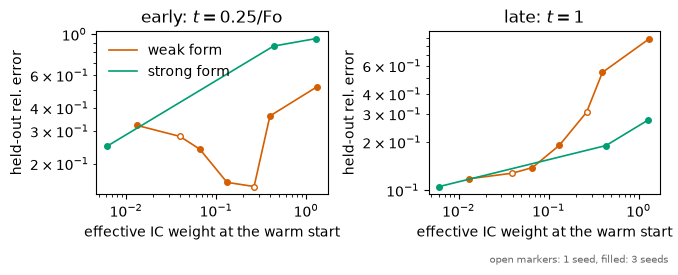

saved H:\My Drive\amorflux\results\paper_figs\fig5_matched.pdf


In [22]:
# %% [M3] Evaluate weak and strong at every IC weight on one axis: effective IC weight = w * ||g_IC|| / ||g_phys||
# (warm start). CPU is fine. Writes results/matched_control_eval.json and results/paper_figs/fig5_matched.png/.pdf
# Paths are hard-coded for the local copy of the Drive folder; run M0 first (it defines the model and data helpers).
import os, json
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = r"H:\My Drive\amorflux"
RES_DIR = os.path.join(ROOT, "results")
DATA_DIR = os.path.join(ROOT, "data")
CKPT_DIR = os.path.join(ROOT, "ckpt")

def ckpt(name):
    """Checkpoint path in the local ckpt folder (tries the usual extensions)."""
    for ext in (".pt", ".pth", ""):
        p = os.path.join(CKPT_DIR, name + ext)
        if os.path.exists(p):
            return p
    return os.path.join(CKPT_DIR, name + ".pt")      # missing: callers check os.path.exists

MEAS = json.load(open(os.path.join(RES_DIR, "matched_control_measure.json")))
_te = f32(np.load(os.path.join(DATA_DIR, "fdm_hold_te.npz"))["t_e"])
_REFS = {"0.25/Fo": (0.25 * _te, f32(np.load(os.path.join(DATA_DIR, "fdm_hold_te025.npz"))["C"])),
         "1/Fo": (_te, f32(np.load(os.path.join(DATA_DIR, "fdm_hold_te.npz"))["C"])),
         "t=1": (torch.ones_like(_te), fdm_C_ho)}

SEEDS3 = (42, 43, 44)
def _load(name):
    m = new_net()
    m.load_state_dict(torch.load(ckpt(name), map_location=dev, weights_only=False)["state_dict"])
    return m

@torch.no_grad()
def _errs(m):
    m.eval(); hs = holdout_tensors[:3]; n = hs[0].shape[0]; out = {}
    for tag, (t, Ct) in _REFS.items():
        c = torch.cat([GRID_EVAL.unsqueeze(0).expand(n, -1, -1), t.view(n, 1, 1).expand(n, GRID_EVAL.shape[0], 1)], -1)
        C = m(*hs, c)[..., 0].view(n, len(fdm_x), len(fdm_y))
        out[tag] = ((C - Ct).flatten(1).norm(dim=1) / Ct.flatten(1).norm(dim=1)).mean().item()
    return out

_sw = sorted({float(f[3:].split("_warm_strong")[0]) for f in os.listdir(CKPT_DIR)
              if f.startswith("icw") and "_warm_strong_s" in f})
_ARMS = ([("weak", 0.0, "warm_weak_noIC_s{s}"), ("weak", 1.0, "warm_weak_s{s}")]
         + [("weak", w, f"icw{w:g}_warm_weak_s{{s}}") for w in (0.01, 0.03, 0.05, 0.1, 0.2, 0.3)]
         + [("strong", 0.0, "warm_strong_noIC_s{s}"), ("strong", 1.0, "warm_strong_s{s}")]
         + [("strong", w, f"icw{w:g}_warm_strong_s{{s}}") for w in _sw])

MATCHED = []
print(f"{'form':<8}{'w':>8}{'eff. wt':>10}{'n':>3}{'0.25/Fo':>10}{'1/Fo':>10}{'t=1':>10}   t=1 range")
for form, w, pat in _ARMS:
    have = [s for s in SEEDS3 if os.path.exists(ckpt(pat.format(s=s)))]
    if not have:
        continue
    per = []
    for s in have:
        m = _load(pat.format(s=s)); per.append(_errs(m)); del m
    flush()
    eff = w * (MEAS["mean_ratio_weak"] if form == "weak" else MEAS["mean_ratio_strong"])
    mean = {t: float(np.mean([p[t] for p in per])) for t in _REFS}
    # key kept as "loudness" so older readers of matched_control_eval.json still work
    MATCHED.append(dict(form=form, w=w, loudness=eff, effective_weight=eff, n=len(have), mean=mean, per_seed=per))
    print(f"{form:<8}{w:>8g}{eff:>10.3g}{len(have):>3}" + "".join(f"{mean[t]:>10.3f}" for t in _REFS)
          + f"   [{min(p['t=1'] for p in per):.3f}-{max(p['t=1'] for p in per):.3f}]")
json.dump(dict(measure=MEAS, rows=MATCHED), open(os.path.join(RES_DIR, "matched_control_eval.json"), "w"), indent=2)
log_result("matched_control", dict(measure=MEAS, rows=MATCHED))

_col = dict(weak="#D55E00", strong="#009E73")
fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.6))
for ax, tag, title in zip(axes, ("0.25/Fo", "t=1"), ("early: $t=0.25/\\mathrm{Fo}$", "late: $t=1$")):
    for form in ("weak", "strong"):
        r = sorted([x for x in MATCHED if x["form"] == form and x["w"] > 0], key=lambda x: x["effective_weight"])
        if not r:
            continue
        ax.plot([x["effective_weight"] for x in r], [x["mean"][tag] for x in r], "-", color=_col[form], lw=1.2,
                label=f"{form} form")
        for x in r:
            ax.plot(x["effective_weight"], x["mean"][tag], "o", color=_col[form], ms=4,
                    mfc=_col[form] if x["n"] >= 3 else "white")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(title)
    ax.set_xlabel("effective IC weight at the warm start"); ax.set_ylabel("held-out rel. error")
axes[0].legend(frameon=False)
fig.text(0.99, -0.03, "open markers: 1 seed, filled: 3 seeds", ha="right", fontsize=7, color="0.4")
fig.tight_layout()
_od = os.path.join(RES_DIR, "paper_figs"); os.makedirs(_od, exist_ok=True)
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(_od, f"fig5_matched.{ext}"), bbox_inches="tight", dpi=200)
plt.show()
print(f"saved {os.path.join(_od, 'fig5_matched.pdf')}")

In [16]:
! cd drive/MyDrive/amorflux && python heat_drift.py --measure --dims 1 2 --out heat_matched --starts results/model_files/heat_clash


=== 1D clash, warm start ===
  seed    ||g_IC||  ||g_phys|| weak  ||g_phys|| strong  IC/phys weak  IC/phys strong         k
    42   2.896e-01        2.225e+00          2.046e+03          0.13        0.000142       920
    43   3.906e-01        1.295e+00          1.311e+03         0.302        0.000298  1.01e+03
    44   2.856e-01        2.153e+00          2.091e+03         0.133        0.000137       971
  k (geometric mean) = 967  -> matched strong-form IC multiplier 970  (IC weight 2910)

=== 1D clash, cold start ===
  seed    ||g_IC||  ||g_phys|| weak  ||g_phys|| strong  IC/phys weak  IC/phys strong         k
    42   5.188e+00        2.070e-04          3.645e-01      2.51e+04            14.2  1.76e+03
    43   5.154e+00        1.155e-04          2.002e-01      4.46e+04            25.7  1.73e+03
    44   4.914e+00        1.729e-05          2.760e-02      2.84e+05             178   1.6e+03
  k (geometric mean) = 1.7e+03  -> matched strong-form IC multiplier 1700  (IC weight 5100)



In [2]:
!cd drive/MyDrive/amorflux && python heat_drift.py --measure --dims 1 2 --inits warm --out heat_matched --starts heat_results/ckpt


=== 1D clash, warm start ===
  seed    ||g_IC||  ||g_phys|| weak  ||g_phys|| strong  IC/phys weak  IC/phys strong         k
    42   2.896e-01        2.225e+00          2.046e+03          0.13        0.000142       920
    43   3.906e-01        1.295e+00          1.311e+03         0.302        0.000298  1.01e+03
    44   2.856e-01        2.153e+00          2.091e+03         0.133        0.000137       971
  k (geometric mean) = 967  -> matched strong-form IC multiplier 970  (IC weight 2910)

=== 2D clash, warm start ===
  seed    ||g_IC||  ||g_phys|| weak  ||g_phys|| strong  IC/phys weak  IC/phys strong         k
    42   1.946e-01        1.360e-02          1.638e+03          14.3        0.000119   1.2e+05
    43   2.986e-01        9.594e-03          1.226e+03          31.1        0.000244  1.28e+05
    44   6.580e-01        1.223e-02          1.483e+03          53.8        0.000444  1.21e+05
  k (geometric mean) = 1.23e+05  -> matched strong-form IC multiplier 120000  (IC weight 3600

In [ ]:
!cd drive/MyDrive/amorflux && python heat_drift.py --matched --dims 1 --inits warm --jobs 3 --out heat_matched --starts heat_results/ckpt
!cd drive/MyDrive/amorflux && python heat_drift.py --matched --dims 2 --inits warm --jobs 3 --out heat_matched --starts heat_results/ckpt

matched strong-form multipliers: d1_warm: x970, d2_warm: x120000
matched strong-form runs: 3 to run, 0 done
  done   d1_clash_warm_strong_ic970_s42 (5.4 min)
  done   d1_clash_warm_strong_ic970_s43 (5.4 min)
  done   d1_clash_warm_strong_ic970_s44 (5.4 min)

=== 1D, compat IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n

=== 1D, clash IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n
warm strong ICx970               0.078 [0.09]   0.065 [0.07]   0.067 [0.08]   0.023 [0.03]   0.029 [0.04]  8.70e-02  8.70e-02  7.65e-04  4.73e+01  3

=== 2D, compat IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0

In [17]:
!cd /content/drive/MyDrive/amorflux && python heat_drift.py --sweep --dims 1 --jobs 18 --out heat_matched --starts heat_results/ckpt

strong-form IC multipliers: x10, x30, x100, x300, x3000, x10000
strong-form IC sweep: 18 to run, 0 done
  done   d1_clash_warm_strong_ic10_s44 (31.4 min)
  done   d1_clash_warm_strong_ic30_s44 (31.4 min)
  done   d1_clash_warm_strong_ic10_s42 (31.5 min)
  done   d1_clash_warm_strong_ic10_s43 (31.5 min)
  done   d1_clash_warm_strong_ic30_s42 (31.5 min)
  done   d1_clash_warm_strong_ic3000_s44 (31.5 min)
  done   d1_clash_warm_strong_ic30_s43 (31.6 min)
  done   d1_clash_warm_strong_ic100_s42 (31.6 min)
  done   d1_clash_warm_strong_ic100_s43 (31.6 min)
  done   d1_clash_warm_strong_ic100_s44 (31.6 min)
  done   d1_clash_warm_strong_ic300_s42 (31.6 min)
  done   d1_clash_warm_strong_ic300_s43 (31.6 min)
  done   d1_clash_warm_strong_ic300_s44 (31.6 min)
  done   d1_clash_warm_strong_ic3000_s42 (31.6 min)
  done   d1_clash_warm_strong_ic3000_s43 (31.6 min)
  done   d1_clash_warm_strong_ic10000_s42 (31.6 min)
  done   d1_clash_warm_strong_ic10000_s43 (31.6 min)
  done   d1_clash_warm_stron

In [18]:
!cd /content/drive/MyDrive/amorflux && python heat_drift.py --sweep --sweep-form weak --dims 1 --jobs 24 --out heat_matched --starts heat_results/ckpt --mults 0.3 0.1 0.03 0.01 0.003 0.001 0.0003 0.0001

weak-form IC multipliers: x0.3, x0.1, x0.03, x0.01, x0.003, x0.001, x0.0003, x0.0001
weak-form IC sweep: 24 to run, 0 done
  done   d1_clash_warm_weak_ic0.3_s43 (23.5 min)
  done   d1_clash_warm_weak_ic0.003_s43 (23.6 min)
  done   d1_clash_warm_weak_ic0.1_s43 (23.8 min)
  done   d1_clash_warm_weak_ic0.003_s42 (23.8 min)
  done   d1_clash_warm_weak_ic0.001_s43 (23.8 min)
  done   d1_clash_warm_weak_ic0.3_s42 (23.9 min)
  done   d1_clash_warm_weak_ic0.03_s42 (23.9 min)
  done   d1_clash_warm_weak_ic0.01_s42 (23.9 min)
  done   d1_clash_warm_weak_ic0.01_s43 (23.9 min)
  done   d1_clash_warm_weak_ic0.0003_s42 (23.9 min)
  done   d1_clash_warm_weak_ic0.0003_s43 (23.9 min)
  done   d1_clash_warm_weak_ic0.0003_s44 (23.9 min)
  done   d1_clash_warm_weak_ic0.0001_s42 (23.9 min)
  done   d1_clash_warm_weak_ic0.0001_s43 (23.9 min)
  done   d1_clash_warm_weak_ic0.0001_s44 (23.9 min)
  done   d1_clash_warm_weak_ic0.3_s44 (24.0 min)
  done   d1_clash_warm_weak_ic0.1_s42 (24.0 min)
  done   d1_clash

In [3]:
! pkill -f heat_drift.py

In [4]:
!cd /content/drive/MyDrive/amorflux && python heat_drift.py --sweep --sweep-form weak --dims 2 --jobs 20 --out heat_matched --starts heat_results/ckpt --mults 0.1 0.01 0.001 0.0001 3e-5 1e-5 3e-6 1e-6

weak-form IC multipliers: x0.1, x0.01, x0.001, x0.0001, x3e-05, x1e-05, x3e-06, x1e-06
weak-form IC sweep: 24 to run, 0 done
  done   d2_clash_warm_weak_ic0.0001_s44 (124.5 min)
  done   d2_clash_warm_weak_ic3e-05_s43 (124.6 min)
  FAILED d2_clash_warm_weak_ic3e-05_s44 (124.6 min) -> logs/d2_clash_warm_weak_ic3e-05_s44.log
  FAILED d2_clash_warm_weak_ic1e-05_s44 (124.6 min) -> logs/d2_clash_warm_weak_ic1e-05_s44.log
  FAILED d2_clash_warm_weak_ic0.1_s44 (124.7 min) -> logs/d2_clash_warm_weak_ic0.1_s44.log
  done   d2_clash_warm_weak_ic0.01_s43 (124.7 min)
  FAILED d2_clash_warm_weak_ic0.001_s43 (124.7 min) -> logs/d2_clash_warm_weak_ic0.001_s43.log
  FAILED d2_clash_warm_weak_ic0.0001_s42 (124.7 min) -> logs/d2_clash_warm_weak_ic0.0001_s42.log
  done   d2_clash_warm_weak_ic1e-05_s42 (124.7 min)
  done   d2_clash_warm_weak_ic3e-06_s43 (124.7 min)
  done   d2_clash_warm_weak_ic0.1_s42 (124.8 min)
  done   d2_clash_warm_weak_ic0.1_s43 (124.8 min)
  done   d2_clash_warm_weak_ic0.01_s42 (12

In [ ]:
!cd /content/drive/MyDrive/amorflux && python heat_drift.py --sweep --sweep-form weak --dims 2 --jobs 5 --out heat_matched --starts heat_results/ckpt --mults 0.1 0.01 0.001 0.0001 3e-5 1e-5 3e-6 1e-6

weak-form IC multipliers: x0.1, x0.01, x0.001, x0.0001, x3e-05, x1e-05, x3e-06, x1e-06
weak-form IC sweep: 5 to run, 19 done


In [1]:
!cd /content/drive/MyDrive/amorflux && bash run.sh

[07:24:35] GPU: NVIDIA A100-SXM4-80GB, 81920 MiB
[07:24:35] CPU cores: 12, RAM: 167 GB, pool: 24
[07:24:35] smoke check (30 iterations, about a minute)
[07:24:40]   passed
[07:24:40] batch started; progress in a100_logs/batch.log

=== 1D, compat IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n

=== 1D, clash IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n
cold strong anneal               0.101 [0.11]   0.260 [0.40]   0.440 [0.66]   0.806 [1.31]   0.906 [1.86]  3.09e-02  3.09e-02  2.65e-02  1.07e+03  3
cold weak anneal                 0.093 [0.12]   0.224 [0.29]   0.322 [0.52]   0.451 [0.90]   0.278 [0.42]  7.89e-02  7.89e-02  1.06e-02  4.04e+02  3
warm strong ICx10        

In [3]:
! cd /content/drive/MyDrive/amorflux && python heat_drift.py --anneal-sweep --case compat --dims 1 2 --jobs 24 --retries 2 --out heat_matched --starts heat_results/ckpt

annealed IC weight (Wang et al. 2021): 24 to run, 0 done, up to 24 at once
  done   d1_compat_warm_weak_anneal_s43 (14.0 min)
  done   d1_compat_warm_weak_anneal_s44 (14.0 min)
  done   d1_compat_warm_weak_anneal_s42 (14.1 min)
  done   d2_compat_warm_weak_anneal_s44 (14.9 min)
  done   d2_compat_warm_weak_anneal_s43 (15.0 min)
  done   d2_compat_warm_weak_anneal_s42 (15.1 min)
  done   d1_compat_warm_strong_anneal_s42 (17.3 min)
  done   d1_compat_warm_strong_anneal_s43 (17.3 min)
  done   d1_compat_warm_strong_anneal_s44 (17.5 min)
  done   d1_compat_cold_weak_anneal_s42 (19.2 min)
  done   d1_compat_cold_weak_anneal_s43 (19.2 min)
  done   d1_compat_cold_weak_anneal_s44 (19.2 min)
  done   d2_compat_cold_weak_anneal_s43 (20.1 min)
  done   d2_compat_cold_weak_anneal_s44 (20.3 min)
  done   d2_compat_cold_weak_anneal_s42 (20.3 min)
  done   d1_compat_cold_strong_anneal_s44 (22.0 min)
  done   d1_compat_cold_strong_anneal_s43 (22.1 min)
  done   d1_compat_cold_strong_anneal_s42 (22.3 

In [5]:
! cd /content/drive/MyDrive/amorflux && python anneal_weights.py --out heat_matched

run                                      final IC weight  x default (3)   history (step: weight)
d1_clash_cold_strong_anneal_s42                5.218e+07       1.74e+07   0:1.9e+02  3000:7.5e+05  6000:4.6e+06  9000:1.4e+06  12000:4.8e+07  15000:5.2e+07  15000:5.2e+07
d1_clash_cold_strong_anneal_s43                7.307e+07       2.44e+07   0:1.1e+02  3000:4.1e+05  6000:1.8e+07  9000:1.9e+05  12000:1.9e+09  15000:7.3e+07  15000:7.3e+07
d1_clash_cold_strong_anneal_s44                5.559e+07       1.85e+07   0:18  3000:6.6e+06  6000:6.8e+06  9000:2.8e+06  12000:2.6e+06  15000:5.6e+07  15000:5.6e+07
d1_clash_cold_weak_anneal_s42                  1.724e+03            575   0:0.4  3000:9.4e+02  6000:2.9e+03  9000:1.9e+02  12000:2e+03  15000:1.7e+03  15000:1.7e+03
d1_clash_cold_weak_anneal_s43                  7.369e+02            246   0:0.35  3000:4.7e+02  6000:9.2e+02  9000:1.4e+02  12000:1e+04  15000:7.4e+02  15000:7.4e+02
d1_clash_cold_weak_anneal_s44                  3.145e+02        

In [2]:
! cd drive/MyDrive/amorflux && python run_mesh.py

--dims 1 --out heat_mesh --starts heat_results/ckpt --measure --inits warm --n-el 4 --D 10
--dims 1 --out heat_mesh --starts heat_results/ckpt --measure --inits warm --n-el 8 --D 10
--dims 1 --out heat_mesh --starts heat_results/ckpt --measure --inits warm --n-el 16 --D 10
--dims 1 --out heat_mesh --starts heat_results/ckpt --measure --inits warm --n-el 32 --D 10
k per mesh: 4: 210, 8: 560, 16: 970, 32: 3200
start: --dims 1 --out heat_mesh --starts heat_results/ckpt --sweep --sweep-form strong --mults 210 560 3200 --jobs 12 --retries 1
start: --dims 1 --out heat_mesh --starts heat_results/ckpt --sweep --sweep-form weak --mults 1 --n-el 4 --jobs 12 --retries 1
start: --dims 1 --out heat_mesh --starts heat_results/ckpt --sweep --sweep-form weak --mults 1 --n-el 8 --jobs 12 --retries 1
start: --dims 1 --out heat_mesh --starts heat_results/ckpt --sweep --sweep-form weak --mults 1 --n-el 32 --jobs 12 --retries 1
finished strong.log
finished weak_e4.log
finished weak_e8.log
finished weak_e32

In [5]:
! cd drive/MyDrive/amorflux && python run_final.py


=== STAGE A: normalization ===
  --inits warm --out heat_final --starts heat_results/ckpt --D 10 --n-el 4 --normalize
  --inits warm --out heat_final --starts heat_results/ckpt --D 10 --n-el 8 --normalize
  --inits warm --out heat_final --starts heat_results/ckpt --D 10 --n-el 16 --normalize
  --inits warm --out heat_final --starts heat_results/ckpt --D 10 --n-el 32 --normalize
k_norm per mesh: 4: 13, 8: 8.8, 16: 3.8, 32: 3.1
  start: --sweep --sweep-form weak --mults 1 --n-el 4 --normalize --jobs 3 --dims 1 --out heat_final --starts heat_results/ckpt --retries 1
  start: --sweep --sweep-form weak --mults 1 --n-el 8 --normalize --jobs 3 --dims 1 --out heat_final --starts heat_results/ckpt --retries 1
  start: --sweep --sweep-form weak --mults 1 --n-el 16 --normalize --jobs 3 --dims 1 --out heat_final --starts heat_results/ckpt --retries 1
  start: --sweep --sweep-form weak --mults 1 --n-el 32 --normalize --jobs 3 --dims 1 --out heat_final --starts heat_results/ckpt --retries 1
  start

In [4]:
! cd drive/MyDrive/amorflux && python heat_drift.py --ramp-batch --ramp 0.01 --smoke --out ramp_smoke

supervised starts: 3 to run, 0 done, up to 6 at once
  done   d1ramp0.01_clash_start_s42 (0.3 min)
  done   d1ramp0.01_clash_start_s43 (0.3 min)
  done   d1ramp0.01_clash_start_s44 (0.3 min)
default weights: 6 to run, 0 done, up to 6 at once
  done   d1ramp0.01_clash_warm_weak_ic1_s42 (0.2 min)
  done   d1ramp0.01_clash_warm_weak_ic1_s43 (0.2 min)
  done   d1ramp0.01_clash_warm_weak_ic1_s44 (0.2 min)
  done   d1ramp0.01_clash_warm_strong_ic1_s42 (0.2 min)
  done   d1ramp0.01_clash_warm_strong_ic1_s43 (0.2 min)
  done   d1ramp0.01_clash_warm_strong_ic1_s44 (0.2 min)

=== 1D, compat IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n

=== 1D, clash IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band     

In [6]:
! cd drive/MyDrive/amorflux && python heat_drift.py --ramp-batch --ramp 0.01 --jobs 12 --retries 2 --out heat_ramp001 

supervised starts: 3 to run, 0 done, up to 12 at once
  done   d1ramp0.01_clash_start_s42 (0.5 min)
  done   d1ramp0.01_clash_start_s43 (0.5 min)
  done   d1ramp0.01_clash_start_s44 (0.5 min)
default weights: 6 to run, 0 done, up to 12 at once
  done   d1ramp0.01_clash_warm_weak_ic1_s42 (3.8 min)
  done   d1ramp0.01_clash_warm_weak_ic1_s43 (3.8 min)
  done   d1ramp0.01_clash_warm_weak_ic1_s44 (3.8 min)
  done   d1ramp0.01_clash_warm_strong_ic1_s43 (5.5 min)
  done   d1ramp0.01_clash_warm_strong_ic1_s44 (5.5 min)
  done   d1ramp0.01_clash_warm_strong_ic1_s42 (5.6 min)

=== 1D, compat IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n

=== 1D, clash IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band   

In [2]:
! cd drive/MyDrive/amorflux && python heat_drift.py --measure --dims 1 --inits warm --D 100 --out heat_k100 --starts heat_results/ckpt


=== 1D clash, warm start ===
  seed    ||g_IC||  ||g_phys|| weak  ||g_phys|| strong  IC/phys weak  IC/phys strong         k
    42   2.098e-01        1.127e+00          2.467e+03         0.186         8.5e-05  2.19e+03
    43   3.173e-01        7.347e-01          1.554e+03         0.432        0.000204  2.12e+03
    44   2.009e-01        1.097e+00          2.482e+03         0.183        8.09e-05  2.26e+03
  k (geometric mean) = 2.19e+03  -> matched strong-form IC multiplier 2200  (IC weight 6600)
  k with the weak residual divided by the element measure (0.0625): 8.55  (a constant factor, so this equals turning the weak IC weight down by 256)

saved heat_k100/matched_measure.json


In [4]:
import subprocess

base = [
    "python", "heat_drift.py",
    "--measure",
    "--dims", "1",
    "--inits", "warm",
    "--D", "100",
    "--out", "heat_k100",
    "--starts", "heat_results/ckpt",
]

for n in (4, 8, 32):
    cmd = base + ["--n-el", str(n)]
    print("RUN:", " ".join(map(str, cmd)))
    subprocess.run(cmd, cwd=ROOT, check=True)

for p in (2, 4, 10):
    cmd = base + ["--p-deg", str(p)]
    print("RUN:", " ".join(map(str, cmd)))
    subprocess.run(cmd, cwd=ROOT, check=True)

RUN: python heat_drift.py --measure --dims 1 --inits warm --D 100 --out heat_k100 --starts heat_results/ckpt --n-el 4
RUN: python heat_drift.py --measure --dims 1 --inits warm --D 100 --out heat_k100 --starts heat_results/ckpt --n-el 8
RUN: python heat_drift.py --measure --dims 1 --inits warm --D 100 --out heat_k100 --starts heat_results/ckpt --n-el 32
RUN: python heat_drift.py --measure --dims 1 --inits warm --D 100 --out heat_k100 --starts heat_results/ckpt --p-deg 2
RUN: python heat_drift.py --measure --dims 1 --inits warm --D 100 --out heat_k100 --starts heat_results/ckpt --p-deg 4
RUN: python heat_drift.py --measure --dims 1 --inits warm --D 100 --out heat_k100 --starts heat_results/ckpt --p-deg 10


In [3]:
! cd drive/MyDrive/amorflux && python heat_drift.py --sweep --dims 1 --jobs 33 --retries 2 --out heat_k100_runs --starts heat_results/ckpt --mults 490 940 1300 1600 2200 3400 7100 30 20 8.6 6.9

strong-form IC multipliers: x490, x940, x1300, x1600, x2200, x3400, x7100, x30, x20, x8.6, x6.9
strong-form IC sweep: 33 to run, 0 done, up to 33 at once
  done   d1_clash_warm_strong_ic20_s43 (17.3 min)
  done   d1_clash_warm_strong_ic940_s42 (17.7 min)
  done   d1_clash_warm_strong_ic1300_s43 (17.7 min)
  done   d1_clash_warm_strong_ic1300_s44 (17.7 min)
  done   d1_clash_warm_strong_ic30_s43 (17.7 min)
  done   d1_clash_warm_strong_ic30_s44 (17.7 min)
  done   d1_clash_warm_strong_ic490_s42 (17.8 min)
  done   d1_clash_warm_strong_ic490_s43 (17.8 min)
  done   d1_clash_warm_strong_ic490_s44 (17.8 min)
  done   d1_clash_warm_strong_ic940_s44 (17.8 min)
  done   d1_clash_warm_strong_ic1300_s42 (17.8 min)
  done   d1_clash_warm_strong_ic7100_s43 (17.8 min)
  done   d1_clash_warm_strong_ic20_s42 (17.8 min)
  done   d1_clash_warm_strong_ic8.6_s43 (17.8 min)
  done   d1_clash_warm_strong_ic8.6_s44 (17.8 min)
  done   d1_clash_warm_strong_ic6.9_s42 (17.8 min)
  done   d1_clash_warm_strong_

In [6]:
! cd drive/MyDrive/amorflux && python heat_drift.py --sweep --dims 1 --adv 1 --jobs 6 --out heat_adv --starts heat_adv/ckpt --mults 2000 && python heat_drift.py --sweep --sweep-form weak --dims 1 --adv 1 --jobs 6 --out heat_adv --starts heat_adv/ckpt --mults 5e-4

strong-form IC multipliers: x2000
strong-form IC sweep: 3 to run, 0 done, up to 6 at once
  done   d1adv1_clash_warm_strong_ic2000_s42 (3.6 min)
  done   d1adv1_clash_warm_strong_ic2000_s43 (3.6 min)
  done   d1adv1_clash_warm_strong_ic2000_s44 (3.6 min)

=== 1D, compat IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n
start                            0.009 [0.01]   0.014 [0.01]   0.020 [0.02]   0.015 [0.02]   0.045 [0.05]  4.63e-04  4.63e-04  8.53e-04  1.28e+00  3
warm weak ICon                   0.008 [0.01]   0.020 [0.03]   0.021 [0.03]   0.021 [0.03]   0.073 [0.13]  3.65e-05  3.65e-05  1.01e-04  4.06e-01  3
warm strong ICon                 0.049 [0.06]   0.034 [0.05]   0.026 [0.04]   0.020 [0.03]   0.031 [0.05]  4.79e-03  4.79e-03  1.21e-06  3.42e-03  3
warm strong ICx1000              0.005 [0.01]   0.011 [0.01]   0.009 [0.01

In [8]:
! cd drive/MyDrive/amorflux && python heat_drift.py --summary --out heat_final


=== 1D, compat IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n

=== 1D, clash IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n
warm strong ICx3.1               0.176 [0.22]   0.075 [0.13]   0.040 [0.08]   0.007 [0.01]   0.003 [0.00]  3.25e-01  3.25e-01  3.69e-05  1.34e-01  3
warm strong ICx3.8               0.164 [0.19]   0.063 [0.10]   0.030 [0.06]   0.006 [0.01]   0.003 [0.00]  3.08e-01  3.08e-01  4.06e-05  1.56e-01  3
warm strong ICx8.8               0.151 [0.15]   0.048 [0.05]   0.016 [0.02]   0.005 [0.01]   0.004 [0.01]  2.89e-01  2.89e-01  3.72e-05  2.26e-01  3
warm strong ICx13                0.147 [0.15]   0.047 [0.05]   0.016 [0.02]   0.006 [0.01]   0.005 [0.01] 

In [3]:
!cd /content/drive/MyDrive/amorflux && python heat_drift.py --extra-seeds --arms warm cold --dims 2 --jobs 30 --out heat_results


extra seeds (warm, cold), seeds 42-51: 14 to run, 6 done, up to 30 at once
  done   d2_clash_warm_weak_ic1_s48 (7.4 min)
  done   d2_clash_warm_weak_ic1_s49 (7.4 min)
  done   d2_clash_warm_weak_ic1_s50 (7.4 min)
  done   d2_clash_warm_weak_ic1_s45 (7.5 min)
  done   d2_clash_warm_weak_ic1_s46 (7.5 min)
  done   d2_clash_warm_weak_ic1_s47 (7.5 min)
  done   d2_clash_warm_weak_ic1_s51 (7.5 min)
  done   d2_clash_cold_weak_ic1_s45 (9.2 min)
  done   d2_clash_cold_weak_ic1_s47 (9.2 min)
  done   d2_clash_cold_weak_ic1_s46 (9.3 min)
  done   d2_clash_cold_weak_ic1_s49 (9.3 min)
  done   d2_clash_cold_weak_ic1_s50 (9.3 min)
  done   d2_clash_cold_weak_ic1_s51 (9.3 min)
  done   d2_clash_cold_weak_ic1_s48 (9.3 min)

=== 1D, compat IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n
start                            0.004 [0.00]   0.004 [0.

In [4]:
!cd /content/drive/MyDrive/amorflux && python heat_drift.py --extra-seeds --arms dual --dims 2 --jobs 30 --out gm_heat_results --starts heat_results/ckpt


extra seeds (dual), seeds 42-51: 7 to run, 3 done, up to 30 at once
  done   d2_clash_warm_weak_ic1_dual_s45 (3.8 min)
  done   d2_clash_warm_weak_ic1_dual_s47 (3.8 min)
  done   d2_clash_warm_weak_ic1_dual_s48 (3.8 min)
  done   d2_clash_warm_weak_ic1_dual_s49 (3.8 min)
  done   d2_clash_warm_weak_ic1_dual_s50 (3.8 min)
  done   d2_clash_warm_weak_ic1_dual_s51 (3.8 min)
  done   d2_clash_warm_weak_ic1_dual_s46 (3.8 min)

=== 1D, compat IC  (transient rel. error, mean over seeds [max]) ===
arm                                     t=0.01          t=0.05           t=0.1           t=0.3           t=1.0        ic   ic_band      weak    strong  n
start                            0.004 [0.00]   0.004 [0.00]   0.003 [0.00]   0.003 [0.00]   0.016 [0.02]  2.61e-05  2.61e-05  1.58e-05  2.95e-02  3
warm weak ICon DUAL              0.000 [0.00]   0.000 [0.00]   0.000 [0.00]   0.000 [0.00]   0.002 [0.00]  7.84e-08  7.84e-08  1.78e-07  3.67e-04  3

=== 1D, clash IC  (transient rel. error, mean over s

In [3]:
! cd drive/MyDrive/amorflux && python bench_cost.py

device: NVIDIA A100-SXM4-80GB
1D strong: 19.14 ms/step, 1280 points, peak 128 MB, warm run 3.2 min, cold run 4.8 min
1D weak  : 12.27 ms/step, 1280 points, peak 93 MB, warm run 2.0 min, cold run 3.1 min
1D dual  : 13.17 ms/step, 1280 points, peak 93 MB, warm run 2.2 min, cold run 3.3 min
1D kappa measurement (D = 100): 2.7 s
2D strong: 30.80 ms/step, 16000 points, peak 1267 MB, warm run 5.1 min, cold run 7.7 min
2D weak  : 14.36 ms/step, 16000 points, peak 396 MB, warm run 2.4 min, cold run 3.6 min
2D dual  : 14.75 ms/step, 16000 points, peak 396 MB, warm run 2.5 min, cold run 3.7 min
2D kappa measurement (D = 100): 3.9 s
wrote heat_runs/cost/cost.json and heat_runs/cost/cost_table.tex


In [3]:
! cd drive/MyDrive/amorflux && python heat_drift.py --measure --dims 2 --inits warm --D 100 --out heat_k100_2d --starts heat_results/ckpt


=== 2D clash, warm start ===
  seed    ||g_IC||  ||g_phys|| weak  ||g_phys|| strong  IC/phys weak  IC/phys strong         k
    42   1.683e-01        7.996e-03          1.713e+03          21.1        9.83e-05  2.14e+05
    43   2.444e-01        5.567e-03          1.268e+03          43.9        0.000193  2.28e+05
    44   5.504e-01        7.463e-03          1.540e+03          73.7        0.000357  2.06e+05
  k (geometric mean) = 2.16e+05  -> matched strong-form IC multiplier 220000  (IC weight 660000)
  k with the weak residual divided by the element measure (0.0156): 52.7  (a constant factor, so this equals turning the weak IC weight down by 4.1e+03)

saved heat_k100_2d/matched_measure.json


In [4]:
! cd drive/MyDrive/amorflux && python align_measure.py --case compat

1D compat warm s42: cos(weak,strong) 1.000  cos(IC,weak) 0.398  Gamma 0.611  (h/ell)^2 0.417  h/ell median 0.66, p90 3.45
1D compat warm s43: cos(weak,strong) 1.000  cos(IC,weak) 0.069  Gamma 0.649  (h/ell)^2 0.383  h/ell median 0.663, p90 3.3
1D compat warm s44: cos(weak,strong) 1.000  cos(IC,weak) 0.218  Gamma 0.602  (h/ell)^2 0.329  h/ell median 0.632, p90 2.88
2D compat warm s42: cos(weak,strong) 1.000  cos(IC,weak) 0.668  Gamma 0.449  (h/ell)^2 1.48  h/ell median 1.32, p90 5.08
2D compat warm s43: cos(weak,strong) 0.999  cos(IC,weak) 0.710  Gamma 0.553  (h/ell)^2 2.26  h/ell median 1.52, p90 8.07
2D compat warm s44: cos(weak,strong) 1.000  cos(IC,weak) 0.458  Gamma 0.414  (h/ell)^2 1.41  h/ell median 1.3, p90 5.86
saved heat_align/align_compat.json


In [5]:
! cd drive/MyDrive/amorflux && python heat_drift.py --measure --dims 1 2 --inits warm cold --D 100 --out heat_k100_all --starts heat_results/ckpt
! cd drive/MyDrive/amorflux && python heat_drift.py --measure --dims 1 2 --case compat --inits warm --D 100 --out heat_k100_all --starts heat_results/ckpt
! cd drive/MyDrive/amorflux && python heat_drift.py --measure --ramp 0.01 --dims 1 --inits warm --D 100 --out heat_ramp001_k100 --starts heat_ramp001/ckpt
! cd drive/MyDrive/amorflux && python heat_drift.py --measure --ramp 0.05 --dims 1 --inits warm --D 100 --out heat_ramp005_k100 --starts heat_ramp005/ckpt


=== 1D clash, warm start ===
  seed    ||g_IC||  ||g_phys|| weak  ||g_phys|| strong  IC/phys weak  IC/phys strong         k
    42   2.098e-01        1.127e+00          2.467e+03         0.186         8.5e-05  2.19e+03
    43   3.173e-01        7.347e-01          1.554e+03         0.432        0.000204  2.12e+03
    44   2.009e-01        1.097e+00          2.482e+03         0.183        8.09e-05  2.26e+03
  k (geometric mean) = 2.19e+03  -> matched strong-form IC multiplier 2200  (IC weight 6600)
  k with the weak residual divided by the element measure (0.0625): 8.55  (a constant factor, so this equals turning the weak IC weight down by 256)

=== 1D clash, cold start ===
  seed    ||g_IC||  ||g_phys|| weak  ||g_phys|| strong  IC/phys weak  IC/phys strong         k
    42   5.236e+00        2.043e-04          3.647e-01      2.56e+04            14.4  1.79e+03
    43   5.202e+00        1.130e-04          2.007e-01      4.61e+04            25.9  1.78e+03
    44   4.960e+00        1.593e-